# Del dato abierto al dashboard
## Diseño de un pipeline de datos reproducible con Python y Power BI

**Actividad de Enseñanza, Aprendizaje y Evaluación (AEAE) — Notebook de trabajo**

| Campo | Diligenciar  |
|---|---|
| **Actividad** | Del dato abierto al dashboard: pipeline de datos reproducible con Python y Power BI |
| **Curso** | Visualización de Datos |
| **Programa** | Ingeniería de Datos y Software — Universidad de San Buenaventura, Medellín |
| **Docente** | Luis Fernando Sánchez Pérez |
| **Estudiante(s)** |  Julian Gómez Posada 30000062697 - Andrea Michel Suarez Vélez - 30000134716 |
| **Equipo** |  |
| **Nivel asignado** |  3 — Avanzado |
| **Fecha** |  2026-10-07 |
| **Fuente seleccionada** |  Tasas de interés activas por tipo de crédito Últimos dos meses — Gov.co — https://www.datos.gov.co/Econom-a-y-Finanzas/Tasas-de-inter-s-activas-por-tipo-de-cr-dito-ltimo/qzsc-9esp/about_data |

> **Cómo leer este notebook.** No es un script para ejecutar de corrido: es una guía de aprendizaje.
> Cada bloque repite el ciclo **Contexto → Reto → Plantilla → Explicación → Evidencia → Pregunta de reflexión**.
> Las líneas marcadas con **EDITAR** son las que usted debe adaptar a su fuente. Las celdas que empiezan por **** son para escribir sus respuestas.

## Bloque 2 · Competencias y resultados de aprendizaje

**Competencias que se desarrollan**

- **C1 — Ingeniería de datos.** Diseña e implementa procesos ETL reproducibles que transforman datos abiertos crudos en datasets curados, aplicando perfilamiento, gestión de metadatos y dimensiones de calidad del dato (DAMA-DMBOK; ISO/IEC 25012).
- **C2 — Visualización y BI.** Construye modelos de datos y dashboards en Power BI que responden preguntas de negocio explícitas.
- **C3 — Pensamiento crítico y comunicación.** Justifica decisiones técnicas, reconoce sesgos y limitaciones, y comunica hallazgos con evidencia verificable.

**Resultados de aprendizaje**

| RA | Al terminar, usted será capaz de… | Bloques |
|---|---|---|
| RA1 | Seleccionar y justificar una fuente abierta según licencia, procedencia, volumen y utilidad | 4 |
| RA2 | Perfilar un dataset de gran volumen con pandas y documentar su estado inicial | 5, 6, 7 |
| RA3 | Construir un catálogo con metadatos técnicos y semánticos | 9 |
| RA4 | Diagnosticar la calidad con reglas medibles y tratar los problemas de forma justificada | 8, 10, 12 |
| RA5 | Implementar y validar un pipeline ETL reproducible y escalable | 11, 13, 14, 15 |
| RA6 | Preparar y comunicar los datos en Power BI a partir de preguntas de negocio | 16, 17 |

**Reglas de trabajo**

1. **Primero conocer, luego limpiar.** Ninguna transformación se hace antes del perfilamiento y el diagnóstico.
2. **Toda transformación se justifica.** Cada cambio queda en el `registro_decisiones` con su razón y los registros afectados.
3. **Los datos crudos no se tocan.** El archivo original se conserva intacto; todo se reconstruye desde él con código.
4. **Reproducible o no cuenta.** Al final, *Entorno de ejecución → Reiniciar y ejecutar todo* debe producir los mismos resultados.

**Modo demostración.** Con `MODO_DEMO = True` (bloque 4) el notebook genera un dataset **sintético y deliberadamente sucio** de solicitudes ciudadanas para que vea qué produce cada bloque. **No es entregable**: el bloque 17 lo verifica.

## Bloque 3 · Configuración del entorno

**🧭 Contexto.** Un pipeline reproducible empieza por un entorno declarado: qué bibliotecas usa, en qué versión y dónde guarda sus archivos.

**🎯 Reto.** Ejecute la celda, anote las versiones de pandas y Python y confirme que la carpeta del proyecto y el archivo crudo son los de su computador.

**📘 Explicación.**
- **El notebook se ejecuta en Jupyter local** (Anaconda, VS Code o `jupyter lab`) y lee el CSV crudo (3,69 GB) **directamente desde el disco del computador**: no se sube a Drive ni se descarga de nuevo en cada sesión. La carpeta del proyecto es la carpeta donde está guardado este notebook.
- Se usan **pandas, numpy y matplotlib**; `pyarrow` escribe Parquet y `python-docx` genera el informe. La celda siguiente instala las que falten.
- Aquí se definen utilidades transversales: `registrar_decision()` (bitácora de transformaciones), `estandarizar_nombre()` y `normalizar_texto()`.

In [22]:
# ============================================================
# BLOQUE 3 (a) · DEPENDENCIAS (solo instala lo que falte)
# ============================================================
import sys, subprocess, importlib.util

PAQUETES = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "pyarrow": "pyarrow", "docx": "python-docx"}
faltan = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
    print("✔ Listo. Si es la primera vez, reinicie el kernel y vuelva a ejecutar desde aquí.")
else:
    print("✔ Todas las bibliotecas están instaladas.")

✔ Todas las bibliotecas están instaladas.


In [23]:
# ============================================================
# BLOQUE 3 · CONFIGURACIÓN DEL ENTORNO
# ============================================================
import sys, re, json, time, zipfile, inspect, unicodedata
import urllib.request, urllib.parse
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

EN_COLAB = "google.colab" in sys.modules

# ✏️ EDITAR (opcional): carpeta del proyecto EN SU COMPUTADOR.
# Vacío = la carpeta donde está guardado este notebook (recomendado).
# Ejemplo Windows: r"C:\Users\Mariana\Documents\Visualizacion de datos"
CARPETA_PROYECTO = r""

if EN_COLAB:
    print("⚠ Este notebook está configurado para Jupyter local: el CSV se lee desde su computador.\n"
          "  En Colab no hay acceso a los archivos del computador; ábralo con Jupyter/VS Code.")
BASE = Path(CARPETA_PROYECTO).expanduser() if CARPETA_PROYECTO else Path.cwd()

DIR_CRUDOS = BASE / "datos" / "crudos"     # datos originales: solo lectura
DIR_SALIDAS = BASE / "salidas"             # dataset curado, catálogo y reportes
for carpeta in (DIR_CRUDOS, DIR_SALIDAS):
    carpeta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

try:
    import pyarrow  # noqa: F401
    PARQUET_DISPONIBLE = True
except ImportError:
    PARQUET_DISPONIBLE = False

MARCA_PENDIENTE = "✏️"   # toda cadena que la contenga se considera "por completar"

# ------------------------------------------------------------
# Bitácora de decisiones: cada transformación deja rastro
# ------------------------------------------------------------
registro_decisiones = []

def reiniciar_registro():
    """Vacía la bitácora (se llama al iniciar cada ejecución del pipeline)."""
    registro_decisiones.clear()

def registrar_decision(paso, columna, accion, justificacion, afectados=0):
    """Agrega una decisión a la bitácora. `afectados` = registros o valores modificados."""
    registro_decisiones.append({
        "orden": len(registro_decisiones) + 1,
        "paso": paso,
        "columna": columna,
        "accion": accion,
        "justificacion": justificacion,
        "afectados": int(afectados),
    })

def ver_registro():
    return pd.DataFrame(registro_decisiones)

# ------------------------------------------------------------
# Utilidades de texto y memoria
# ------------------------------------------------------------
def quitar_tildes(texto):
    texto = unicodedata.normalize("NFKD", texto)
    return "".join(c for c in texto if not unicodedata.combining(c))

def estandarizar_nombre(nombre):
    """'Costo Atención (COP)' -> 'costo_atencion_cop' (snake_case, sin tildes)."""
    s = quitar_tildes(str(nombre)).lower()
    s = re.sub(r"[^a-z0-9]+", "_", s).strip("_")
    if not s:
        s = "columna"
    if s[0].isdigit():
        s = "c_" + s
    return s

def normalizar_texto(valor):
    """Clave de comparación: sin espacios extremos, MAYÚSCULAS, sin tildes, espacios simples."""
    if not isinstance(valor, str):
        return valor
    return re.sub(r"\s+", " ", quitar_tildes(valor.strip().upper()))

def es_texto(serie):
    """True si la columna es de texto (object en pandas 2, str en pandas 3) o categórica."""
    return (serie.dtype == object or isinstance(serie.dtype, pd.StringDtype)
            or isinstance(serie.dtype, pd.CategoricalDtype))

def medir_memoria_mb(df):
    return df.memory_usage(deep=True).sum() / 1024 ** 2

def fmt(n):
    """Formato de miles para reportes: 1234567 -> '1.234.567'."""
    return f"{n:,.0f}".replace(",", ".")

print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · numpy {np.__version__}")
print(f"Entorno: {'Google Colab' if EN_COLAB else 'Jupyter local'} · Parquet disponible: {PARQUET_DISPONIBLE}")
print(f"Carpeta del proyecto: {BASE.resolve()}")

Python 3.11.9 · pandas 3.0.5 · numpy 2.4.6
Entorno: Jupyter local · Parquet disponible: True
Carpeta del proyecto: C:\Users\Michell\Desktop\U_2026_2\visualizacion_datos


**✅ Evidencia.** La salida muestra versiones de Python y pandas, el entorno y la carpeta del proyecto.

**💭 Pregunta de reflexión.** ¿Por qué registrar las versiones de las bibliotecas forma parte de la reproducibilidad de un pipeline?

✍️ *Respuesta:* porque el mismo código puede dar resultados distintos con otra versión. Por ejemplo, pandas 3 lee el texto como `str` y pandas 2 como `object`; `groupby` cambió su comportamiento con las categorías; `read_csv` infiere tipos de otra forma. Registrar las versiones (Python, pandas, numpy) permite reconstruir el entorno exacto, explicar diferencias si otro equipo obtiene otra cifra y demostrar que el pipeline es reproducible y no un resultado accidental de la máquina en que se ejecutó.

## Bloque 4 · Definición de la fuente (Fase 1 — Evidencia E1)

**🧭 Contexto.** Antes de descargar un solo registro hay que saber **quién produce el dato, con qué licencia y para qué**. Esa información es parte de los metadatos y condiciona todo el análisis.

**🎯 Reto.**
1. Cambie `MODO_DEMO` a `False` cuando tenga su fuente aprobada.
2. Complete `URL_DATOS`, `NOMBRE_ARCHIVO`, `FORMATO` y los parámetros de lectura.
3. Diligencie `FICHA_FUENTE` (17 campos), `CRITERIOS_FUENTE` (10 criterios) y `PREGUNTAS_NEGOCIO` (5 a 8).

**📘 Explicación — niveles y estrategia de lectura.**

| Nivel | Fuente | Estrategia de carga esperada |
|---|---|---|
| 1 — Básico | 250 mil a 1 millón de registros | Lectura completa con `usecols` (solo columnas útiles) |
| 2 — Intermedio | ≥ 1 millón de registros | `usecols` + optimización de tipos (`category`, enteros reducidos) y medición de memoria |
| 3 — Avanzado | Varios millones o varios archivos | Lectura por `chunksize`, **filtrado temprano**, procesamiento incremental y Parquet |

Un millón de registros **no es necesariamente Big Data**: cabe en la memoria de un portátil. Pero basta para que aparezcan problemas reales de rendimiento, memoria y eficiencia que nunca se ven con datasets de juguete.

- `COLUMNA_ID` y `COLUMNA_FECHA_PRINCIPAL` se escriben con el **nombre estandarizado** (snake_case, sin tildes), porque así se llamarán después de la limpieza.
- Si su fuente tiene códigos con ceros a la izquierda (DIVIPOLA, NIT, códigos postales), declárelos como texto en `DTYPE_LECTURA` para no perder información.

In [24]:
# ============================================================
# BLOQUE 4 · PARÁMETROS DE LA FUENTE              ✏️ EDITAR
# ============================================================
MODO_DEMO = False           # @param {type:"boolean"}   ← False para trabajar con su fuente real
NIVEL = 3                   # @param [1, 2, 3] {type:"raw"}

URL_DATOS = "https://www.datos.gov.co/Econom-a-y-Finanzas/Tasas-de-inter-s-activas-por-tipo-de-cr-dito-ltimo/qzsc-9esp"   # solo referencia de la fuente: el archivo se lee del computador

# ✏️ RUTA COMPLETA DEL CSV EN SU COMPUTADOR (clic derecho sobre el archivo → "Copiar como ruta" y pegar entre las comillas).
# El archivo NO se copia ni se modifica: se lee en su ubicación (datos crudos = solo lectura).
# Vacío = se busca en la subcarpeta datos/crudos del proyecto.
RUTA_CSV_LOCAL = ""  # Vacío = buscar el archivo en datos/crudos.
NOMBRE_ARCHIVO = "Tasas_de_interés_activas_por_tipo_de_crédito_–_Últimos_dos_meses_20261007.csv"         # @param {type:"string"}    ✏️ nombre con el que se guarda el archivo crudo
FORMATO = "csv"             # @param ["csv", "zip", "json", "excel", "parquet", "api"]

SEPARADOR = ","             # ✏️ ";" en muchos CSV exportados con configuración regional en español
CODIFICACION = "utf-8"      # ✏️ "latin-1" si aparecen caracteres extraños (Ã±, Ã³)
COLUMNAS_A_USAR = None      # ✏️ lista de columnas ORIGINALES a leer; None = todas
DTYPE_LECTURA = {"Codigo_CIIU": "string","Codigo_Municipio": "string"}        # ✏️ p. ej. {"Código DANE": "string"} para preservar ceros a la izquierda
MUESTRA_FILAS = None        # ✏️ p. ej. 200_000 para pruebas rápidas; None = todo el archivo
TAMANO_CHUNK = 500_000      # filas por bloque en lectura incremental (nivel 3)
FRACCION_MUESTRA = 0.22     # ✏️ nivel 3: fracción aleatoria que se conserva de CADA bloque (≈ 2,5 M de 11,5 M filas)
SEMILLA_MUESTRA = 42        # semilla fija: la misma muestra en cada ejecución (reproducibilidad)
ARCHIVO_EN_ZIP = None       # ✏️ nombre del archivo dentro del ZIP si este contiene varios
API_PARAMETROS = {          # ✏️ solo si FORMATO == "api" (portales Socrata: datos.gov.co, NYC, Chicago)
    "limite_pagina": 50_000,
    "max_registros": 1_000_000,
    "select": None,          # p. ej. "fecha, municipio, valor"
    "where": None,           # p. ej. "fecha >= '2023-01-01T00:00:00'"
    "app_token": None,       # opcional: token gratuito del portal para evitar límites
}

COLUMNA_ID = ""               # ✏️ nombre estandarizado del identificador (si existe)
COLUMNA_FECHA_PRINCIPAL = "fecha_corte"  # ✏️ nombre ESTANDARIZADO (PC2: antes decía "Fecha_Corte", que no existe tras la limpieza)
FECHA_CORTE = "2026-10-07"  # ✏️ "AAAA-MM-DD" de la descarga; vacío = se toma del nombre del archivo (…_AAAAMMDD.csv) o de su fecha de modificación

if MODO_DEMO:
    NOMBRE_ARCHIVO = "solicitudes_ciudadanas_demo.csv"
    FORMATO = "csv"
    COLUMNA_ID = "id_solicitud"
    COLUMNA_FECHA_PRINCIPAL = "fecha_apertura"
    FECHA_CORTE = "2025-12-31"

# ------------------------------------------------------------
# Ubicación del archivo crudo en el computador
# ------------------------------------------------------------
if MODO_DEMO:
    RUTA_CRUDO = DIR_CRUDOS / NOMBRE_ARCHIVO
elif RUTA_CSV_LOCAL.strip():
    RUTA_CRUDO = Path(RUTA_CSV_LOCAL.strip().strip('"')).expanduser()
    NOMBRE_ARCHIVO = RUTA_CRUDO.name
elif (DIR_CRUDOS / NOMBRE_ARCHIVO).exists():
    RUTA_CRUDO = DIR_CRUDOS / NOMBRE_ARCHIVO
else:
    candidatos = sorted(DIR_CRUDOS.glob("Tasas*.csv")) or sorted(DIR_CRUDOS.glob("*.csv"))
    RUTA_CRUDO = candidatos[-1] if candidatos else DIR_CRUDOS / NOMBRE_ARCHIVO
    NOMBRE_ARCHIVO = RUTA_CRUDO.name

if not MODO_DEMO and not RUTA_CRUDO.exists():
    raise FileNotFoundError(
        f"No encuentro el CSV en: {RUTA_CRUDO}\n"
        "→ Pegue la ruta completa del archivo en RUTA_CSV_LOCAL (clic derecho → 'Copiar como ruta'),\n"
        f"  o copie el CSV a la carpeta {DIR_CRUDOS}")

if not FECHA_CORTE:
    m = re.search(r"(20\d{2})(\d{2})(\d{2})", RUTA_CRUDO.stem)
    FECHA_CORTE = ("-".join(m.groups()) if m
                   else datetime.fromtimestamp(RUTA_CRUDO.stat().st_mtime).strftime("%Y-%m-%d"))
print(f"Modo demo: {MODO_DEMO} · Nivel: {NIVEL} · Formato: {FORMATO}")
print(f"Archivo crudo: {RUTA_CRUDO}" + (f" ({RUTA_CRUDO.stat().st_size / 1024**3:,.2f} GB)" if RUTA_CRUDO.exists() else ""))
print(f"Fecha de corte: {FECHA_CORTE}")

Modo demo: False · Nivel: 3 · Formato: csv
Archivo crudo: C:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\Tasas_de_interés_activas_por_tipo_de_crédito_–_Últimos_dos_meses_20261007.csv (3.69 GB)
Fecha de corte: 2026-10-07


In [25]:
# ============================================================
# BLOQUE 4 · FICHA DE LA FUENTE (Evidencia E1)     ✏️ EDITAR
# ============================================================
FICHA_FUENTE = {
    "nombre_fuente": "Gov.co",
    "organizacion_responsable": "Superintendencia Financiera de Colombia - SUPERFINANCIERA, Bogotá D.C.",
    "url": "https://www.datos.gov.co/Econom-a-y-Finanzas/Tasas-de-inter-s-activas-por-tipo-de-cr-dito-ltimo/qzsc-9esp/about_data ",
    "fecha_consulta": "2026-10-07",            # AAAA-MM-DD
    "descripcion": "La información corresponde a las tasas de interés promedio ponderadas, el monto y el número de créditos desembolsados durante la semana para los diferentes tipos de crédito (consumo, vivienda, comercial ordinario, comercial preferencial o corporativo, comercial tesorería, comercial especial y créditos productivos), clasificadas por tipo de persona, sexo, tamaño de empresa, tipo de crédito, tipo de garantía, producto de crédito, plazo del crédito, grupo étnico, antigüedad de la empresa, tipo de tasa, rango por monto desembolsado en salarios mínimos legales mensuales vigentes (SMLMV), clase de deudor, código CIIU y código del municipio, de los establecimientos de crédito.",
    "tema": "Economía y Finanzas",
    "tamano": "3.69 GB (CSV)",                    # p. ej. "1,8 GB (CSV)"
    "registros_aproximados": "11544961",
    "numero_columnas": "23",
    "formato": "CSV",
    "periodo_temporal": "Este conjunto de datos contiene la información correspondiente a los últimos dos meses previos a la fecha de corte actual.",
    "cobertura_geografica": "Nacional",
    "licencia": "Creative Commons Attribution | Share Alike 4.0 International (CC BY-SA 4.0)",                  # p. ej. "CC BY-SA 4.0" — verificar en la ficha del portal
    "frecuencia_actualizacion": "Semanal",
    "variables_principales": "Tipo y nombre de entidad, fecha de corte, tipo y producto de crédito, plazo, tasa efectiva promedio ponderada, margen adicional, monto desembolsado, número de créditos, tipo de persona, sexo, tamaño de empresa, grupo étnico, código CIIU y código DIVIPOLA del municipio",
    "posibles_usuarios": "Gerente Financiero o Tesorero, Analistas de Crédito y Riesgo de Entidades Financieras e Inversionistas y Consultores de Negocio",
    "preguntas_negocio_preliminares": [
  "1. ¿Cuáles son las tres entidades financieras (Nombre_Entidad) que ofrecen las tasas de interés promedio ponderadas más bajas en la categoría de crédito comercial preferencial para optimizar el financiamiento de grandes operaciones?",
  "2. ¿Qué porcentaje del Monto_Desembolsado total a nivel nacional es concentrado por los bancos comerciales tradicionales en comparación con las cooperativas o microfinancieras?",
  "3. ¿Cómo ha fluctuado la tasa de interés promedio ponderada de los créditos de tesorería y consumo semana a semana (Fecha_Corte) durante los últimos dos meses?",
  "4. ¿Cuál es el monto promedio por crédito otorgado (calculado como Monto_Desembolsado / Numero_Creditos_Desembolsados) según el Tipo_Credito para identificar si las empresas se están financiando con montos más pequeños pero más costosos?",
  "5. ¿Qué volumen de registros semanales reportan Monto_Desembolsado iguales a $0 o tasas de interés que superen la tasa de usura vigente certificada, requiriendo aislamiento inmediato antes de llegar a la gerencia?"
],
}

# Lista de chequeo (sección 5 de la guía): True / False y la evidencia que lo demuestra
CRITERIOS_FUENTE = {
    "1_acceso_abierto":            {"cumple": True, "evidencia": "Portal publico"},
    "2_reutilizacion_legal":       {"cumple": True, "evidencia": "CC BY-SA 4.0 (ficha del portal): permite derivados con atribución a la SFC y la misma licencia"},
    "3_url_verificable":           {"cumple": True, "evidencia": "https://www.datos.gov.co/Econom-a-y-Finanzas/Tasas-de-inter-s-activas-por-tipo-de-cr-dito-ltimo/qzsc-9esp/about_data"},
    "4_descarga_posible":          {"cumple": True, "evidencia": "el actual archivo utilizado"},
    "5_volumen_1M":                {"cumple": True, "evidencia": "11.5 M"},
    "6_riqueza_variables":         {"cumple": True, "evidencia": "23"},
    "7_problemas_calidad_reales":  {"cumple": True, "evidencia": "Bloque 8: 14 reglas en 6 dimensiones; montos y n.º de créditos como texto con separador de miles, marcadores '(1)', variantes en Rango_monto_desembolsado, fecha dd/mm/aaaa como texto"},
    "8_justifica_procesamiento":   {"cumple": True, "evidencia": "Si requiere muestreo y selección de columnas ya que no todo el dataset aporta al estudio"},
    "9_compatible_colab":          {"cumple": True, "evidencia": "Sí: el pipeline se ejecuta en Jupyter local leyendo el CSV desde el computador, por bloques y con muestra del 22 %, sin agotar la RAM; el mismo código corre en Colab"},
    "10_exportable_power_bi":      {"cumple": True, "evidencia": "Bloque 15: dataset_curado.csv (UTF-8) y dataset_curado.parquet; tipos para Power BI en el bloque 17"},
}
APROBACION_VIA_ALTERNA = ""   # ✏️ solo si tiene < 1 millón de registros: condiciones (a)-(d) y fecha de aprobación

# Entre 5 y 8 preguntas específicas: fenómeno + medida + periodo o segmento
PREGUNTAS_NEGOCIO = [
    "¿Cuáles son las tres entidades financieras (Nombre_Entidad) que ofrecen las tasas de interés promedio ponderadas más bajas en la categoría de crédito comercial preferencial para optimizar el financiamiento de grandes operaciones?",
    "¿Qué porcentaje de Monto_Desembolsado total a nivel nacional es concentrado por los bancos comerciales tradicionales en comparación con las cooperativas o microfinancieras?",
    "¿Cómo ha fluctuado la tasa de interés promedio ponderada de los créditos de tesorería y consumo semana a semana (Fecha_Corte) durante los últimos dos meses?",
    "¿Cuál es el monto promedio por crédito otorgado (calculado como Monto_Desembolsado / Numero_Creditos_Desembolsados) según el Tipo_Credito para identificar si las empresas se están financiando con montos más pequeños pero más costosos?",
    "¿Qué volumen de registros semanales reportan Monto_Desembolsado iguales a $0 o tasas de interés que superen la tasa de usura vigente certificada, requiriendo aislamiento inmediato antes de llegar a la gerencia?"
]


if MODO_DEMO:
    FICHA_FUENTE.update({
        "nombre_fuente": "Solicitudes ciudadanas (DATOS SINTÉTICOS DE DEMOSTRACIÓN)",
        "organizacion_responsable": "Generado en el notebook — no corresponde a ninguna entidad real",
        "url": "No aplica (generado localmente)",
        "fecha_consulta": datetime.now().strftime("%Y-%m-%d"),
        "descripcion": "Solicitudes de servicio registradas por un sistema de atención ciudadana simulado",
        "tema": "Servicios ciudadanos",
        "tamano": "≈ 30 MB (CSV)",
        "registros_aproximados": "≈ 204.000",
        "numero_columnas": "16",
        "formato": "CSV",
        "periodo_temporal": "2022-01 a 2025-12",
        "cobertura_geografica": "Cinco municipios del Valle de Aburrá (simulado)",
        "licencia": "No aplica — datos sintéticos",
        "frecuencia_actualizacion": "No aplica",
        "variables_principales": "fecha de apertura y cierre, municipio, tipo de solicitud, canal, estado, costo, edad, calificación",
        "posibles_usuarios": "Secretarías de servicios ciudadanos, veedurías, planeación",
        "preguntas_negocio_preliminares": "Ver PREGUNTAS_NEGOCIO",
    })
    # Ejemplo de cómo se diligencia la lista de chequeo (en el demo varios criterios NO se cumplen)
    CRITERIOS_FUENTE = {
        "1_acceso_abierto":           {"cumple": True,  "evidencia": "Se genera en el propio notebook"},
        "2_reutilizacion_legal":      {"cumple": True,  "evidencia": "Datos sintéticos sin restricciones"},
        "3_url_verificable":          {"cumple": False, "evidencia": "No tiene URL pública: por eso no es entregable"},
        "4_descarga_posible":         {"cumple": True,  "evidencia": "CSV local"},
        "5_volumen_1M":               {"cumple": False, "evidencia": "≈ 204.000 filas; equivale a un nivel 1"},
        "6_riqueza_variables":        {"cumple": True,  "evidencia": "16 columnas: 2 fechas, 4 categóricas, 5 numéricas"},
        "7_problemas_calidad_reales": {"cumple": True,  "evidencia": "11 reglas con incumplimientos en el diagnóstico (bloque 8)"},
        "8_justifica_procesamiento":  {"cumple": True,  "evidencia": "Fechas mixtas, unidades y categorías exigen ETL"},
        "9_compatible_colab":         {"cumple": True,  "evidencia": "Carga en < 2 s y < 50 MB de memoria"},
        "10_exportable_power_bi":     {"cumple": True,  "evidencia": "Se exporta a CSV y Parquet (bloque 15)"},
    }
    PREGUNTAS_NEGOCIO = [
        "¿Cómo evolucionó el número mensual de solicitudes entre 2022 y 2025 y hay estacionalidad?",
        "¿Qué tipos de solicitud concentran el mayor volumen en cada municipio?",
        "¿Cuál es el tiempo mediano de atención por tipo de solicitud y canal?",
        "¿Qué porcentaje de solicitudes se atiende dentro de la meta de 72 horas, por municipio?",
        "¿Existe relación entre el tiempo de atención y la calificación del ciudadano?",
        "¿Qué canal de atención crece más rápido año a año?",
    ]

pendientes_ficha = [k for k, v in FICHA_FUENTE.items() if not str(v).strip()]
print(f"Ficha: {17 - len(pendientes_ficha)}/17 campos diligenciados")
print(f"Criterios evaluados: {sum(v['cumple'] is not None for v in CRITERIOS_FUENTE.values())}/10")
print(f"Preguntas de negocio: {len(PREGUNTAS_NEGOCIO)} (se esperan entre 5 y 8)")

Ficha: 17/17 campos diligenciados
Criterios evaluados: 10/10
Preguntas de negocio: 5 (se esperan entre 5 y 8)


**✅ Evidencia (E1).** Ficha con 17 campos, lista de chequeo con 10 criterios y su evidencia, y 5 a 8 preguntas de negocio específicas.

**💭 Pregunta de reflexión.** ¿Quién produce este dato y con qué propósito original? ¿Qué sesgos podría introducir ese propósito en su análisis? ¿La licencia permite publicar un dashboard derivado?

✍️ *Respuesta:*
1. ¿Quién produce este dato y con qué propósito original?

• Quién lo produce: Este dato es producido y consolidado oficialmente por la Superintendencia Financiera de Colombia (SFC), el organismo gubernamental encargado de vigilar y supervisar el sistema financiero del país.

• Propósito original: Su propósito original no es el análisis de inteligencia de negocios, sino la regulación, transparencia y vigilancia. La SFC exige este reporte semanal a los bancos y cooperativas para:

	• Controlar que las entidades no superen los límites legales de tasas (evitar la usura).
	• Monitorear la liquidez y salud del sistema crediticio.
	• Proveer información pública transparente a los ciudadanos para que puedan comparar tarifas del mercado financiero.

2. ¿Qué sesgos podría introducir ese propósito en su análisis?

Dado que el propósito original es el control regulatorio y no el estudio estratégico de mercados, el uso de este dataset introduce sesgos metodológicos críticos que el equipo debe considerar para no engañar a Coquito Amarillo SAS:

• Sesgo de Promedios Ponderados (Falta de microdatos): El dataset muestra promedios semanales agrupados por entidad y tipo de crédito. Oculta las negociaciones individuales; las empresas grandes (como Coquito Amarillo SAS) suelen negociar tasas preferenciales mucho más bajas que el promedio que registra el reporte.

• Sesgo de Subreporte por Sanciones: Al ser un reporte obligatorio y vigilado, las entidades financieras tienen un incentivo extremo para reportar datos perfectamente limpios que cumplan con la norma. Esto genera un sesgo donde los errores operativos de tasa o cobros indebidos reales en ventanilla podrían ser pre-filtrados o suavizados por los bancos antes de enviar el reporte a la SFC, mostrando un ecosistema financiero "más perfecto" de lo que es en realidad.

• Sesgo de Ventana Temporal Corta: El dataset está limitado estrictamente a los últimos dos meses. Analizar solo esta ventana temporal introduce un sesgo de estacionalidad; no permite ver tendencias macroeconómicas de largo plazo ni ciclos de inversión anuales.

3. ¿La licencia permite publicar un dashboard derivado?

Sí, lo permite totalmente. Como validamos anteriormente en la plataforma de Datos Abiertos de Colombia, este conjunto de datos está cobijado bajo la licencia internacional Creative Commons Attribution | Share Alike 4.0 (CC BY-SA 4.0).

Teniendo presente:
  1. Atribución (BY): En el dashboard derivado se debe dar crédito explícito a la Superintendencia Financiera de Colombia como autor de la materia prima.

  2. Compartir Igual (SA): Si el Observatorio Datum decide publicar o distribuir el modelo de datos limpio o transformado en un repositorio público, está obligado a hacerlo bajo esta misma licencia exacta (CC BY-SA 4.0)

## Bloque 5 · Carga de datos (extracción)

**🧭 Contexto.** La extracción lleva los datos desde la fuente hasta su entorno **sin modificarlos**. El resultado, `df_crudo`, representa los **datos originales**.

**🎯 Reto.** Elija la estrategia de lectura de su nivel y ajuste `cargar_datos()` si su fuente lo requiere (separador, codificación, archivo dentro de un ZIP, JSON anidado, API paginada).

**📘 Explicación — técnicas de escalabilidad** ([pandas: *Scaling to large datasets*](https://pandas.pydata.org/docs/user_guide/scale.html)).

| Técnica | Qué hace | Cuándo usarla |
|---|---|---|
| `usecols` | Lee solo las columnas necesarias | Siempre que la fuente tenga columnas que no usará |
| Optimización de tipos | Texto repetitivo → `category`; enteros → el tipo más pequeño | Nivel 2 y 3 |
| `chunksize` | Lee el archivo en bloques de N filas | Cuando el archivo no cabe cómodo en memoria |
| Filtrado temprano | Descarta filas en cada bloque antes de acumularlas | Cuando el análisis cubre solo un periodo o región |
| Parquet | Formato columnar, comprimido, conserva tipos | Para guardar resultados intermedios y finales grandes |

La API de los portales Socrata (datos.gov.co, NYC Open Data, Chicago Data Portal) pagina con `$limit` y `$offset`; sin `$order` el orden de las páginas no es estable, por eso se usa `$order=:id` ([Socrata: *Paging through data*](https://dev.socrata.com/docs/paging.html)).

In [26]:
# ============================================================
# BLOQUE 5 · FUNCIONES DE EXTRACCIÓN
# ============================================================
def descargar_si_no_existe(url, destino):
    """Descarga el archivo crudo una sola vez; si ya existe, lo reutiliza."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        print(f"✔ {destino.name} ya existe ({destino.stat().st_size / 1024**2:,.1f} MB): no se descarga de nuevo.")
        return destino
    if not url:
        raise ValueError("Defina URL_DATOS en el bloque 4 (o active MODO_DEMO).")
    print(f"⬇ Descargando {url} …")
    t0 = time.perf_counter()
    urllib.request.urlretrieve(url, destino)
    print(f"✔ {destino.stat().st_size / 1024**2:,.1f} MB en {time.perf_counter() - t0:,.1f} s")
    return destino


def optimizar_tipos(df, umbral_categoria=0.5, reducir_decimales=False, verbose=True):
    """Reduce memoria: enteros al tipo más pequeño y texto repetitivo a 'category'.

    Los decimales NO se reducen por defecto: float32 pierde precisión en montos grandes
    y coordenadas. Actívelo solo si lo justifica.
    """
    antes = medir_memoria_mb(df)
    df = df.copy()
    for col in df.columns:
        s = df[col]
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_integer_dtype(s) and not isinstance(s.dtype, pd.api.extensions.ExtensionDtype):
            df[col] = pd.to_numeric(s, downcast="integer")
        elif pd.api.types.is_float_dtype(s) and reducir_decimales:
            df[col] = pd.to_numeric(s, downcast="float")
        elif es_texto(s) and not isinstance(s.dtype, pd.CategoricalDtype):
            n_validos = s.notna().sum()
            if n_validos and s.nunique(dropna=True) / n_validos < umbral_categoria:
                df[col] = s.astype("category")
    if verbose:
        despues = medir_memoria_mb(df)
        print(f"Memoria: {antes:,.1f} MB → {despues:,.1f} MB (−{100 * (1 - despues / antes):.0f} %)")
    return df


def filtro_temprano(bloque):
    """✏️ EDITAR (nivel 3): descarte filas que su análisis no usa, ANTES de acumularlas.

    Ejemplo: conservar solo 2023 en adelante
        fechas = pd.to_datetime(bloque["Fecha"], errors="coerce", format="mixed", dayfirst=True)
        return bloque[fechas >= "2023-01-01"]
    Documente el filtro con registrar_decision(): es una decisión de alcance, no de limpieza.

    PC2: no se descarta ningún periodo, entidad ni tipo de crédito (las 5 preguntas los necesitan).
    El volumen se controla con la muestra aleatoria FRACCION_MUESTRA de cada bloque (ver cargar_datos).
    """
    return bloque


LECTURA_INFO = {}   # filas leídas / conservadas en la última extracción (se usa en el registro y el diagrama)


def comprimir_bloque(bloque, umbral=0.5):
    """Nivel 3: convierte a 'category' el texto repetitivo de UN bloque antes de acumularlo.
    Así la memoria crece con los valores distintos y no con el número de filas."""
    for c in bloque.columns:
        s = bloque[c]
        if es_texto(s) and not isinstance(s.dtype, pd.CategoricalDtype):
            n_validos = s.notna().sum()
            if n_validos and s.nunique(dropna=True) / n_validos < umbral:
                bloque[c] = s.astype("category")
    return bloque


def unir_bloques(partes):
    """Une los bloques. Las categorías de cada bloque son distintas: union_categoricals las fusiona
    sin pasar por texto (pd.concat las convertiría en 'object' y se perdería el ahorro de memoria)."""
    from pandas.api.types import union_categoricals
    if len(partes) == 1:
        return partes[0].reset_index(drop=True)
    columnas = {}
    for c in partes[0].columns:
        series = [p[c] for p in partes]
        if all(isinstance(s.dtype, pd.CategoricalDtype) for s in series):
            try:
                columnas[c] = pd.Series(union_categoricals(series, ignore_order=True), name=c)
                continue
            except TypeError:
                pass
        series = [s.astype("object") if isinstance(s.dtype, pd.CategoricalDtype) else s for s in series]
        columnas[c] = pd.concat(series, ignore_index=True)
    return pd.DataFrame(columnas)


def leer_api_socrata(url_recurso, limite_pagina=50_000, max_registros=1_000_000,
                     select=None, where=None, app_token=None, orden=":id"):
    """Descarga paginada de un recurso Socrata (…/resource/xxxx-xxxx.json)."""
    partes, offset = [], 0
    encabezados = {"X-App-Token": app_token} if app_token else {}
    while offset < max_registros:
        params = {"$limit": min(limite_pagina, max_registros - offset), "$offset": offset, "$order": orden}
        if select:
            params["$select"] = select
        if where:
            params["$where"] = where
        url = f"{url_recurso}?{urllib.parse.urlencode(params)}"
        with urllib.request.urlopen(urllib.request.Request(url, headers=encabezados), timeout=120) as r:
            filas = json.load(r)
        if not filas:
            break
        partes.append(pd.DataFrame(filas))
        offset += len(filas)
        print(f"  … {fmt(offset)} registros descargados")
        if len(filas) < params["$limit"]:
            break
        time.sleep(0.2)   # cortesía con el servidor
    return pd.concat(partes, ignore_index=True) if partes else pd.DataFrame()


def cargar_datos(origen=None, formato=None, usecols=None, nrows=None, nivel=None, chunksize=None):
    """Extrae los datos crudos según el formato y el nivel. Devuelve un DataFrame SIN transformar."""
    origen = origen if origen is not None else RUTA_CRUDO
    formato = formato or FORMATO
    usecols = usecols if usecols is not None else COLUMNAS_A_USAR
    nrows = nrows if nrows is not None else MUESTRA_FILAS
    nivel = nivel or NIVEL
    chunksize = chunksize or TAMANO_CHUNK
    t0 = time.perf_counter()
    lectura_csv = dict(sep=SEPARADOR, encoding=CODIFICACION, usecols=usecols, dtype=DTYPE_LECTURA)

    if formato == "csv" and nivel == 3:
        # Lectura incremental: bloque → filtro temprano → optimización → acumulación
        partes, leidas = [], 0
        with pd.read_csv(origen, chunksize=chunksize, **lectura_csv) as lector:
            for i, bloque in enumerate(lector):
                leidas += len(bloque)
                bloque = filtro_temprano(bloque)            # alcance: no se descarta ningún segmento
                if FRACCION_MUESTRA and FRACCION_MUESTRA < 1:
                    # 22 % aleatorio de CADA bloque de 500.000 filas (misma semilla → misma muestra siempre)
                    bloque = bloque.sample(frac=FRACCION_MUESTRA, random_state=SEMILLA_MUESTRA)
                partes.append(comprimir_bloque(bloque))    # texto repetitivo → category ANTES de acumular
                print(f"  bloque {i}: {fmt(leidas)} filas leídas · {fmt(sum(map(len, partes)))} conservadas")
                if nrows and leidas >= nrows:
                    break
        df = unir_bloques(partes)                           # fusiona las categorías de todos los bloques
        LECTURA_INFO.update({"filas_leidas": leidas, "filas_conservadas": len(df)})
    elif formato == "csv":
        df = pd.read_csv(origen, nrows=nrows, low_memory=False, **lectura_csv)
    elif formato == "zip":
        with zipfile.ZipFile(origen) as z:
            nombres = [n for n in z.namelist() if not n.endswith("/")]
            interno = ARCHIVO_EN_ZIP or nombres[0]
            print(f"Archivos en el ZIP: {nombres} → se lee: {interno}")
            with z.open(interno) as f:
                df = pd.read_csv(f, nrows=nrows, low_memory=False, **lectura_csv)
    elif formato == "json":
        with open(origen, encoding=CODIFICACION) as f:
            contenido = json.load(f)
        # json_normalize aplana estructuras anidadas; ajuste record_path si sus registros están bajo una clave
        df = pd.json_normalize(contenido if isinstance(contenido, list) else contenido.get("data", contenido))
    elif formato == "excel":
        df = pd.read_excel(origen, usecols=usecols, nrows=nrows, dtype=DTYPE_LECTURA)   # requiere openpyxl (incluido en Colab)
    elif formato == "parquet":
        df = pd.read_parquet(origen, columns=usecols)
    elif formato == "api":
        df = leer_api_socrata(origen, **API_PARAMETROS)
    else:
        raise ValueError(f"Formato no soportado: {formato}")

    if nivel >= 2:
        # En nivel 3 también se aplica tras concatenar: los bloques traen categorías distintas
        df = optimizar_tipos(df)
    print(f"✔ Extracción: {fmt(len(df))} registros × {df.shape[1]} columnas "
          f"en {time.perf_counter() - t0:,.1f} s · {medir_memoria_mb(df):,.1f} MB en memoria")
    return df

In [27]:
# ============================================================
# BLOQUE 5 · GENERADOR DEL DATASET DE DEMOSTRACIÓN
# (solo se usa con MODO_DEMO = True; no lo modifique)
# ============================================================
def generar_datos_demo(ruta, n=200_000, semilla=42):
    """Crea un CSV sintético con problemas de calidad típicos de los datos abiertos reales."""
    rng = np.random.default_rng(semilla)
    pesos_mes = np.array([0.8, 0.8, 0.9, 1.2, 1.3, 1.0, 0.9, 0.9, 1.0, 1.3, 1.4, 1.0])
    pesos_hora = np.array([1, 1, 1, 1, 1, 2, 4, 8, 10, 10, 9, 8, 6, 7, 8, 8, 7, 6, 4, 3, 2, 2, 1, 1], float)
    base = pd.DataFrame({
        "year": rng.choice([2022, 2023, 2024, 2025], n, p=[0.20, 0.24, 0.27, 0.29]),
        "month": rng.choice(np.arange(1, 13), n, p=pesos_mes / pesos_mes.sum()),
        "day": rng.integers(1, 29, n),
        "hour": rng.choice(24, n, p=pesos_hora / pesos_hora.sum()),
        "minute": rng.integers(0, 60, n),
    })
    apertura = pd.to_datetime(base)

    mun_idx = rng.choice(5, n, p=[0.55, 0.15, 0.12, 0.12, 0.06])
    tipos = ["Alumbrado público", "Vías y andenes", "Ruido", "Recolección de residuos", "Árboles y zonas verdes", "Otro"]
    tipo_idx = rng.choice(len(tipos), n, p=[0.22, 0.25, 0.15, 0.20, 0.10, 0.08])
    factor_tipo = np.array([0.8, 2.2, 0.6, 0.7, 1.6, 1.0])[tipo_idx]
    factor_mun = np.array([1.0, 1.35, 0.9, 0.8, 1.15])[mun_idx]
    horas = rng.lognormal(np.log(40), 0.8, n) * factor_tipo * factor_mun
    cierre = apertura + pd.to_timedelta(horas, unit="h")
    abiertas = rng.random(n) < 0.12
    cierre = cierre.where(~abiertas)
    invertidas = (rng.random(n) < 0.015) & ~abiertas
    cierre = cierre.where(~invertidas, apertura - pd.to_timedelta(rng.uniform(1, 200, n), unit="h"))

    def variantes(canon_idx, tabla):
        salida = np.empty(n, dtype=object)
        for i, opciones in enumerate(tabla):
            m = canon_idx == i
            pesos = np.array([4.0] + [1.0] * (len(opciones) - 1))
            salida[m] = rng.choice(opciones, m.sum(), p=pesos / pesos.sum())
        return salida

    def formatear(serie, prob_iso, prob_dmy):
        iso = serie.dt.strftime("%Y-%m-%d %H:%M:%S").to_numpy(dtype=object)
        dmy = serie.dt.strftime("%d/%m/%Y").to_numpy(dtype=object)
        ymd = serie.dt.strftime("%Y/%m/%d").to_numpy(dtype=object)
        u = rng.random(n)
        return np.where(u < prob_iso, iso, np.where(u < prob_iso + prob_dmy, dmy, ymd))

    fa = formatear(apertura, 0.60, 0.25)
    u = rng.random(n)
    fa[u < 0.030] = rng.choice(["", "N/A", "SIN DATO"], (u < 0.030).sum())
    fa[(u >= 0.030) & (u < 0.040)] = rng.choice(["31/02/2024", "2024-13-05", "00/00/0000", "2023-02-30 10:00:00"],
                                                ((u >= 0.030) & (u < 0.040)).sum())
    fa[(u >= 0.040) & (u < 0.041)] = "2031-03-15 10:00:00"
    fc = formatear(cierre, 0.90, 0.10)
    fc[pd.isna(cierre)] = ""

    h_real = (cierre - apertura).dt.total_seconds().to_numpy() / 3600
    ruido = h_real * rng.uniform(0.95, 1.05, n)
    ut = rng.random(n)
    tiempo = np.where(ut < 0.50, pd.Series(ruido).map(lambda x: f"{x:.0f} h"),
             np.where(ut < 0.80, pd.Series(ruido / 24).map(lambda x: f"{x:.1f} días"),
             pd.Series(ruido).map(lambda x: f"{x:.0f} horas"))).astype(object)
    tiempo[np.isnan(h_real) | (ut > 0.95)] = None

    municipios = [["Medellín", "MEDELLIN", "Medellin", "medellin ", "MEDELLÍN", " Medellín"],
                  ["Bello", "BELLO", "bello"],
                  ["Itagüí", "ITAGUI", "Itagui", "ITAGÜÍ"],
                  ["Envigado", "ENVIGADO", "Envigado ", "envigado"],
                  ["Sabaneta", "SABANETA"]]
    municipio = variantes(mun_idx, municipios)
    municipio[rng.random(n) < 0.02] = None

    tipos_var = [["Alumbrado público", "ALUMBRADO PUBLICO", "Alumbrado Publico"],
                 ["Vías y andenes", "Vias y andenes", "VÍAS Y ANDENES"],
                 ["Ruido", "RUIDO", "ruido"],
                 ["Recolección de residuos", "Recoleccion de residuos", "Recolección residuos"],
                 ["Árboles y zonas verdes", "Arboles y zonas verdes"],
                 ["Otro", "OTROS", "otro"]]
    tipo = variantes(tipo_idx, tipos_var)

    canales = [["Web", "WEB", "web"], ["Línea telefónica", "Linea telefonica", "Telefono"],
               ["Presencial", "presencial"], ["App móvil", "App movil", "APP"]]
    canal = variantes(rng.choice(4, n, p=[0.35, 0.30, 0.15, 0.20]), canales)
    canal[rng.random(n) < 0.01] = None

    estado = np.where(pd.notna(cierre), "Cerrada", rng.choice(["Abierta", "En proceso"], n)).astype(object)
    ue = rng.random(n)
    estado[(estado == "Cerrada") & (ue < 0.10)] = rng.choice(["CERRADA", "cerrada ", "Cerrado"],
                                                             ((estado == "Cerrada") & (ue < 0.10)).sum())
    sin_fecha = (np.char.startswith(np.array(estado, dtype=str), "C")) & (rng.random(n) < 0.02)
    fc[sin_fecha] = ""

    costo = np.round(rng.lognormal(np.log(180_000), 0.7, n), -2)
    uc = rng.random(n)
    costo[uc < 0.01] *= -1
    costo[(uc >= 0.01) & (uc < 0.015)] = 0
    costo[(uc >= 0.015) & (uc < 0.0155)] = 999_999_999
    costo_txt = np.where(rng.random(n) < 0.20,
                         pd.Series(costo).map(lambda x: "$" + f"{x:,.0f}".replace(",", ".")),
                         np.where(rng.random(n) < 0.10, pd.Series(costo).map(lambda x: f"{x:.1f}"),
                                  pd.Series(costo).map(lambda x: f"{x:.0f}"))).astype(object)
    costo_txt[rng.random(n) < 0.02] = None

    edad = np.clip(rng.normal(42, 15, n), 18, 90).round().astype(float)
    ua = rng.random(n)
    edad[ua < 0.08] = np.nan
    edad[(ua >= 0.08) & (ua < 0.085)] = rng.choice([-1, 0, 7, 150, 999], ((ua >= 0.08) & (ua < 0.085)).sum())

    lat = np.round(rng.uniform(6.15, 6.35, n), 6)
    lon = np.round(rng.uniform(-75.65, -75.52, n), 6)
    ug = rng.random(n)
    lat[ug < 0.03], lon[ug < 0.03] = np.nan, np.nan
    lat[(ug >= 0.03) & (ug < 0.04)], lon[(ug >= 0.03) & (ug < 0.04)] = 0.0, 0.0
    m_sw = (ug >= 0.04) & (ug < 0.045)
    lat[m_sw], lon[m_sw] = lon[m_sw].copy(), lat[m_sw].copy()

    calif = rng.choice([1, 2, 3, 4, 5], n, p=[0.08, 0.12, 0.25, 0.30, 0.25]).astype(float)
    uq = rng.random(n)
    calif[uq < 0.25] = np.nan
    calif[(uq >= 0.25) & (uq < 0.255)] = rng.choice([0, 9], ((uq >= 0.25) & (uq < 0.255)).sum())

    frases = ["Reincidente en el sector", "El ciudadano solicita visita", "Adjunta fotografías",
              "Caso reportado por la JAC", "Solicitud trasladada a otra dependencia"]
    obs = np.where(rng.random(n) < 0.28, rng.choice(frases, n), None).astype(object)

    df = pd.DataFrame({
        "ID Solicitud": np.arange(100_001, 100_001 + n),
        "Fecha Apertura": fa, "Fecha Cierre": fc, "Municipio": municipio,
        "Tipo Solicitud": tipo, "Canal": canal, "Estado": estado,
        "Tiempo Respuesta": tiempo, "Costo Atención (COP)": costo_txt,
        "Edad Solicitante": pd.array(edad, dtype="Int64"),
        "Latitud": lat, "Longitud": lon,
        "Calificación": pd.array(calif, dtype="Int64"),
        "Observaciones": obs, "Versión Sistema": "v2.3",
    })
    df = df.iloc[rng.permutation(n)].reset_index(drop=True)
    duplicados = df.sample(frac=0.015, random_state=semilla)                  # copias exactas
    df = pd.concat([df, duplicados]).iloc[rng.permutation(n + len(duplicados))]
    actualizados = df.drop_duplicates().sample(frac=0.005, random_state=semilla + 1).copy()
    actualizados["Estado"] = "Cerrada"                                        # misma solicitud, versión posterior
    actualizados["Calificación"] = pd.array(rng.choice([3, 4, 5], len(actualizados)), dtype="Int64")
    df = pd.concat([df, actualizados]).reset_index(drop=True)
    df.to_csv(ruta, index=True)                                               # el índice sobrante es intencional
    print(f"✔ Dataset de demostración: {fmt(len(df))} filas → {ruta}")
    return ruta

In [28]:
# ============================================================
# BLOQUE 5 · EXTRACCIÓN
# ============================================================
if MODO_DEMO:
    if not RUTA_CRUDO.exists():
        generar_datos_demo(RUTA_CRUDO)
else:
    print(f"✔ Leyendo desde el computador: {RUTA_CRUDO}")

df_crudo = cargar_datos(URL_DATOS if FORMATO == "api" else RUTA_CRUDO)

# Mapa de nombres originales → estandarizados (se usa en calidad, catálogo y limpieza)
MAPA_NOMBRES = {c: estandarizar_nombre(c) for c in df_crudo.columns}
repetidos = pd.Series(MAPA_NOMBRES).duplicated(keep=False)
if repetidos.any():
    print("⚠ Dos columnas quedan con el mismo nombre estandarizado:", pd.Series(MAPA_NOMBRES)[repetidos].to_dict())
display(pd.DataFrame({"nombre_original": MAPA_NOMBRES.keys(), "nombre_estandarizado": MAPA_NOMBRES.values()}))

✔ Leyendo desde el computador: C:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\Tasas_de_interés_activas_por_tipo_de_crédito_–_Últimos_dos_meses_20261007.csv
  bloque 0: 500.000 filas leídas · 110.000 conservadas
  bloque 1: 1.000.000 filas leídas · 220.000 conservadas
  bloque 2: 1.500.000 filas leídas · 330.000 conservadas
  bloque 3: 2.000.000 filas leídas · 440.000 conservadas
  bloque 4: 2.500.000 filas leídas · 550.000 conservadas
  bloque 5: 3.000.000 filas leídas · 660.000 conservadas
  bloque 6: 3.500.000 filas leídas · 770.000 conservadas
  bloque 7: 4.000.000 filas leídas · 880.000 conservadas
  bloque 8: 4.500.000 filas leídas · 990.000 conservadas
  bloque 9: 5.000.000 filas leídas · 1.100.000 conservadas
  bloque 10: 5.500.000 filas leídas · 1.210.000 conservadas
  bloque 11: 6.000.000 filas leídas · 1.320.000 conservadas
  bloque 12: 6.500.000 filas leídas · 1.430.000 conservadas
  bloque 13: 7.000.000 filas leídas · 1.540.000 conservadas
  bloque 14: 7.500.000 fila

C:\Users\Michell\AppData\Local\Temp\ipykernel_30648\2529960402.py:134: DtypeWarning: Columns (0: Numero_de_creditos_desembolsados) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, bloque in enumerate(lector):


Memoria: 303.9 MB → 126.4 MB (−58 %)
✔ Extracción: 2.539.891 registros × 23 columnas en 63.8 s · 126.4 MB en memoria


,nombre_original,nombre_estandarizado
0,Tipo_Entidad,tipo_entidad
1,Nombre_Tipo_Entidad,nombre_tipo_entidad
2,Codigo_Entidad,codigo_entidad
3,Nombre_Entidad,nombre_entidad
4,Fecha_Corte,fecha_corte
5,Tipo_de_persona,tipo_de_persona
6,Sexo,sexo
7,Tamaño_de_empresa,tamano_de_empresa
8,Tipo_de_crédito,tipo_de_credito
9,Tipo_de_garantía,tipo_de_garantia


### 🧩 Alternativas de lectura (referencia)

Use la que corresponda a su fuente y adapte los parámetros. Todas producen un `DataFrame` crudo.

```python
# CSV directo desde URL (archivos pequeños; para grandes, descargue primero)
df = pd.read_csv(URL_DATOS, sep=",", encoding="utf-8", usecols=[...], low_memory=False)

# CSV grande por bloques con filtro temprano (nivel 3)
partes = []
with pd.read_csv(RUTA_CRUDO, chunksize=500_000, usecols=[...]) as lector:
    for bloque in lector:
        partes.append(optimizar_tipos(filtro_temprano(bloque), verbose=False))
df = pd.concat(partes, ignore_index=True)

# ZIP con un solo CSV
df = pd.read_csv(RUTA_CRUDO, compression="zip")

# JSON (lista de registros o estructura anidada)
df = pd.json_normalize(json.load(open(RUTA_CRUDO, encoding="utf-8")))

# Excel (una hoja)
df = pd.read_excel(RUTA_CRUDO, sheet_name=0)

# Parquet (lee solo las columnas pedidas)
df = pd.read_parquet(RUTA_CRUDO, columns=[...])

# API Socrata paginada (datos.gov.co, NYC Open Data, Chicago Data Portal)
df = leer_api_socrata("https://www.datos.gov.co/resource/xxxx-xxxx.json",
                      limite_pagina=50_000, max_registros=500_000,
                      where="fecha >= '2023-01-01T00:00:00'")
```

**✅ Evidencia.** Registros, columnas, tiempo de carga y memoria de `df_crudo`; tabla de nombres originales y estandarizados. En nivel 2 y 3, la reducción de memoria lograda.

**💭 Pregunta de reflexión.** Si usó una muestra o un filtro temprano, ¿qué garantiza que lo que conservó sea representativo del fenómeno completo? ¿Qué preguntas de negocio ya no podrá responder?

✍️ *Respuesta:*

1. ¿Qué garantiza que lo que conservó sea representativo del fenómeno completo?
    Lo que garantiza la representatividad total de estos datos es que cambiamos la estrategia de extracción. En lugar de hacer un corte directo y quedarnos solo con la parte superior del archivo (que nos sesgaba el análisis dejándonos solo con las últimas semanas), modificamos el comportamiento del pipeline incorporando la instrucción bloque.sample(frac=0.22, random_state=42) dentro del ciclo for de lectura por bloques (chunks).

    Este cambio sirvió para obligar a Python a recorrer las 11,544,961 filas completas del documento original y extraer, de manera aleatoria y equitativa, el 22% de la información de cada bloque. Al aplicar este muestreo probabilístico a lo largo de todo el archivo, nos aseguramos de capturar proporcionalmente registros de todas las fechas de corte (los dos meses completos), todas las entidades financieras del país y todos los tipos de crédito. Además, fijar la semilla en 42 garantiza la reproducibilidad del pipeline; es decir, cualquier persona que ejecute este código obtendrá exactamente la misma muestra representativa.
2. ¿Qué preguntas de negocio ya no podrá responder?
    Gracias a esta técnica de muestreo aleatorio temprano, el tablero de Power BI conserva la capacidad de responder prácticamente todas las preguntas de negocio originales, ya que no dejamos zonas ciegas en el tiempo ni en los segmentos del mercado.

    Sin embargo, al haber descartado el 78% del volumen en bruto, las únicas preguntas que ya NO se podrán responder son aquellas que requieran cifras absolutas o sumatorias exactas del total nacional. Por ejemplo:

        • No podremos responder: ¿Cuál fue el monto total exacto en pesos colombianos desembolsado por todo el sistema financiero durante estos dos meses?

        • Tampoco podremos calcular el número exacto y real de transacciones totales de créditos otorgados.
    Cualquier indicador de volumen absoluto tendrá que ser analizado e interpretado en el dashboard en términos de proporciones, porcentajes de participación (cuotas de mercado) o tendencias promedio, lo cual es perfectamente funcional y seguro para las decisiones estratégicas de Coquito Amarillo SAS.

## Bloque 6 · Inspección inicial

**🧭 Contexto.** Antes de calcular indicadores, mire los datos con sus propios ojos: filas de ejemplo, tipos inferidos y estadísticas básicas.

**🎯 Reto.** Identifique al menos tres señales de alerta: columnas numéricas leídas como texto, fechas como texto, valores extraños en las primeras filas, columnas que no entiende.

**📘 Explicación.** `head()` muestra la forma; `shape` el tamaño; `info()` los tipos, los no nulos y la memoria real (`memory_usage="deep"` cuenta el texto); `describe()` resume distribuciones. Un tipo `object`/`str` en una columna que debería ser numérica es la primera pista de un problema de validez.

In [29]:
# ============================================================
# BLOQUE 6 · INSPECCIÓN
# ============================================================
display(Markdown("**Primeras filas**"))
display(df_crudo.head(10))

display(Markdown(f"**Tamaño:** {fmt(df_crudo.shape[0])} filas × {df_crudo.shape[1]} columnas"))

display(Markdown("**Tipos, no nulos y memoria**"))
df_crudo.info(memory_usage="deep")

display(Markdown("**Estadísticas descriptivas (todas las columnas)**"))
display(df_crudo.describe(include="all").T)

**Primeras filas**

,Tipo_Entidad,Nombre_Tipo_Entidad,Codigo_Entidad,Nombre_Entidad,Fecha_Corte,Tipo_de_persona,Sexo,Tamaño_de_empresa,Tipo_de_crédito,Tipo_de_garantía,Producto de crédito,Plazo de crédito,Tasa_efectiva_promedio_ponderada,margen_adicional,Montos_desembolsados,Numero_de_creditos_desembolsados,Grupo_Etnico,Antiguedad_de_la_empresa,Tipo_de_Tasa,Rango_monto_desembolsado,Clase_deudor,Codigo_CIIU,Codigo_Municipio
0,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,25/09/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos hasta 2 SMMLV,Consumos entre 2 y 6 meses,29.22,0.0,"122,400",1,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,8692,76520
1,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,07/08/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos hasta 2 SMMLV,Consumos entre 25 y 36 meses,29.62,0.0,"15,899",2,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,5630,27001
2,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,28/08/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Consumos entre 25 y 36 meses,29.62,0.0,"27,900",1,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,5611,54001
3,1,BC-ESTABLECIMIENTO BANCARIO,1,Banco de Bogotá,21/08/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Consumos entre 13 y 18 meses,29.63,0.0,"335,500",1,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,4719,17001
4,4,CF-COMPAÑÍA DE FINANCIAMIENTO,26,Tuya,17/07/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos hasta 2 SMMLV,Avances en efectivo,28.00,0.0,"900,000",2,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor de la entidad,4799,05266
5,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,21/08/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Avances en efectivo,29.62,0.0,"2,115,000",3,Sin información (1),No aplica(1),FS,Mayor a 1 SMLMV menor o igual a 3 SMLMV,Deudor nuevo en la entidad,8710,13001
6,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,11/09/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Avances en efectivo,29.22,0.0,"500,000",1,Sin información (1),No aplica(1),FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,0161,05649
7,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,17/07/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos hasta 2 SMMLV,Avances en efectivo,28.75,0.0,"2,000,000",1,Sin información (1),No aplica(1),FS,Mayor a 1 SMLMV menor o igual a 3 SMLMV,Deudor nuevo en la entidad,9602,05664
8,1,BC-ESTABLECIMIENTO BANCARIO,1,Banco de Bogotá,11/09/2026,Natural,Masculino,Microempresa,Comercial ordinario,Sin garantia,Tarjeta de crédito empresarial,Consumos entre 19 y 24 meses,27.19,0.0,"6,342,808",2,Sin información (1),más de 10 años,FS,Mayor a 1 SMLMV menor o igual a 3 SMLMV,Deudor nuevo en la entidad,0010,05001
9,1,BC-ESTABLECIMIENTO BANCARIO,1,Banco de Bogotá,17/07/2026,Natural,Femenino,No aplica,Consumo,Sin garantia,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Consumos a más de 36 meses,28.76,0.0,"32,231,160",1,Sin información (1),No aplica(1),FS,Mayor a 10 SMLMV menor o igual a 20 SMLMV,Deudor nuevo en la entidad,0010,76001


**Tamaño:** 2.539.891 filas × 23 columnas

**Tipos, no nulos y memoria**

<class 'pandas.DataFrame'>
RangeIndex: 2539891 entries, 0 to 2539890
Data columns (total 23 columns):
 #   Column                            Dtype   
---  ------                            -----   
 0   Tipo_Entidad                      int8    
 1   Nombre_Tipo_Entidad               category
 2   Codigo_Entidad                    int16   
 3   Nombre_Entidad                    category
 4   Fecha_Corte                       category
 5   Tipo_de_persona                   category
 6   Sexo                              category
 7   Tamaño_de_empresa                 category
 8   Tipo_de_crédito                   category
 9   Tipo_de_garantía                  category
 10  Producto de crédito               category
 11  Plazo de crédito                  category
 12  Tasa_efectiva_promedio_ponderada  float64 
 13  margen_adicional                  float64 
 14  Montos_desembolsados              category
 15  Numero_de_creditos_desembolsados  category
 16  Grupo_Etnico                 

**Estadísticas descriptivas (todas las columnas)**

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Tipo_Entidad,2539891.0,NaN,NaN,NaN,1.925976,2.593176,1.0,1.0,1.0,4.0,32.0
Nombre_Tipo_Entidad,2539891,5,BC-ESTABLECIMIENTO BANCARIO,1889636,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Codigo_Entidad,2539891.0,NaN,NaN,NaN,45.011204,43.318502,1.0,7.0,39.0,56.0,130.0
Nombre_Entidad,2539891,54,Bancolombia,541785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fecha_Corte,2539891,13,25/09/2026,207075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo_de_persona,2539891,2,Natural,2336046,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,2539891,4,Masculino,1230278,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tamaño_de_empresa,2539891,5,No aplica,2207486,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo_de_crédito,2539891,7,Consumo,2201186,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tipo_de_garantía,2539891,5,Sin garantia,1766793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**✅ Evidencia.** Tres señales de alerta escritas abajo, cada una con la columna y lo que observó.

✍️ *Señales de alerta:*

1. **Números guardados como texto.** `Montos_desembolsados` y `Numero_de_creditos_desembolsados` se cargaron como `category`, no como número. `Montos_desembolsados` tiene 1.191.005 valores distintos y el más frecuente es `"1,000,000"`: el archivo trae **coma de miles** y pandas no puede convertirlo. Sin corregirlo, no se puede sumar el monto ni calcular un promedio.

2. **Fecha como texto.** `Fecha_Corte` llega como texto `dd/mm/aaaa` (por ejemplo, `25/09/2026`) y no como fecha. Así no hay serie semanal ni tabla Calendario.

3. **Valores que parecen anómalos y hay que verificar antes de tocarlos.**
   - `Tasa_efectiva_promedio_ponderada` tiene un mínimo de 0,0 % y un máximo de 89,25 %.
   - `margen_adicional` llega hasta −10,59.
   - `Grupo_Etnico` y `Antiguedad_de_la_empresa` traen etiquetas con un marcador técnico: `"Sin información (1)"`, `"No aplica(1)"`.
   - `Sexo` tiene 4 categorías, entre ellas `"No aplica"`.

   No se concluye todavía que sean errores: en el bloque 8 se escriben reglas para comprobar qué significan. Por ejemplo, si la tasa 0 % corresponde a un producto específico, o si el margen negativo aparece solo en tasas indexadas.

**💭 Pregunta de reflexión.** ¿Qué columnas tienen un tipo distinto al que esperaba y qué consecuencia tendría eso en Power BI si no se corrige?

✍️ *Respuesta:* `Montos_desembolsados` y `Numero_de_creditos_desembolsados` deberían ser numéricas y `Fecha_Corte` debería ser fecha. Si llegan así a Power BI:

- **No hay medidas de monto.** Power BI trataría el monto como texto: solo podría contarlo, no sumarlo. Las preguntas 2 (participación) y 4 (monto promedio) quedarían sin respuesta.
- **No hay inteligencia de tiempo.** `"25/09/2026"` como texto no se relaciona con una tabla Calendario. La serie semanal de la pregunta 3 se ordenaría alfabéticamente (01/08 antes que 03/07).
- **Los códigos pierden información.** `Codigo_Municipio` y `Codigo_CIIU` se leyeron como texto a propósito (`DTYPE_LECTURA`). Si se leyeran como número, 05001 (Medellín) quedaría como 5001 y 0010 (asalariados) como 10, y ya no cruzarían con las tablas del DANE.

## Bloque 7 · Perfilamiento inicial (Fase 2 — Evidencia E2)

**🧭 Contexto.** El *data profiling* mide el estado real de los datos antes de tocarlos: tamaño, tipos, faltantes, duplicados, cardinalidad, distribuciones, rangos de fechas y valores imposibles.

**🎯 Reto.** Ejecute `perfilar_datos()`, lea la tabla completa y escriba **tres hallazgos con cifras** en la celda de evidencia.

**📘 Explicación — los 14 indicadores del perfil.**

| # | Indicador | Dónde aparece |
|---|---|---|
| 1–4 | Registros, columnas, tipos, memoria | Resumen general y columna `tipo` |
| 5–6 | Nulos y valores únicos | `nulos`, `pct_nulos`, `unicos` |
| 7 | Duplicados | Resumen general (filas exactas e identificadores repetidos) |
| 8 | Estadísticas descriptivas | `min`, `max`, `media`, `desviacion` |
| 9 | Cardinalidad | `cardinalidad_pct`: 100 % ≈ identificador; muy baja ≈ categoría |
| 10 | Distribuciones | Gráficos de este bloque |
| 11 | Fechas mínimas y máximas | `fecha_min`, `fecha_max` (texto con fechas incluido) |
| 12 | Posibles valores inválidos | `posibles_invalidos` (negativos, nulos disfrazados, fechas no válidas, números como texto) |
| 13 | Columnas constantes | `constante` |
| 14 | Columnas con alta proporción de faltantes | `alta_faltantes` (umbral 50 %, ajustable) |

Un **nulo disfrazado** es un valor que *parece* dato pero significa ausencia: `""`, `"N/A"`, `"SIN DATO"`, `"-"`. pandas no lo cuenta como nulo, así que el perfil lo busca aparte. En columnas de texto con fechas, las estadísticas se calculan sobre una muestra para no penalizar el tiempo de ejecución.

In [30]:
# ============================================================
# BLOQUE 7 · FUNCIONES DE PERFILAMIENTO
# ============================================================
# ✏️ Agregue los marcadores de ausencia de su fuente. "Sin información" no se incluye porque la limpieza
#    lo usa como categoría explícita; si su fuente lo usa como nulo, agréguelo y documéntelo.
#PALABRAS_NULO = {"", "N/A", "NA", "N.A.", "NULL", "NONE", "NAN", "-", "--", "SIN DATO", "SIN DATOS",
                 #"NO DEFINIDO", "NO APLICA", "ND", "S/D"}
PALABRAS_NULO = {
    "", "N/A", "NA", "N.A.", "NULL", "NONE", "NAN", "-", "--", "SIN DATO", "SIN DATOS",
    "NO DEFINIDO", "NO APLICA", "ND", "S/D",
    "SIN INFORMACIÓN (1)", "SIN INFORMACION (1)", "NO APLICA(1)", "NO APLICA "
}


# ✏️ Formatos de fecha que se prueban en orden (rápidos). Para fuentes de EE. UU. ponga primero "%m/%d/%Y %I:%M:%S %p"
FORMATOS_FECHA = ["%Y-%m-%d %H:%M:%S", "%Y-%m-%dT%H:%M:%S.%f", "%Y-%m-%dT%H:%M:%S", "%Y-%m-%d",
                  "%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M", "%d/%m/%Y", "%Y/%m/%d", "%m/%d/%Y %I:%M:%S %p"]
_PATRON_FECHA = r"^\s*\d{1,4}[-/.]\d{1,2}[-/.]\d{1,4}"   # 2024-03-15, 15/03/2024, 3.15.24 …


def a_numero(serie):
    """Convierte a número; lo que no se puede convertir queda NaN (no modifica el original)."""
    if pd.api.types.is_bool_dtype(serie):
        return serie.astype(float)
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    return pd.to_numeric(serie.astype("object"), errors="coerce")


def a_fecha(serie, formatos=None):
    """Convierte texto a fecha probando formatos explícitos y, al final, inferencia sobre los valores únicos restantes."""
    if pd.api.types.is_datetime64_any_dtype(serie):
        return serie
    texto = serie.astype("object").where(serie.notna())
    texto = texto.map(lambda v: v.strip() if isinstance(v, str) else v)
    resultado = pd.Series(pd.NaT, index=serie.index, dtype="datetime64[ns]")
    for f in (formatos or FORMATOS_FECHA):
        faltan = resultado.isna() & texto.notna()
        if not faltan.any():
            break
        conv = pd.to_datetime(texto[faltan], format=f, errors="coerce")
        resultado.loc[faltan] = conv.where(conv.between(pd.Timestamp("1900-01-01"), pd.Timestamp("2200-01-01")))
    faltan = resultado.isna() & texto.notna()
    if faltan.any():
        unicos = pd.Series(texto[faltan].unique())
        unicos = unicos[unicos.astype(str).str.match(_PATRON_FECHA)]   # solo lo que tiene forma de fecha
        if len(unicos):
            convertidos = pd.Series(pd.to_datetime(unicos, errors="coerce", format="mixed", dayfirst=True))
            convertidos = convertidos.where(convertidos.between(pd.Timestamp("1900-01-01"), pd.Timestamp("2200-01-01")))
            mapa = dict(zip(unicos, convertidos))
            resultado.loc[faltan] = pd.to_datetime(texto[faltan].map(mapa), errors="coerce")
    return resultado


def contar_nulos_disfrazados(serie):
    if not es_texto(serie):
        return 0
    conteo = serie.value_counts(dropna=True)
    claves = [normalizar_texto(v) if isinstance(v, str) else v for v in conteo.index]
    return int(conteo[[k in PALABRAS_NULO for k in claves]].sum())


def perfilar_datos(df, columna_id=None, umbral_faltantes=0.5, muestra=200_000, semilla=0):
    """Perfil básico automático. Devuelve (resumen_general: dict, perfil_columnas: DataFrame)."""
    n = len(df)
    col_id = next((c for c in df.columns if estandarizar_nombre(c) == columna_id), None) if columna_id else None
    filas = []
    for col in df.columns:
        s = df[col]
        nulos = int(s.isna().sum())
        unicos = int(s.nunique(dropna=True))
        fila = {
            "columna": col, "tipo": str(s.dtype), "nulos": nulos,
            "pct_nulos": round(100 * nulos / n, 2) if n else 0.0,
            "unicos": unicos,
            "cardinalidad_pct": round(100 * unicos / max(n - nulos, 1), 2),
            "constante": unicos <= 1,
            "alta_faltantes": (nulos / n > umbral_faltantes) if n else False,
        }
        top = s.value_counts(dropna=True).head(1)
        fila["valor_mas_frecuente"] = str(top.index[0])[:40] if len(top) else None
        alertas = []
        if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
            x = s.astype(float)
            fila.update({"min": x.min(), "max": x.max(), "media": x.mean(), "desviacion": x.std()})
            negativos, ceros = int((x < 0).sum()), int((x == 0).sum())
            if negativos:
                alertas.append(f"negativos: {fmt(negativos)}")
            if ceros:
                alertas.append(f"ceros: {fmt(ceros)}")
        elif pd.api.types.is_datetime64_any_dtype(s):
            fila.update({"fecha_min": s.min(), "fecha_max": s.max()})
        elif es_texto(s):
            disfrazados = contar_nulos_disfrazados(s)
            if disfrazados:
                alertas.append(f"nulos disfrazados: {fmt(disfrazados)}")
            validos = s.dropna()
            m = validos.sample(min(len(validos), 2_000), random_state=semilla) if len(validos) else validos
            pct_num = a_numero(m).notna().mean() if len(m) else 0
            if pct_num >= 0.8:
                alertas.append(f"número guardado como texto ({pct_num:.0%})")
            elif len(m) and a_fecha(m).notna().mean() >= 0.6:
                mm = validos.sample(min(len(validos), muestra), random_state=semilla)
                f = a_fecha(mm)
                fila.update({"fecha_min": f.min(), "fecha_max": f.max()})
                no_validas = 1 - f.notna().mean()
                alertas.append(f"fecha como texto; no convertibles: {no_validas:.1%} (muestra)")
        fila["posibles_invalidos"] = "; ".join(alertas)
        filas.append(fila)

    perfil = pd.DataFrame(filas)
    resumen = {
        "registros": n,
        "columnas": df.shape[1],
        "memoria_mb": round(medir_memoria_mb(df), 1),
        "filas_duplicadas_exactas": int(df.duplicated().sum()),
        "ids_repetidos": int(df[col_id].duplicated(keep=False).sum()) if col_id else None,
        "celdas_nulas": int(df.isna().sum().sum()),
        "pct_celdas_nulas": round(100 * df.isna().sum().sum() / max(df.size, 1), 2),
        "columnas_constantes": perfil.loc[perfil["constante"], "columna"].tolist(),
        "columnas_alta_faltantes": perfil.loc[perfil["alta_faltantes"], "columna"].tolist(),
    }
    return resumen, perfil


def graficar_perfil(df, perfil, muestra=200_000, semilla=0):
    """Distribuciones básicas: faltantes por columna, histogramas numéricos y categorías frecuentes."""
    d = df.sample(min(len(df), muestra), random_state=semilla) if len(df) > muestra else df
    orden = perfil.sort_values("pct_nulos")
    fig, ax = plt.subplots(figsize=(10, 0.35 * len(orden) + 1))
    ax.barh(orden["columna"], orden["pct_nulos"], color="#003DA5")
    ax.set_xlabel("% de valores nulos")
    ax.set_title("Completitud: porcentaje de nulos por columna")
    plt.tight_layout(); plt.show()

    numericas = [c for c in d.columns if pd.api.types.is_numeric_dtype(d[c]) and not pd.api.types.is_bool_dtype(d[c])
                 and d[c].nunique() > 2][:6]
    if numericas:
        filas_g = int(np.ceil(len(numericas) / 3))
        fig, ejes = plt.subplots(filas_g, 3, figsize=(12, 3.2 * filas_g))
        for ax, c in zip(np.ravel(ejes), numericas):
            ax.hist(d[c].dropna().astype(float), bins=50, color="#003DA5")
            ax.set_title(c, fontsize=10)
        for ax in np.ravel(ejes)[len(numericas):]:
            ax.axis("off")
        fig.suptitle("Distribución de variables numéricas (valores crudos)")
        plt.tight_layout(); plt.show()

    categoricas = perfil[(perfil["unicos"].between(2, 30)) & perfil["tipo"].isin(["object", "str", "string", "category"])]["columna"].tolist()[:4]
    if categoricas:
        fig, ejes = plt.subplots(1, len(categoricas), figsize=(4 * len(categoricas), 4))
        for ax, c in zip(np.atleast_1d(ejes), categoricas):
            conteo = d[c].astype("object").value_counts(dropna=False).head(10)
            ax.barh([repr(v) for v in conteo.index[::-1]], conteo.values[::-1], color="#F5A800")
            ax.set_title(c, fontsize=10)
        fig.suptitle("Valores más frecuentes (repr muestra espacios y variantes de escritura)")
        plt.tight_layout(); plt.show()

**Resumen general**

,valor
registros,2539891
columnas,23
memoria_mb,126.4
filas_duplicadas_exactas,0
ids_repetidos,None
celdas_nulas,0
pct_celdas_nulas,0.0
columnas_constantes,[]
columnas_alta_faltantes,[]


**Perfil por columna**

,columna,tipo,nulos,pct_nulos,unicos,cardinalidad_pct,constante,alta_faltantes,valor_mas_frecuente,min,max,media,desviacion,posibles_invalidos,fecha_min,fecha_max
0,Tipo_Entidad,int8,0,0.0,5,0.00,False,False,1,1.00,32.00,1.925976,2.593176,,NaT,NaT
1,Nombre_Tipo_Entidad,category,0,0.0,5,0.00,False,False,BC-ESTABLECIMIENTO BANCARIO,NaN,NaN,NaN,NaN,,NaT,NaT
2,Codigo_Entidad,int16,0,0.0,48,0.00,False,False,7,1.00,130.00,45.011204,43.318502,,NaT,NaT
3,Nombre_Entidad,category,0,0.0,54,0.00,False,False,Bancolombia,NaN,NaN,NaN,NaN,,NaT,NaT
4,Fecha_Corte,category,0,0.0,13,0.00,False,False,25/09/2026,NaN,NaN,NaN,NaN,fecha como texto; no convertibles: 0.0% (muestra),2026-07-03,2026-09-25
5,Tipo_de_persona,category,0,0.0,2,0.00,False,False,Natural,NaN,NaN,NaN,NaN,,NaT,NaT
6,Sexo,category,0,0.0,4,0.00,False,False,Masculino,NaN,NaN,NaN,NaN,nulos disfrazados: 203.845,NaT,NaT
7,Tamaño_de_empresa,category,0,0.0,5,0.00,False,False,No aplica,NaN,NaN,NaN,NaN,nulos disfrazados: 2.207.486,NaT,NaT
8,Tipo_de_crédito,category,0,0.0,7,0.00,False,False,Consumo,NaN,NaN,NaN,NaN,,NaT,NaT
9,Tipo_de_garantía,category,0,0.0,5,0.00,False,False,Sin garantia,NaN,NaN,NaN,NaN,,NaT,NaT


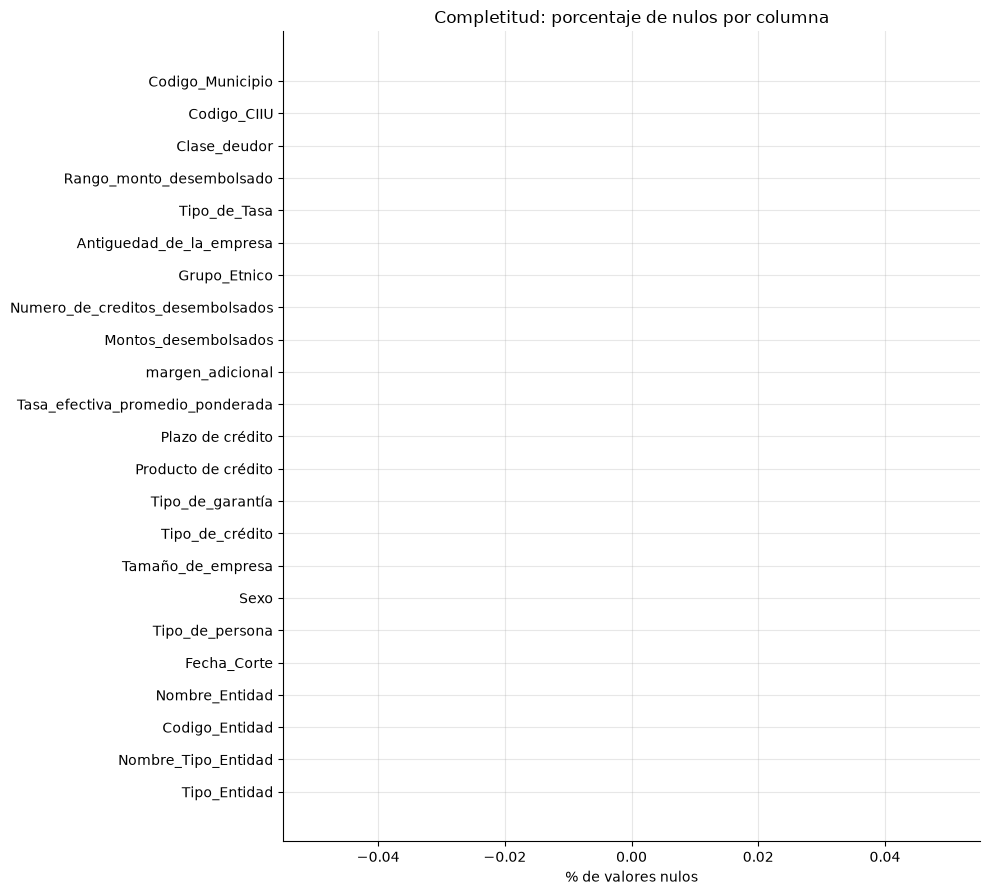

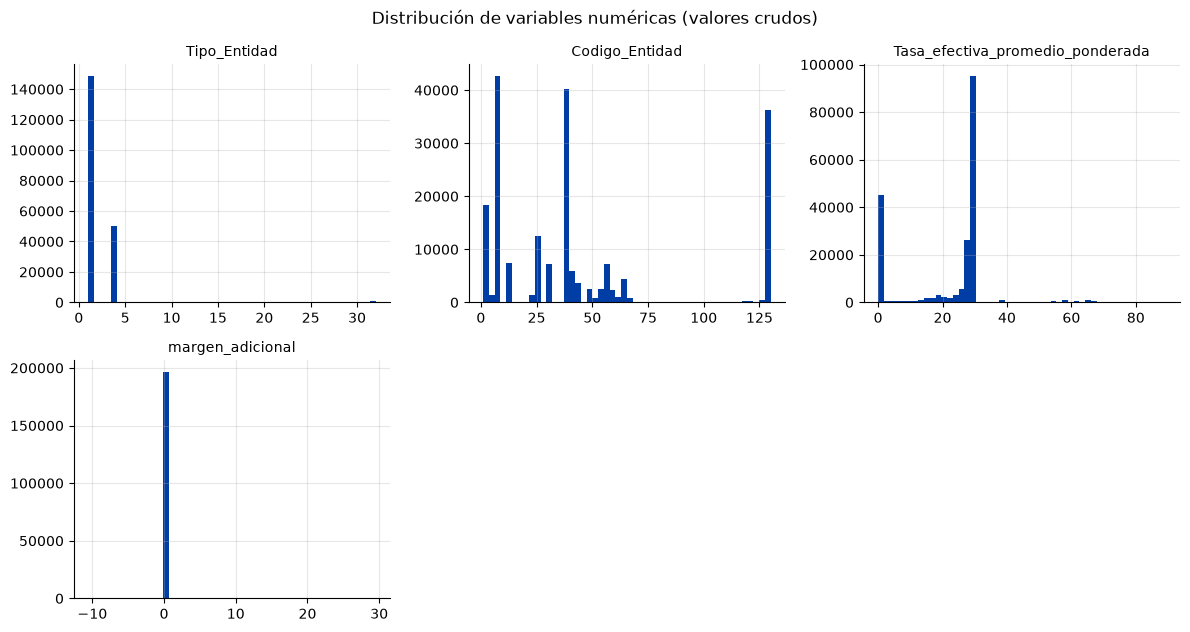

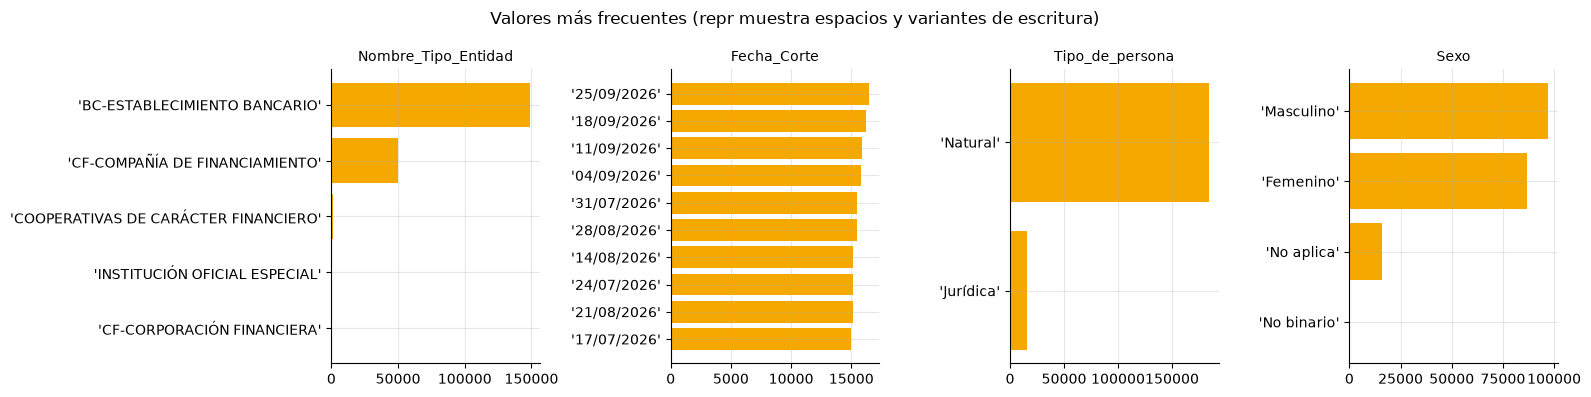

In [31]:
# ============================================================
# BLOQUE 7 · EJECUCIÓN DEL PERFIL
# ============================================================
resumen_perfil, perfil_crudo = perfilar_datos(df_crudo, columna_id=COLUMNA_ID)

display(Markdown("**Resumen general**"))
display(pd.Series(resumen_perfil, name="valor").to_frame())
display(Markdown("**Perfil por columna**"))
display(perfil_crudo)
graficar_perfil(df_crudo, perfil_crudo)

**✅ Evidencia (E2).** Tabla de perfil, resumen general, gráficos y tres hallazgos redactados con su cifra (por ejemplo: *"El 3,9 % de `Fecha Apertura` no se puede convertir a fecha, lo que excluiría esas solicitudes de cualquier serie temporal"*).

**💭 Pregunta de reflexión.** ¿Por qué no debemos limpiar los datos antes de conocerlos? Dé un ejemplo de su propio perfil en el que una limpieza "intuitiva" habría ocultado un problema.

✍️ *Hallazgos:*

1. **Completitud aparente.** El resumen indica 0,0 % de celdas nulas, pero hay ausencias escritas como texto. `Grupo_Etnico` tiene 1.784.490 filas con `"Sin información (1)"`: es el dato que de verdad falta. Además, `Tamaño_de_empresa` y `Antiguedad_de_la_empresa` dicen "No aplica" en 2.207.486 filas (86,9 %). El perfil las cuenta como posibles nulos, pero hay que verificar si "No aplica" es una ausencia o describe a quien no tiene empresa.

2. **Valores extremos que no necesariamente son errores.**
   - `Tasa_efectiva_promedio_ponderada` tiene 563.104 filas en 0,0 % (22 %) y un máximo de 89,25 %, con una desviación estándar de 14,35 que distorsionará cualquier promedio simple.
   - `margen_adicional` tiene 2.825 negativos (mínimo −10,59) y 2.498.583 ceros.

   Son tres hipótesis para el bloque 8: compras a una cuota sin interés, márgenes bajo un índice e intereses de microcrédito con su propia usura.

3. **Tipos incorrectos.** `Montos_desembolsados` tiene 1.191.005 valores distintos (46,89 % de cardinalidad) porque es texto con coma de miles (el valor más frecuente es `"1,000,000"`). `Numero_de_creditos_desembolsados` también es número guardado como texto. Ninguna de las dos se puede sumar hasta convertirla.

✍️ *Respuesta:* no se debe limpiar sin conocer los datos porque una corrección "intuitiva" puede destruir información real. Toda corrección necesita un diagnóstico y una evidencia que la justifique.

**Ejemplo de nuestro perfil:** la intuición habría sido convertir todos los "No aplica" en nulos, porque el perfil los marca como nulos disfrazados. Eso habría dejado sin dato al 86,9 % de las filas en tamaño y antigüedad de la empresa. El diagnóstico muestra otra cosa: "No aplica" coincide exactamente con las personas naturales sin empresa y, en sexo y grupo étnico, con las personas jurídicas. Es una **categoría estructural**, no un faltante.

**Otro ejemplo:** "eliminar las tasas en 0 % porque nadie presta gratis" habría borrado el 22 % de los datos, que son compras con tarjeta a una cuota: un comportamiento real del mercado.

## Bloque 8 · Diagnóstico de calidad (Fase 4 — Evidencia E4)

**🧭 Contexto.** La calidad del dato no es una opinión: se mide con **reglas verificables** agrupadas en dimensiones. Este bloque usa seis dimensiones alineadas con DAMA-DMBOK e ISO/IEC 25012.

| Dimensión | Pregunta que responde | Ejemplo de regla |
|---|---|---|
| Completitud | ¿Está el dato cuando se necesita? | `fecha_apertura` no nula |
| Unicidad | ¿Cada entidad aparece una sola vez? | `id_solicitud` sin repetidos |
| Validez | ¿El valor respeta su dominio, tipo y formato? | `edad` entre 14 y 100 |
| Consistencia | ¿Los datos se contradicen entre sí? | `fecha_cierre >= fecha_apertura` |
| Exactitud | ¿Corresponde a la realidad? (requiere referencia externa) | coordenadas dentro del área de cobertura |
| Integridad | ¿Se cumplen las relaciones entre campos o tablas? | estado "Cerrada" ⇒ tiene fecha de cierre |

**🎯 Reto.**
1. Ejecute `detectar_calidad()` y lea cada tabla.
2. Escriba **al menos cinco reglas** en `REGLAS_CALIDAD` que cubran al menos cuatro dimensiones. Cada regla es una función que recibe el DataFrame (con nombres estandarizados) y devuelve `True` en las filas que **cumplen**.
3. Documente cada problema en `PROBLEMAS_CALIDAD`: problema, impacto y estrategia de tratamiento. La evidencia y el resultado después de la corrección se calculan solos.

**📘 Explicación.** Las reglas se escriben con nombres estandarizados para poder evaluarlas **antes** (sobre `df_crudo`, renombrado al vuelo) y **después** (sobre el dataset curado) con el mismo código. Así la mejora se demuestra, no se afirma. La `tolerancia_pct` permite aceptar un incumplimiento residual **solo** si se justifica.

In [32]:
# ============================================================
# BLOQUE 8 · FUNCIONES DE DETECCIÓN
# ============================================================
def detectar_nulos(df):
    filas = []
    for c in df.columns:
        nulos = int(df[c].isna().sum())
        disfrazados = contar_nulos_disfrazados(df[c])
        filas.append({"columna": c, "nulos": nulos, "nulos_disfrazados": disfrazados,
                      "faltante_real": nulos + disfrazados,
                      "pct_faltante_real": round(100 * (nulos + disfrazados) / max(len(df), 1), 2)})
    return pd.DataFrame(filas).sort_values("pct_faltante_real", ascending=False)


def detectar_duplicados(df, columna_id=None):
    col_id = next((c for c in df.columns if estandarizar_nombre(c) == columna_id), None) if columna_id else None
    resultado = {"filas_duplicadas_exactas": int(df.duplicated().sum())}
    if col_id:
        rep = df[col_id].duplicated(keep=False)
        resultado.update({"filas_con_id_repetido": int(rep.sum()),
                          "ids_distintos_repetidos": int(df.loc[rep, col_id].nunique()),
                          "ids_repetidos_con_contenido_distinto":
                              int(df.drop_duplicates().loc[lambda x: x[col_id].duplicated(keep=False), col_id].nunique())})
    return pd.Series(resultado, name="valor").to_frame()


def detectar_cardinalidad(df):
    filas = []
    for c in df.columns:
        u, validos = df[c].nunique(dropna=True), df[c].notna().sum()
        ratio = u / max(validos, 1)
        clase = ("constante" if u <= 1 else "baja → candidata a dimensión/categoría" if u <= 50
                 else "alta → posible identificador" if ratio > 0.9 else "media")
        filas.append({"columna": c, "unicos": u, "ratio_unicos": round(ratio, 4), "clasificacion": clase})
    return pd.DataFrame(filas)


def detectar_tipos(df, muestra=2_000, semilla=0):
    filas = []
    for c in df.columns:
        s = df[c]
        sugerido, evidencia = str(s.dtype), ""
        if es_texto(s) and s.notna().any():
            m = s.dropna().sample(min(s.notna().sum(), muestra), random_state=semilla)
            p_num = a_numero(m).notna().mean()
            p_fecha = a_fecha(m).notna().mean() if p_num < 0.8 else 0
            p_unid = m.astype(str).str.match(r"^\s*-?\d+([.,]\d+)?\s*[A-Za-záéíóúÁÉÍÓÚ]+\.?\s*$").mean()
            p_moneda = m.astype(str).str.contains(r"[$€]").mean()
            if p_moneda >= 0.02 and p_num + p_moneda >= 0.8:
                sugerido, evidencia = "moneda como texto", f"{p_num:.0%} numérico + {p_moneda:.0%} con símbolo"
            elif p_num >= 0.8:
                sugerido, evidencia = "numérico", f"{p_num:.0%} convertible"
            elif p_fecha >= 0.6:
                sugerido, evidencia = "fecha", f"{p_fecha:.0%} convertible"
            elif p_unid >= 0.5:
                sugerido, evidencia = "numérico con unidades", f"{p_unid:.0%} con patrón número + unidad"
            else:
                sugerido = "categoría" if s.nunique() <= 50 else "texto"
        filas.append({"columna": c, "tipo_actual": str(s.dtype), "tipo_sugerido": sugerido, "evidencia": evidencia})
    return pd.DataFrame(filas)


def detectar_sospechosos(df, k_iqr=3.0, max_unicos_texto=5_000):
    numericos, textos = [], []
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
            x = s.dropna().astype(float)
            if x.empty:
                continue
            q1, q3 = x.quantile([0.25, 0.75])
            iqr = q3 - q1
            atipicos = int(((x < q1 - k_iqr * iqr) | (x > q3 + k_iqr * iqr)).sum()) if iqr > 0 else 0
            numericos.append({"columna": c, "negativos": int((x < 0).sum()), "ceros": int((x == 0).sum()),
                              f"atipicos_extremos_iqr{k_iqr:g}": atipicos, "p01": x.quantile(0.01),
                              "p99": x.quantile(0.99), "max": x.max()})
        elif es_texto(s) and 0 < s.nunique() <= max_unicos_texto:
            conteo = s.value_counts(dropna=True)
            valores = pd.Series(conteo.index.astype(str), index=conteo.index)
            espacios = int(conteo[(valores != valores.str.strip()).to_numpy()].sum())
            claves = valores.map(normalizar_texto)
            grupos = valores.groupby(claves.to_numpy()).agg(list)
            con_variantes = grupos[grupos.map(len) > 1]
            textos.append({"columna": c, "valores_con_espacios_extremos": espacios,
                           "grupos_con_variantes": len(con_variantes),
                           "ejemplo_variantes": " | ".join(map(repr, con_variantes.iloc[0][:4])) if len(con_variantes) else ""})
    return pd.DataFrame(numericos), pd.DataFrame(textos)


def detectar_calidad(df, columna_id=None, mostrar=True):
    """Diagnóstico automático. Devuelve un diccionario de tablas (y las muestra si mostrar=True)."""
    num, txt = detectar_sospechosos(df)
    diagnostico = {
        "nulos": detectar_nulos(df),
        "duplicados": detectar_duplicados(df, columna_id),
        "cardinalidad": detectar_cardinalidad(df),
        "tipos": detectar_tipos(df),
        "sospechosos_numericos": num,
        "sospechosos_texto": txt,
    }
    if mostrar:
        for nombre, tabla in diagnostico.items():
            display(Markdown(f"**{nombre.replace('_', ' ').capitalize()}**"))
            display(tabla)
    return diagnostico



diagnostico_crudo = detectar_calidad(df_crudo, COLUMNA_ID)

**Nulos**

,columna,nulos,nulos_disfrazados,faltante_real,pct_faltante_real
7,Tamaño_de_empresa,0,2207486,2207486,86.91
17,Antiguedad_de_la_empresa,0,2207486,2207486,86.91
16,Grupo_Etnico,0,1784490,1784490,70.26
6,Sexo,0,203845,203845,8.03
2,Codigo_Entidad,0,0,0,0.00
1,Nombre_Tipo_Entidad,0,0,0,0.00
0,Tipo_Entidad,0,0,0,0.00
5,Tipo_de_persona,0,0,0,0.00
4,Fecha_Corte,0,0,0,0.00
3,Nombre_Entidad,0,0,0,0.00


**Duplicados**

,valor
filas_duplicadas_exactas,0


**Cardinalidad**

...

,columna,tipo_actual,tipo_sugerido,evidencia
0,Tipo_Entidad,int8,int8,
1,Nombre_Tipo_Entidad,category,categoría,
2,Codigo_Entidad,int16,int16,
3,Nombre_Entidad,category,texto,
4,Fecha_Corte,category,fecha,100% convertible
5,Tipo_de_persona,category,categoría,
6,Sexo,category,categoría,
7,Tamaño_de_empresa,category,categoría,
8,Tipo_de_crédito,category,categoría,
9,Tipo_de_garantía,category,categoría,


**Sospechosos numericos**

,columna,negativos,ceros,atipicos_extremos_iqr3,p01,p99,max
0,Tipo_Entidad,0,0,14789,1.0,4.00,32.00
1,Codigo_Entidad,0,0,0,1.0,128.00,130.00
2,Tasa_efectiva_promedio_ponderada,0,563104,10746,0.0,66.00,89.25
3,margen_adicional,2825,2498583,0,0.0,4.61,36.59


**Sospechosos texto**

,columna,valores_con_espacios_extremos,grupos_con_variantes,ejemplo_variantes
0,Nombre_Tipo_Entidad,0,0,
1,Nombre_Entidad,0,0,
2,Fecha_Corte,0,0,
3,Tipo_de_persona,0,0,
4,Sexo,0,0,
5,Tamaño_de_empresa,0,0,
6,Tipo_de_crédito,0,0,
7,Tipo_de_garantía,0,0,
8,Producto de crédito,0,1,'Construcción de proyectos de vivienda vis (colocación ...
9,Plazo de crédito,0,0,


In [33]:
# ============================================================
# BLOQUE 8 · UTILIDADES DE LAS REGLAS Y REFERENCIA EXTERNA   (PC2)
# Con 2,5 M de filas las conversiones se hacen una vez por VALOR
# DISTINTO y no fila a fila: mismo resultado, mucho más rápido.
# ============================================================
def texto(serie):
    """Vista de texto de una columna (category, str u object) para comparar valores."""
    return serie.astype("object")


def valores_por_unicos(serie, mapa):
    """Reemplaza cada valor por mapa[valor]. En columnas 'category' trabaja sobre los códigos:
    no crea un objeto nuevo por fila (clave para no agotar la RAM)."""
    if isinstance(serie.dtype, pd.CategoricalDtype):
        categorias = serie.cat.categories
        valores = np.empty(len(categorias) + 1, dtype=object)
        valores[:-1] = [mapa.get(c, c) for c in categorias]
        valores[-1] = np.nan                                   # código -1 = nulo
        return pd.Series(valores[serie.cat.codes.to_numpy()], index=serie.index, dtype=object)
    t = texto(serie)
    resultado = t.map(mapa)                                    # dict.map: rápido (sin lambda fila a fila)
    sin_clave = resultado.isna() & t.notna() & ~t.isin(list(mapa))
    if sin_clave.any():                                        # valores que no están en el mapa: se conservan
        resultado[sin_clave] = t[sin_clave]
    return resultado


def unicos(serie):
    return pd.Series(serie.dropna().unique()).astype("object")


def bool_por_unicos(serie, funcion, nulo=False):
    """Evalúa una condición una vez por valor distinto; los nulos reciben `nulo`."""
    mapa = {u: bool(funcion(u)) for u in unicos(serie)}
    return valores_por_unicos(serie, mapa).fillna(nulo).astype(bool)


def num_por_unicos(serie):
    """Texto → número SIN quitar separadores: '1,000,000' queda NaN (sirve para medir el problema)."""
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    u = unicos(serie)
    return valores_por_unicos(serie, dict(zip(u, pd.to_numeric(u, errors="coerce")))).astype(float)


def num_miles_por_unicos(serie):
    """Texto → número QUITANDO la coma de miles ('1,000,000' → 1000000). Para reglas de plausibilidad
    que deben medirse igual antes y después de la limpieza."""
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    u = unicos(serie)
    numeros = pd.to_numeric(u.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
    return valores_por_unicos(serie, dict(zip(u, numeros))).astype(float)


def fecha_por_unicos(serie):
    """a_fecha() aplicada a los valores distintos (Fecha_Corte solo tiene ~14 valores)."""
    if pd.api.types.is_datetime64_any_dtype(serie):
        return serie
    u = unicos(serie)
    convertidas = a_fecha(u)
    return pd.to_datetime(valores_por_unicos(serie, dict(zip(u, convertidas))), errors="coerce")


def rango_canonico(valor):
    """Una sola forma de escribir los rangos de monto:
    'Mayor a 1 SMLMV menor o igual a 3 SMLMV' → 'Mayor a 1 SMLMV y menor o igual a 3 SMLMV'
    'Mayor 300 SMLMV' → 'Mayor a 300 SMLMV'."""
    if not isinstance(valor, str):
        return valor
    t = re.sub(r"\s+", " ", valor.strip())
    t = re.sub(r"^Mayor (?!a )", "Mayor a ", t)
    t = re.sub(r"SMLMV menor o igual", "SMLMV y menor o igual", t)
    return t


def limite_inferior_smlmv(valor):
    """'Hasta 1 SMLMV' → 0 · 'Mayor a 6 SMLMV y menor…' → 6 (sirve para ordenar los rangos)."""
    if not isinstance(valor, str):
        return np.nan
    m = re.search(r"Mayor a (\d+(?:[.,]\d+)?)", valor)
    return float(m.group(1).replace(",", ".")) if m else (0.0 if valor.startswith("Hasta") else np.nan)


# ------------------------------------------------------------
# Referencia externa: tasas de usura certificadas por la SFC (% efectivo anual).
# Fuentes: Superfinanciera, Resolución 0965 de 2026 (julio) y Resolución 1260 de 2026
# (septiembre); comunicados de certificación de junio, agosto y octubre de 2026
# (superfinanciera.gov.co, actualicese.com, portafolio.co, noticiasrcn.com).
# ✏️ Cuando la fuente se actualice, agregue aquí el mes nuevo.
# ------------------------------------------------------------
MODALIDADES = ["Consumo y ordinario", "Consumo de bajo monto", "Productivo de mayor monto", "Productivo rural",
               "Productivo urbano", "Popular productivo rural", "Popular productivo urbano"]
USURA_SFC = {
    "2026-06": dict(zip(MODALIDADES, [28.79, 62.10, 41.06, 33.35, 59.93, 72.95, 89.73])),
    "2026-07": dict(zip(MODALIDADES, [28.79, 62.66, 41.27, 32.75, 58.16, 68.75, 87.72])),
    "2026-08": dict(zip(MODALIDADES, [29.66, 65.46, 42.00, 33.56, 59.67, 68.55, 88.97])),
    "2026-09": dict(zip(MODALIDADES, [29.24, 66.87, 41.88, 32.64, 57.92, 67.20, 88.13])),
    "2026-10": dict(zip(MODALIDADES, [28.59, 66.66, 41.25, 30.95, 57.39, 65.45, 87.62])),
}


def modalidad_credito(tipo, producto):
    """Modalidad de usura (SFC) a partir del tipo y el producto de crédito."""
    t, p = normalizar_texto(str(tipo)), normalizar_texto(str(producto))
    if "BAJO MONTO" in p:
        return "Consumo de bajo monto"
    if "PRODUCTIVO" in t:
        for clave, modalidad in [("POPULAR PRODUCTIVO URBANO", "Popular productivo urbano"),
                                 ("POPULAR PRODUCTIVO RURAL", "Popular productivo rural"),
                                 ("MAYOR MONTO", "Productivo de mayor monto"),
                                 ("PRODUCTIVO URBANO", "Productivo urbano"),
                                 ("PRODUCTIVO RURAL", "Productivo rural")]:
            if clave in p:
                return modalidad
        return "Productivo sin modalidad identificable"
    return "Consumo y ordinario"            # consumo, comercial (ordinario) y vivienda


def serie_modalidad(d):
    clave = texto(d["tipo_de_credito"]).fillna("").astype(str) + "||" + texto(d["producto_de_credito"]).fillna("").astype(str)
    mapa = {k: modalidad_credito(*k.split("||", 1)) for k in clave.unique()}
    return clave.map(mapa)


def tope_usura(d):
    """Usura aplicable a cada fila. La semana de corte (viernes) incluye los 6 días previos; si la
    semana cruza dos meses se usa el tope MAYOR de ambos (criterio conservador: no acusar sin certeza)."""
    f = fecha_por_unicos(d["fecha_corte"])
    fechas = pd.Series(f.dropna().unique())
    mes_fin = dict(zip(fechas, fechas.dt.strftime("%Y-%m")))
    mes_ini = dict(zip(fechas, (fechas - pd.Timedelta(days=6)).dt.strftime("%Y-%m")))
    tabla = {f"{mes}|{mod}": v for mes, topes in USURA_SFC.items() for mod, v in topes.items()}
    modalidad = serie_modalidad(d)
    t_fin = (f.map(mes_fin).astype(object) + "|" + modalidad).map(tabla).astype(float)
    t_ini = (f.map(mes_ini).astype(object) + "|" + modalidad).map(tabla).astype(float)
    return pd.Series(np.fmax(t_fin.to_numpy(), t_ini.to_numpy()), index=d.index)


display(Markdown("**Tasa de usura certificada por la SFC (% E.A.) — referencia externa de la regla R13**"))
display(pd.DataFrame(USURA_SFC).rename_axis("modalidad"))

**Tasa de usura certificada por la SFC (% E.A.) — referencia externa de la regla R13**

,2026-06,2026-07,2026-08,2026-09,2026-10
modalidad,,,,,
Consumo y ordinario,28.79,28.79,29.66,29.24,28.59
Consumo de bajo monto,62.10,62.66,65.46,66.87,66.66
Productivo de mayor monto,41.06,41.27,42.00,41.88,41.25
Productivo rural,33.35,32.75,33.56,32.64,30.95
Productivo urbano,59.93,58.16,59.67,57.92,57.39
Popular productivo rural,72.95,68.75,68.55,67.20,65.45
Popular productivo urbano,89.73,87.72,88.97,88.13,87.62


In [34]:
# ============================================================
# BLOQUE 8 · REGLAS DE CALIDAD                    ✏️ EDITAR
# ============================================================
def regla(id, dimension, campo, descripcion, funcion, tolerancia_pct=0.0, justificacion_tolerancia=""):
    return {"id": id, "dimension": dimension, "campo": campo, "descripcion": descripcion,
            "funcion": funcion, "tolerancia_pct": tolerancia_pct,
            "justificacion_tolerancia": justificacion_tolerancia}

def col(d, *nombres):
    """Devuelve la primera columna que exista (útil si una columna cambia de nombre al limpiar)."""
    for n in nombres:
        if n in d.columns:
            return d[n]
    raise KeyError(f"Ninguna de las columnas {nombres} existe")

def entre(serie, minimo=None, maximo=None, permitir_nulos=True):
    x = a_numero(serie)
    ok = pd.Series(True, index=serie.index)
    if minimo is not None:
        ok &= x >= minimo
    if maximo is not None:
        ok &= x <= maximo
    return (ok | x.isna()) if permitir_nulos else (ok & x.notna())


def evaluar_reglas(df, reglas, mapa_nombres=None):
    """Evalúa cada regla. Con `mapa_nombres` renombra al vuelo (para evaluar los datos crudos)."""
    d = df.rename(columns=mapa_nombres) if mapa_nombres else df
    filas = []
    for r in reglas:
        base = {k: r[k] for k in ("id", "dimension", "campo", "descripcion", "tolerancia_pct")}
        try:
            cumple = pd.Series(r["funcion"](d), index=d.index).fillna(False).astype(bool)
            incumplen = int((~cumple).sum())
            pct = 100 * incumplen / max(len(d), 1)
            estado = ("Cumple" if incumplen == 0 else
                      "Dentro de tolerancia" if pct <= r["tolerancia_pct"] else "No cumple")
            filas.append({**base, "evaluados": len(d), "incumplen": incumplen, "pct_incumple": round(pct, 3),
                          "estado": estado, "error": ""})
        except Exception as e:
            filas.append({**base, "evaluados": len(d), "incumplen": None, "pct_incumple": None,
                          "estado": "Error", "error": f"{type(e).__name__}: {e}"})
    columnas = ["id", "dimension", "campo", "descripcion", "evaluados", "incumplen",
                "pct_incumple", "tolerancia_pct", "estado", "error"]
    return pd.DataFrame(filas, columns=columnas)


# ------------------------------------------------------------
# ✏️ Escriba aquí SUS reglas (mínimo 5, en al menos 4 dimensiones)
# ------------------------------------------------------------
REGLAS_CALIDAD = [
    regla("R01", "Completitud", "fecha_corte",
          "La fecha de corte existe, es una fecha válida y no es posterior a la descarga",
          lambda d: fecha_por_unicos(d["fecha_corte"]).between(pd.Timestamp("2026-01-01"), pd.Timestamp(FECHA_CORTE))),
    regla("R02", "Unicidad", "(fila completa)",
          "Cada combinación de atributos, tasa y monto aparece una sola vez (sin doble reporte)",
          lambda d: ~d.duplicated(keep=False)),
    regla("R03", "Validez", "montos_desembolsados",
          "El monto desembolsado es un número (sin separador de miles en texto) y vale al menos $1",
          lambda d: num_por_unicos(d["montos_desembolsados"]) >= 1),
    regla("R04", "Validez", "numero_de_creditos_desembolsados",
          "El número de créditos desembolsados es un entero mayor o igual a 1",
          lambda d: (lambda x: (x >= 1) & (x % 1 == 0))(num_por_unicos(d["numero_de_creditos_desembolsados"]))),
    regla("R05", "Validez", "tasa_efectiva_promedio_ponderada",
          "La tasa efectiva anual existe y está entre 0 % y 100 %",
          lambda d: entre(d["tasa_efectiva_promedio_ponderada"], 0, 100, permitir_nulos=False)),
    regla("R06", "Validez", "grupo_etnico, antiguedad_de_la_empresa",
          "Las categorías no contienen marcadores técnicos del formulario como '(1)'",
          lambda d: ~(bool_por_unicos(d["grupo_etnico"], lambda v: re.search(r"\(\d\)", str(v))) |
                      bool_por_unicos(d["antiguedad_de_la_empresa"], lambda v: re.search(r"\(\d\)", str(v))))),
    regla("R07", "Validez", "codigo_municipio, codigo_ciiu",
          "Código DIVIPOLA de 5 dígitos y código CIIU de 4 dígitos (con ceros a la izquierda)",
          lambda d: bool_por_unicos(d["codigo_municipio"], lambda v: re.fullmatch(r"\d{5}", str(v))) &
                    bool_por_unicos(d["codigo_ciiu"], lambda v: re.fullmatch(r"\d{4}", str(v)))),
    regla("R08", "Consistencia", "rango_monto_desembolsado",
          "Cada rango de monto se escribe de una sola forma ('Mayor a X SMLMV y menor o igual a Y SMLMV')",
          lambda d: bool_por_unicos(d["rango_monto_desembolsado"], lambda v: v == rango_canonico(v), nulo=True)),
    regla("R09", "Consistencia", "tamano_de_empresa, antiguedad_de_la_empresa",
          "'No aplica' (persona sin empresa) se escribe igual en tamaño y en antigüedad de la empresa",
          lambda d: (texto(d["tamano_de_empresa"]) == "No aplica") == (texto(d["antiguedad_de_la_empresa"]) == "No aplica")),
    regla("R10", "Consistencia", "tipo_de_tasa, margen_adicional",
          "Una tasa fija (FS) no tiene margen adicional sobre un índice (margen = 0)",
          lambda d: (texto(d["tipo_de_tasa"]) != "FS") | (a_numero(d["margen_adicional"]) == 0)),
    regla("R11", "Integridad", "tipo_de_persona, sexo, grupo_etnico",
          "Persona jurídica ⇔ sexo 'No aplica', y toda persona jurídica tiene grupo étnico 'No aplica'",
          lambda d: (lambda jur: (jur == (texto(d["sexo"]) == "No aplica")) & (~jur | (texto(d["grupo_etnico"]) == "No aplica")))(
              texto(d["tipo_de_persona"]) == "Jurídica")),
    regla("R12", "Integridad", "tipo_entidad, codigo_entidad, nombre_entidad",
          "La clave (tipo_entidad, codigo_entidad) identifica a una sola entidad",
          lambda d: d.groupby([texto(d["tipo_entidad"]), texto(d["codigo_entidad"])], dropna=False, observed=True)["nombre_entidad"]
                     .transform("nunique") <= 1),
    regla("R13", "Exactitud", "tasa_efectiva_promedio_ponderada",
          "La tasa no supera la usura certificada por la SFC para su modalidad y semana (referencia externa)",
          lambda d: (lambda t, tope: tope.isna() | t.isna() | (t <= tope + 1e-9))(
              a_numero(d["tasa_efectiva_promedio_ponderada"]), tope_usura(d)),
          tolerancia_pct=0.1,
          justificacion_tolerancia="Una tasa por encima de la usura es un hallazgo (pregunta 5), no un error de digitación: "
                                   "no se corrige, se marca en supera_usura y se reporta."),
    regla("R14", "Exactitud", "montos_desembolsados, numero_de_creditos_desembolsados",
          "El monto promedio por crédito es de al menos $1.000 (montos menores no corresponden a un desembolso real)",
          lambda d: (lambda m: m.isna() | (m >= 1_000))(
              num_miles_por_unicos(d["montos_desembolsados"]) / num_miles_por_unicos(d["numero_de_creditos_desembolsados"])),
          tolerancia_pct=0.5,
          justificacion_tolerancia="En el portal completo son 11.632 filas (0,09 %); no se puede saber el valor real, "
                                   "así que se conservan, se marcan en es_monto_irrisorio y se excluyen en Power BI."),
]

if MODO_DEMO:
    DOMINIO_MUNICIPIO = {"Medellín", "Bello", "Itagüí", "Envigado", "Sabaneta", "Sin información"}
    AREA_COBERTURA = {"lat": (6.0, 6.5), "lon": (-75.8, -75.3)}   # rectángulo aproximado del Valle de Aburrá
    REGLAS_CALIDAD = [
        regla("R01", "Completitud", "fecha_apertura", "La fecha de apertura existe y es una fecha válida no posterior al corte",
              lambda d: a_fecha(d["fecha_apertura"]).between(pd.Timestamp("2000-01-01"), pd.Timestamp(FECHA_CORTE) + pd.Timedelta(days=1))),
        regla("R02", "Unicidad", "id_solicitud", "Cada solicitud aparece una sola vez",
              lambda d: ~d["id_solicitud"].duplicated(keep=False)),
        regla("R03", "Validez", "edad_solicitante", "Edad entre 14 y 100 años (o sin dato)",
              lambda d: entre(d["edad_solicitante"], 14, 100)),
        regla("R04", "Validez", "costo_atencion_cop", "El costo está en formato numérico",
              lambda d: d["costo_atencion_cop"].isna() | a_numero(d["costo_atencion_cop"]).notna()),
        regla("R05", "Validez", "costo_atencion_cop", "El costo no es negativo",
              lambda d: entre(d["costo_atencion_cop"], minimo=0)),
        regla("R06", "Consistencia", "municipio", "El municipio pertenece al dominio oficial (escritura única)",
              lambda d: d["municipio"].isin(DOMINIO_MUNICIPIO)),
        regla("R07", "Consistencia", "fecha_cierre", "La fecha de cierre no es anterior a la de apertura",
              lambda d: (lambda ini, fin: ini.isna() | fin.isna() | (fin >= ini))(a_fecha(d["fecha_apertura"]), a_fecha(d["fecha_cierre"]))),
        regla("R08", "Integridad", "estado", "Toda solicitud cerrada tiene fecha de cierre",
              lambda d: ~d["estado"].astype("object").map(normalizar_texto).isin(["CERRADA", "CERRADO"]) | a_fecha(d["fecha_cierre"]).notna(),
              tolerancia_pct=5.0,
              justificacion_tolerancia="La fecha de cierre faltante no puede reconstruirse; se conserva el registro y se reporta como riesgo."),
        regla("R09", "Exactitud", "latitud, longitud", "Las coordenadas caen dentro del área de cobertura (o no se reportan)",
              lambda d: (d["latitud"].isna() & d["longitud"].isna()) |
                        (entre(d["latitud"], *AREA_COBERTURA["lat"], permitir_nulos=False) &
                         entre(d["longitud"], *AREA_COBERTURA["lon"], permitir_nulos=False))),
        regla("R10", "Validez", "calificacion", "La calificación está entre 1 y 5 (o sin dato)",
              lambda d: entre(d["calificacion"], 1, 5)),
        regla("R11", "Validez", "tiempo_respuesta", "El tiempo de respuesta es numérico y está en una sola unidad (horas)",
              lambda d: col(d, "tiempo_respuesta_horas", "tiempo_respuesta").isna() |
                        a_numero(col(d, "tiempo_respuesta_horas", "tiempo_respuesta")).notna()),
    ]

calidad_antes = evaluar_reglas(df_crudo, REGLAS_CALIDAD, mapa_nombres=MAPA_NOMBRES)
print(f"Reglas definidas: {len(REGLAS_CALIDAD)} · dimensiones cubiertas: {calidad_antes['dimension'].nunique()}")
display(calidad_antes)

Reglas definidas: 14 · dimensiones cubiertas: 6


,id,dimension,campo,descripcion,evaluados,incumplen,pct_incumple,tolerancia_pct,estado,error
0,R01,Completitud,fecha_corte,"La fecha de corte existe, es una fecha válida y no es po...",2539891,0,0.000,0.0,Cumple,
1,R02,Unicidad,(fila completa),"Cada combinación de atributos, tasa y monto aparece una ...",2539891,0,0.000,0.0,Cumple,
2,R03,Validez,montos_desembolsados,El monto desembolsado es un número (sin separador de mil...,2539891,2537867,99.920,0.0,No cumple,
3,R04,Validez,numero_de_creditos_desembolsados,El número de créditos desembolsados es un entero mayor o...,2539891,4436,0.175,0.0,No cumple,
4,R05,Validez,tasa_efectiva_promedio_ponderada,La tasa efectiva anual existe y está entre 0 % y 100 %,2539891,0,0.000,0.0,Cumple,
5,R06,Validez,"grupo_etnico, antiguedad_de_la_empresa",Las categorías no contienen marcadores técnicos del form...,2539891,2288589,90.106,0.0,No cumple,
6,R07,Validez,"codigo_municipio, codigo_ciiu",Código DIVIPOLA de 5 dígitos y código CIIU de 4 dígitos ...,2539891,0,0.000,0.0,Cumple,
7,R08,Consistencia,rango_monto_desembolsado,Cada rango de monto se escribe de una sola forma ('Mayor...,2539891,471916,18.580,0.0,No cumple,
8,R09,Consistencia,"tamano_de_empresa, antiguedad_de_la_empresa",'No aplica' (persona sin empresa) se escribe igual en ta...,2539891,2207486,86.913,0.0,No cumple,
9,R10,Consistencia,"tipo_de_tasa, margen_adicional",Una tasa fija (FS) no tiene margen adicional sobre un ín...,2539891,0,0.000,0.0,Cumple,


In [35]:
# ============================================================
# BLOQUE 8 · DOCUMENTACIÓN DE PROBLEMAS           ✏️ EDITAR
# Un problema por regla: problema, impacto y estrategia. La evidencia
# (antes) y el resultado (después) se calculan automáticamente.
# ============================================================
PROBLEMAS_CALIDAD = {
    "R01": {"problema": "Fecha_Corte llega como texto dd/mm/aaaa; cualquier fecha vacía o posterior a la descarga (2026-10-07) sería inválida",
            "impacto": "Sin tipo fecha no hay tabla Calendario ni serie semanal en Power BI (pregunta 3)",
            "estrategia": "Convertir con formato explícito dd/mm/aaaa sobre los valores distintos; posteriores al corte → nulo; eliminar la fila si queda sin fecha"},
    "R02": {"problema": "Filas idénticas en sus 23 columnas: la misma combinación entidad-semana-segmento-tasa-monto reportada dos veces",
            "impacto": "Doble conteo de montos y número de créditos (preguntas 2 y 4)",
            "estrategia": "Eliminar duplicados exactos y conservar una copia; no hay identificador, así que solo se borran copias idénticas"},
    "R03": {"problema": "Montos_desembolsados como texto con separador de miles ('1,000,000') y montos imposibles (0,01 pesos)",
            "impacto": "Power BI lo trataría como texto: no se puede sumar el monto ni calcular la participación por tipo de entidad",
            "estrategia": "Quitar la coma de miles y convertir a número; montos < $1 → nulo y fila eliminada (el monto es esencial)"},
    "R04": {"problema": "Numero_de_creditos_desembolsados como texto ('1,234' cuando supera 999)",
            "impacto": "No se puede calcular el monto promedio por crédito (pregunta 4)",
            "estrategia": "Quitar separador de miles, convertir a entero (Int64) y exigir ≥ 1"},
    "R05": {"problema": "Tasa fuera del rango 0–100 % o vacía (control de dominio)",
            "impacto": "Un valor así distorsionaría cualquier promedio ponderado de tasa",
            "estrategia": "Fuera de [0, 100] → nulo y fila eliminada. Las tasas en 0 % NO son inválidas: son compras a una cuota con tarjeta y se marcan en es_tasa_cero"},
    "R06": {"problema": "Marcadores técnicos del formulario dentro de la categoría: 'Sin información (1)' en Grupo_Etnico y 'No aplica(1)' en Antiguedad_de_la_empresa",
            "impacto": "Las etiquetas no coinciden con las de otras columnas ('No aplica') y el faltante real queda oculto",
            "estrategia": "'Sin información (1)' → nulo explícito → categoría 'Sin información'; 'No aplica(1)' → 'No aplica' (categoría estructural, no faltante)"},
    "R07": {"problema": "Códigos DIVIPOLA y CIIU pueden perder los ceros a la izquierda si se leen como número (05001 → 5001; 0010 → 10)",
            "impacto": "Los municipios de Antioquia (05xxx) y los CIIU de personas naturales (0010, 0020, 0090) no cruzarían con tablas oficiales",
            "estrategia": "Leer como texto (DTYPE_LECTURA) y rellenar con ceros a 5 y 4 dígitos"},
    "R08": {"problema": "Un mismo rango de monto escrito de varias formas ('Mayor a 6 SMLMV menor o igual a 12 SMLMV' vs '… y menor o igual …'; 'Mayor 300 SMLMV')",
            "impacto": "El mismo rango aparece partido en dos barras y los totales por rango quedan subestimados",
            "estrategia": "Forma canónica con expresiones regulares ('Mayor a X SMLMV y menor o igual a Y SMLMV') y variable de orden rango_monto_min_smlmv"},
    "R09": {"problema": "Tamaño de empresa usa 'No aplica' y Antigüedad usa 'No aplica(1)' para el mismo caso (persona natural sin empresa)",
            "impacto": "Un filtro 'No aplica' en Power BI deja por fuera la mitad de los registros equivalentes",
            "estrategia": "Unificar la etiqueta en 'No aplica' en ambas columnas (mapa de categorías)"},
    "R10": {"problema": "Control: en tasa fija (FS) el margen adicional debe ser 0. Los márgenes negativos solo aparecen en tasas indexadas (IBR, DTF)",
            "impacto": "Si se tomara el margen negativo como error se borrarían créditos reales indexados por debajo del índice",
            "estrategia": "No se corrige: el margen negativo es válido en tasas variables (tasa = índice + margen). Se verifica la regla FS ⇒ margen = 0"},
    "R11": {"problema": "Control de integridad entre tipo de persona, sexo y grupo étnico ('No aplica' es estructural en personas jurídicas)",
            "impacto": "Si 'No aplica' se tratara como nulo, las personas jurídicas parecerían datos faltantes de sexo y etnia",
            "estrategia": "Conservar 'No aplica' como categoría (no se convierte en nulo) y verificar la equivalencia jurídica ⇔ 'No aplica'"},
    "R12": {"problema": "Codigo_Entidad se repite entre tipos de entidad (código 1 = Banco de Bogotá, Bancoldex y Cooperativa Financiera de Antioquia)",
            "impacto": "Una dimensión Entidad con clave Codigo_Entidad mezclaría entidades distintas en Power BI (pregunta 1)",
            "estrategia": "Usar la clave compuesta tipo_entidad-codigo_entidad (variable id_entidad) y verificar que identifique un solo nombre"},
    "R13": {"problema": "Posibles tasas por encima de la usura certificada (exactitud frente a una referencia externa: resoluciones SFC)",
            "impacto": "Una tasa sobre la usura es una alerta regulatoria para la gerencia (pregunta 5)",
            "estrategia": "No se modifica el dato: se calcula tasa_usura_vigente por modalidad y semana, y se marca supera_usura"},
    "R14": {"problema": "Montos promedio por crédito menores a $1.000 (p. ej. 0,01 o 500 pesos)",
            "impacto": "Bajan artificialmente el monto promedio por crédito (pregunta 4)",
            "estrategia": "Los < $1 se eliminan (R03); el resto se marca en es_monto_irrisorio, se excluye de las medidas de monto promedio y se acepta con tolerancia documentada"},
}

if MODO_DEMO:
    PROBLEMAS_CALIDAD = {
        "R01": {"problema": "Fechas de apertura vacías, con nulos disfrazados ('N/A', 'SIN DATO'), imposibles (31/02) o futuras (2031)",
                "impacto": "Esas solicitudes no pueden ubicarse en el tiempo: distorsionan series mensuales y estacionalidad",
                "estrategia": "Convertir con formatos explícitos; lo no convertible o posterior al corte pasa a nulo; eliminar la fila (la fecha es esencial para el análisis)"},
        "R02": {"problema": "Filas copiadas y versiones posteriores de una misma solicitud; las copias quedan ocultas por la columna de índice 'Unnamed: 0' y solo aparecen como duplicadas exactas al eliminarla",
                "impacto": "Inflan conteos, costos y KPI de volumen",
                "estrategia": "Eliminar duplicados exactos; entre versiones del mismo ID conservar la última (actualización)"},
        "R03": {"problema": "Edades imposibles (-1, 0, 7, 150, 999)",
                "impacto": "Sesgan promedios y rangos etarios",
                "estrategia": "Fuera de [14, 100] → nulo; se conserva el resto del registro"},
        "R04": {"problema": "Costo con formatos mixtos: '125000', '$125.000', '125000.0'",
                "impacto": "Power BI lo leería como texto: no se puede sumar ni promediar",
                "estrategia": "Quitar símbolo y separador de miles; convertir a número"},
        "R05": {"problema": "Costos negativos",
                "impacto": "Restan en los totales y subestiman el costo del servicio",
                "estrategia": "Negativo → nulo (no se asume error de signo sin evidencia)"},
        "R06": {"problema": "Un mismo municipio escrito de varias formas (MEDELLIN, Medellín, 'medellin ')",
                "impacto": "Un municipio aparece partido en varias barras; los totales por territorio son falsos",
                "estrategia": "Normalizar (mayúsculas, sin tildes, sin espacios) y mapear al nombre oficial; nulos → 'Sin información'"},
        "R07": {"problema": "Fecha de cierre anterior a la de apertura",
                "impacto": "Duraciones negativas que bajan el tiempo promedio de atención",
                "estrategia": "Anular la fecha de cierre y marcar alerta_fechas = True; no se inventa una fecha"},
        "R08": {"problema": "Solicitudes 'Cerradas' sin fecha de cierre",
                "impacto": "No se puede medir su tiempo de atención; el indicador de cumplimiento queda incompleto",
                "estrategia": "No corregible con la información disponible: se conserva y se acepta con tolerancia documentada. "
                              "Ojo: anular cierres imposibles (R07) aumenta este incumplimiento; las correcciones interactúan"},
        "R09": {"problema": "Coordenadas (0, 0), invertidas o fuera del área",
                "impacto": "Puntos en el océano o en otro país en el mapa",
                "estrategia": "Intercambiar latitud/longitud cuando están invertidas; (0,0) y fuera de área → nulo"},
        "R10": {"problema": "Calificaciones fuera de la escala 1–5 (0 y 9)",
                "impacto": "Alteran el promedio de satisfacción",
                "estrategia": "Fuera de escala → nulo"},
        "R11": {"problema": "Tiempo de respuesta en unidades mezcladas ('36 h', '1.5 días', '40 horas')",
                "impacto": "Imposible comparar o promediar tiempos",
                "estrategia": "Convertir todo a horas en tiempo_respuesta_horas; sin unidad reconocible → nulo"},
    }

faltan = [r["id"] for r in REGLAS_CALIDAD if r["id"] not in PROBLEMAS_CALIDAD]
print("Reglas sin documentar:", faltan or "ninguna")

Reglas sin documentar: ninguna


**✅ Evidencia (E4, parte 1).** Tablas de diagnóstico, `REGLAS_CALIDAD` con al menos 5 reglas en 4 o más dimensiones, y `PROBLEMAS_CALIDAD` documentado. La tabla `calidad_antes` es la evidencia cuantitativa de cada problema.

**💭 Preguntas de reflexión.**
- ¿Qué diferencia existe entre un dato **nulo** y un dato **inválido**? Dé un ejemplo de cada uno en su fuente.
- ¿Qué decisión de negocio sería incorrecta si el problema más grave que encontró llegara intacto a Power BI?

✍️ *Respuesta:*

**Antes de responder: tres correcciones a la lectura del PC1.** El diagnóstico con reglas mostró que tres "anomalías" del perfil no son errores (cifras del portal completo, 12.494.292 filas consultadas el 13-oct-2026):

| Observación del PC1 | Lo que muestra el diagnóstico | Decisión |
|---|---|---|
| "Un margen negativo es imposible" | Los 13.472 márgenes negativos están **todos** en tasas indexadas (IB6, IB1, IB3, DTF, IBR); con tasa fija (FS) el margen es siempre 0 (R10). En una tasa variable, tasa = índice + margen: un margen negativo es un precio por debajo del índice, no un error | Se conservan |
| "Nadie presta al 0 %" | 2.760.783 filas (22,1 %) tienen tasa 0 %, y el 92 % son **tarjetas de crédito con plazo "Consumos a un mes"**: compras a una cuota, que no cobran interés | Se conservan y se marcan en `es_tasa_cero` |
| "'No aplica' es un nulo disfrazado" | 'No aplica' en sexo y grupo étnico coincide exactamente con las 1.005.014 personas jurídicas; en tamaño y antigüedad, con las personas naturales sin empresa (R09, R11) | Categoría estructural, no faltante |

**¿Nulo o inválido?** Un **nulo** es la ausencia del dato: en esta fuente no hay celdas vacías, pero sí nulos disfrazados, como `Grupo_Etnico = "Sin información (1)"` (7.761.079 filas, el 62 % del portal). Un **inválido** es un dato presente que viola su dominio, tipo o formato: `Montos_desembolsados = "1,000,000"` (número guardado como texto con coma de miles, R03), un desembolso de 0,01 pesos (792 filas en el portal) o el mismo rango escrito de dos formas (R08). El nulo se hace visible ("Sin información"); el inválido se corrige si la regla es verificable (quitar la coma) o se anula si no lo es (0,01 pesos).

**¿Qué decisión sería incorrecta?** El problema más grave para el negocio no es de formato sino de interpretación: si las tasas en 0 % entran a un promedio, el costo del crédito aparece mucho más bajo de lo real. En el portal, el promedio simple de la tasa de *consumo* es 21,8 % con los ceros y 27,9 % sin ellos; en *comercial ordinario*, 16,8 % frente a 25,8 %. Coquito Amarillo SAS concluiría que puede financiarse alrededor de 9 puntos más barato de lo que realmente cuesta. Por eso `es_tasa_cero` existe y las medidas de tasa en Power BI excluyen esas filas y se ponderan por monto.

## Bloque 9 · Catálogo de datos y metadatos (Fase 3 — Evidencia E3)

**🧭 Contexto.** Un catálogo de datos responde tres preguntas sobre cada columna: **qué es** (metadato semántico), **cómo está almacenada** (metadato técnico) y **qué se le hizo** (linaje). Sin catálogo, el dashboard depende de la memoria de quien lo construyó.

**🎯 Reto.**
1. Genere el catálogo preliminar automático.
2. Complete `DESCRIPCIONES_SEMANTICAS` para **todas** las columnas: descripción, dominio y sensibilidad. Use el diccionario de datos del portal; si no existe, dígalo.
3. Si trabaja con su fuente, ejecute `plantilla_descripciones(df_crudo)` para obtener el esqueleto listo para pegar.

**📘 Explicación.** El catálogo tiene 11 campos:

| Campo | Tipo de metadato | Se llena |
|---|---|---|
| nombre_columna, nombre_estandarizado, tipo_dato, nulos, cardinalidad, ejemplo | Técnico | Automático |
| descripcion, dominio | Semántico | Usted (el dominio se sugiere automáticamente) |
| calidad | Calidad | Automático + su observación |
| transformacion | Linaje | Automático desde `registro_decisiones` (al final del pipeline) |
| sensibilidad | Gobierno | Usted: *Pública*, *Interna*, *Personal* o *Personal sensible* (Ley 1581 de 2012) |

In [36]:
# ============================================================
# BLOQUE 9 · FUNCIONES DEL CATÁLOGO
# ============================================================
def _dominio_automatico(s):
    validos = s.dropna()
    if validos.empty:
        return "(auto) sin valores"
    if pd.api.types.is_datetime64_any_dtype(s):
        return f"(auto) {validos.min():%Y-%m-%d} a {validos.max():%Y-%m-%d}"
    if pd.api.types.is_bool_dtype(s):
        return "(auto) True | False"
    if pd.api.types.is_numeric_dtype(s):
        def num(v):
            v = float(v)
            if v.is_integer():
                return fmt(v) if abs(v) >= 10_000 else str(int(v))   # 2024 y no 2.024
            return f"{v:,.2f}".replace(",", "#").replace(".", ",").replace("#", ".")
        return f"(auto) [{num(validos.min())} ; {num(validos.max())}]"
    u = validos.astype("object").unique()
    return "(auto) " + " | ".join(sorted(map(str, u))) if len(u) <= 12 else f"(auto) {fmt(len(u))} valores distintos"


def _calidad_automatica(s):
    notas = []
    pct = 100 * s.isna().mean() if len(s) else 0
    if pct:
        notas.append(f"{pct:.1f} % nulos")
    if s.nunique(dropna=True) <= 1:
        notas.append("constante")
    if es_texto(s):
        disfrazados = contar_nulos_disfrazados(s)
        if disfrazados:
            notas.append(f"{fmt(disfrazados)} nulos disfrazados")
        if s.nunique() <= 5_000:
            u = pd.Series(s.dropna().astype("object").unique())
            variantes = len(u) - u.map(normalizar_texto).nunique()
            if variantes > 0:
                notas.append(f"{variantes} variantes de escritura")
    return "; ".join(notas) or "sin alertas automáticas"


def generar_catalogo(df_original, mapa_nombres, descripciones, df_final=None, registro=None):
    """Catálogo con 11 campos. Con `df_final` y `registro` documenta el estado curado y el linaje."""
    reg = pd.DataFrame(registro or [], columns=["columna", "accion"])
    finales = set(df_final.columns) if df_final is not None else set()
    filas = []

    def fila(nombre_original, nombre_std, s, eliminada):
        info = descripciones.get(nombre_std, {})
        acciones = reg.loc[reg["columna"] == nombre_std, "accion"].tolist()
        if eliminada and not acciones:
            acciones = ["Eliminada"]
        nulos = int(s.isna().sum())
        ejemplo = s.dropna()
        return {
            "nombre_columna": nombre_original,
            "nombre_estandarizado": nombre_std,
            "tipo_dato": str(s.dtype) + (" (eliminada)" if eliminada else ""),
            "descripcion": info.get("descripcion") or f"{MARCA_PENDIENTE} COMPLETAR",
            "dominio": info.get("dominio") or _dominio_automatico(s),
            "nulos": f"{fmt(nulos)} ({100 * nulos / max(len(s), 1):.1f} %)",
            "cardinalidad": int(s.nunique(dropna=True)),
            "ejemplo": str(ejemplo.iloc[0])[:40] if len(ejemplo) else "",
            "calidad": "; ".join(filter(None, [_calidad_automatica(s), info.get("calidad", "")])),
            "transformacion": "; ".join(acciones) if acciones else ("Sin transformación" if df_final is not None else "(pendiente de limpieza)"),
            "sensibilidad": info.get("sensibilidad") or f"{MARCA_PENDIENTE} CLASIFICAR",
        }

    for original in df_original.columns:
        std = mapa_nombres.get(original, estandarizar_nombre(original))
        en_final = std in finales
        s = df_final[std] if en_final else df_original[original]
        filas.append(fila(original, std, s, eliminada=df_final is not None and not en_final))
    if df_final is not None:
        for derivada in [c for c in df_final.columns if c not in set(mapa_nombres.values())]:
            filas.append(fila("(variable derivada)", derivada, df_final[derivada], eliminada=False))
    return pd.DataFrame(filas)


def plantilla_descripciones(df, mapa_nombres=None):
    """Imprime un diccionario listo para copiar en DESCRIPCIONES_SEMANTICAS."""
    nombres = [(mapa_nombres or {}).get(c, estandarizar_nombre(c)) for c in df.columns]
    print("DESCRIPCIONES_SEMANTICAS = {")
    for n in nombres:
        print(f'    "{n}": {{"descripcion": "{MARCA_PENDIENTE}", "dominio": "", "sensibilidad": "{MARCA_PENDIENTE}"}},')
    print("}")

In [37]:
# ============================================================
# BLOQUE 9 · DESCRIPCIONES SEMÁNTICAS             ✏️ EDITAR
# Claves = nombres estandarizados. Incluya también las variables
# que creará en el bloque 11 (aparecerán en el catálogo final).
# ============================================================
_AGREGADO = "Pública (dato agregado por la SFC; no identifica personas)"
_SENSIBLE = ("Personal sensible si se desagrega (Ley 1581 de 2012). Publicar solo agregado; no cruzar en una tabla "
             "con municipio, CIIU y entidad cuando numero_de_creditos = 1 (riesgo de reidentificación)")
DESCRIPCIONES_SEMANTICAS = {
    "tipo_entidad": {"descripcion": "Código SFC del tipo de entidad vigilada", "dominio": "1 Banco · 2 Corporación financiera · 4 Compañía de financiamiento · 22 Institución oficial especial · 32 Cooperativa financiera", "sensibilidad": "Pública"},
    "nombre_tipo_entidad": {"descripcion": "Nombre del tipo de entidad vigilada por la Superintendencia Financiera", "dominio": "5 tipos de entidad (catálogo SFC)", "sensibilidad": "Pública"},
    "codigo_entidad": {"descripcion": "Código de la entidad dentro de su tipo. NO es único por sí solo: se repite entre tipos", "dominio": "Entero 1–130; clave = tipo_entidad + codigo_entidad", "sensibilidad": "Pública"},
    "nombre_entidad": {"descripcion": "Nombre de la entidad que desembolsó los créditos", "dominio": "≈ 56 entidades (bancos, compañías de financiamiento, cooperativas, oficiales)", "sensibilidad": "Pública"},
    "fecha_corte": {"descripcion": "Viernes de cierre de la semana de desembolso que reporta la entidad", "dominio": "Viernes de los últimos dos meses ≤ fecha de descarga", "sensibilidad": "Pública"},
    "tipo_de_persona": {"descripcion": "Tipo de deudor que recibió el crédito", "dominio": "Natural | Jurídica", "sensibilidad": "Pública"},
    "sexo": {"descripcion": "Sexo del deudor persona natural", "dominio": "Masculino | Femenino | No binario | No aplica (persona jurídica)", "sensibilidad": _SENSIBLE},
    "tamano_de_empresa": {"descripcion": "Tamaño de la empresa deudora (o de la actividad de la persona natural)", "dominio": "Microempresa | Pequeña | Mediana | Gran empresa | No aplica (persona natural sin empresa)", "sensibilidad": _AGREGADO},
    "tipo_de_credito": {"descripcion": "Modalidad de cartera del crédito según la SFC", "dominio": "Consumo | Comercial ordinario | Comercial preferencial o corporativo | Comercial tesorería | Comercial especial | Crédito productivo | Vivienda", "sensibilidad": "Pública"},
    "tipo_de_garantia": {"descripcion": "Garantía que respalda el crédito", "dominio": "Sin garantía | Garantía idónea o no idónea | FNG | FAG | FGA", "sensibilidad": "Pública"},
    "producto_de_credito": {"descripcion": "Producto comercial (tarjeta de crédito, libre inversión, libranza, leasing, microcrédito…)", "dominio": "≈ 60 productos del formato SFC", "sensibilidad": "Pública"},
    "plazo_de_credito": {"descripcion": "Plazo pactado o tipo de consumo (en tarjeta: número de cuotas)", "dominio": "≈ 28 rangos de plazo; en tarjetas 'Consumos a un mes', 'Avances en efectivo'…", "sensibilidad": "Pública"},
    "tasa_efectiva_promedio_ponderada": {"descripcion": "Tasa de interés efectiva anual promedio ponderada por monto del grupo de créditos (%)", "dominio": "0 a 100 % E.A.; 0 % = compras a una cuota sin interés", "sensibilidad": "Pública"},
    "margen_adicional": {"descripcion": "Puntos porcentuales sobre el índice en tasas variables (IBR, DTF, IPC, UVR)", "dominio": "Puede ser negativo en tasas indexadas; 0 en tasa fija (FS)", "sensibilidad": "Pública"},
    "montos_desembolsados": {"descripcion": "Valor total desembolsado por el grupo de créditos en la semana, en pesos corrientes", "dominio": "≥ $1 COP (los menores a $1.000 por crédito se marcan)", "sensibilidad": _AGREGADO},
    "numero_de_creditos_desembolsados": {"descripcion": "Número de créditos que componen la fila (grano agregado de la SFC)", "dominio": "Entero ≥ 1", "sensibilidad": _AGREGADO},
    "grupo_etnico": {"descripcion": "Grupo étnico autorreconocido del deudor persona natural", "dominio": "Ningún grupo étnico | Indígena | Negro(a), mulato(a)… | Raizal | Palenquero(a) | Gitano(a) o Rrom | Sin información | No aplica", "sensibilidad": _SENSIBLE},
    "antiguedad_de_la_empresa": {"descripcion": "Años de funcionamiento de la empresa deudora", "dominio": "0 a 5 años | Más de 5 y hasta 10 años | Más de 10 años | No aplica", "sensibilidad": _AGREGADO},
    "tipo_de_tasa": {"descripcion": "Tipo de tasa pactada: fija o indexada", "dominio": "FS fija · IB1/IB3/IB6/IBR IBR · DTF/DTFE · IPC · UVR (VUVR) · CEC · SOF6 · OTR otra", "sensibilidad": "Pública"},
    "rango_monto_desembolsado": {"descripcion": "Rango del monto desembolsado en salarios mínimos (SMLMV)", "dominio": "'Hasta 1 SMLMV' … 'Mayor a 960 SMLMV' (forma canónica)", "sensibilidad": "Pública"},
    "clase_deudor": {"descripcion": "Si el deudor ya tenía créditos con la entidad o es nuevo", "dominio": "Deudor de la entidad | Deudor nuevo en la entidad", "sensibilidad": "Pública"},
    "codigo_ciiu": {"descripcion": "Actividad económica del deudor (CIIU rev. 4 DIAN). 0010 asalariados, 0020 pensionados, 0090 rentistas de capital", "dominio": "Texto de 4 dígitos", "sensibilidad": _AGREGADO},
    "codigo_municipio": {"descripcion": "Municipio del deudor (código DIVIPOLA DANE: 2 dígitos de departamento + 3 de municipio)", "dominio": "Texto de 5 dígitos (05001 = Medellín, 11001 = Bogotá)", "sensibilidad": _AGREGADO},
    # ---- variables derivadas (bloque 11) ----
    "anio": {"descripcion": "Año de la fecha de corte", "sensibilidad": "Pública"},
    "trimestre": {"descripcion": "Trimestre de la fecha de corte", "sensibilidad": "Pública"},
    "mes": {"descripcion": "Número de mes de la fecha de corte", "sensibilidad": "Pública"},
    "nombre_mes": {"descripcion": "Nombre abreviado del mes de la fecha de corte", "sensibilidad": "Pública"},
    "id_entidad": {"descripcion": "Clave única de entidad: tipo_entidad-codigo_entidad (P1, P2; dimensión Entidad en Power BI)", "dominio": "Texto 'tipo-código', p. ej. '1-7' = Bancolombia", "sensibilidad": "Pública"},
    "grupo_entidad": {"descripcion": "Grupo comparable de entidades para la pregunta 2", "dominio": "Bancos | Compañías de financiamiento | Cooperativas financieras | Instituciones oficiales especiales | Corporaciones financieras", "sensibilidad": "Pública"},
    "monto_promedio_credito": {"descripcion": "Monto desembolsado / número de créditos de la fila (P4). Para totales usar la medida DAX SUM/SUM", "dominio": "COP ≥ 0", "sensibilidad": _AGREGADO},
    "es_tasa_cero": {"descripcion": "True si la tasa es 0 % (compras a una cuota con tarjeta); se excluye del costo promedio del crédito", "sensibilidad": "Pública"},
    "modalidad_usura": {"descripcion": "Modalidad de la certificación de usura de la SFC que aplica a la fila", "dominio": "7 modalidades SFC + 'Productivo sin modalidad identificable'", "sensibilidad": "Pública"},
    "tasa_usura_vigente": {"descripcion": "Tasa de usura certificada (% E.A.) para la modalidad y la semana de corte (referencia externa)", "dominio": "28,59 a 89,73 % E.A. (jun–oct 2026)", "sensibilidad": "Pública"},
    "brecha_usura_pp": {"descripcion": "Puntos porcentuales entre la usura vigente y la tasa cobrada (negativo = supera la usura)", "sensibilidad": "Pública"},
    "supera_usura": {"descripcion": "True si la tasa supera la usura certificada (P5: alerta para la gerencia)", "sensibilidad": "Pública"},
    "es_monto_irrisorio": {"descripcion": "True si el monto promedio por crédito es menor a $1.000 (P5: aislar antes de reportar)", "sensibilidad": "Interna"},
    "rango_monto_min_smlmv": {"descripcion": "Límite inferior del rango de monto en SMLMV; sirve para ordenar el eje en Power BI", "dominio": "0 a 960", "sensibilidad": "Pública"},
    "es_atipico_montos_desembolsados": {"descripcion": "Marca de monto atípico extremo (IQR × 3 sobre log10 del monto); no se elimina", "sensibilidad": "Interna"},
}

if MODO_DEMO:
    DESCRIPCIONES_SEMANTICAS = {
        "unnamed_0": {"descripcion": "Índice técnico agregado por la exportación del archivo", "sensibilidad": "Pública"},
        "id_solicitud": {"descripcion": "Identificador único de la solicitud en el sistema de origen", "dominio": "Entero ≥ 100001", "sensibilidad": "Interna"},
        "fecha_apertura": {"descripcion": "Fecha y hora en que se radicó la solicitud", "dominio": "2022-01-01 a fecha de corte", "sensibilidad": "Pública"},
        "fecha_cierre": {"descripcion": "Fecha y hora en que la solicitud se dio por atendida", "dominio": "≥ fecha_apertura; vacía si está abierta", "sensibilidad": "Pública"},
        "municipio": {"descripcion": "Municipio donde se reporta la situación", "dominio": "Medellín | Bello | Itagüí | Envigado | Sabaneta | Sin información", "sensibilidad": "Pública"},
        "tipo_solicitud": {"descripcion": "Categoría del servicio solicitado", "dominio": "6 categorías del catálogo de servicios", "sensibilidad": "Pública"},
        "canal": {"descripcion": "Medio por el que ingresó la solicitud", "dominio": "Web | Línea telefónica | Presencial | App móvil | Sin información", "sensibilidad": "Pública"},
        "estado": {"descripcion": "Estado de atención al momento del corte", "dominio": "Abierta | En proceso | Cerrada", "sensibilidad": "Pública"},
        "tiempo_respuesta": {"descripcion": "Tiempo de respuesta reportado por el sistema, en texto con unidades mixtas", "sensibilidad": "Pública"},
        "tiempo_respuesta_horas": {"descripcion": "Tiempo de respuesta reportado, convertido a horas", "dominio": "≥ 0 horas", "sensibilidad": "Pública"},
        "costo_atencion_cop": {"descripcion": "Costo operativo estimado de la atención, en pesos colombianos", "dominio": "≥ 0 COP", "sensibilidad": "Interna"},
        "edad_solicitante": {"descripcion": "Edad declarada por el ciudadano", "dominio": "14 a 100 años", "sensibilidad": "Personal"},
        "latitud": {"descripcion": "Latitud WGS84 del sitio reportado", "dominio": "6,0 a 6,5", "sensibilidad": "Personal (puede ubicar a una persona)"},
        "longitud": {"descripcion": "Longitud WGS84 del sitio reportado", "dominio": "−75,8 a −75,3", "sensibilidad": "Personal (puede ubicar a una persona)"},
        "calificacion": {"descripcion": "Satisfacción del ciudadano con la atención", "dominio": "1 a 5", "sensibilidad": "Pública"},
        "observaciones": {"descripcion": "Texto libre del funcionario", "sensibilidad": "Personal (texto libre puede contener datos personales)"},
        "version_sistema": {"descripcion": "Versión del software que exportó el registro", "sensibilidad": "Interna"},
        "es_atipico_costo_atencion_cop": {"descripcion": "Marca de costo atípico extremo (regla IQR × 3)", "sensibilidad": "Interna"},
        "alerta_fechas": {"descripcion": "True si la fecha de cierre original era anterior a la de apertura y se anuló", "sensibilidad": "Interna"},
        "anio": {"descripcion": "Año de la fecha de apertura", "sensibilidad": "Pública"},
        "trimestre": {"descripcion": "Trimestre de la fecha de apertura", "sensibilidad": "Pública"},
        "mes": {"descripcion": "Número de mes de la fecha de apertura", "sensibilidad": "Pública"},
        "nombre_mes": {"descripcion": "Nombre abreviado del mes de apertura", "sensibilidad": "Pública"},
        "dia_semana": {"descripcion": "Día de la semana de apertura", "sensibilidad": "Pública"},
        "duracion_horas": {"descripcion": "Horas entre apertura y cierre calculadas a partir de las fechas", "dominio": "≥ 0", "sensibilidad": "Pública"},
        "atendida_72h": {"descripcion": "True si se cerró dentro de la meta de servicio de 72 horas (meta definida para el caso demo)", "sensibilidad": "Pública"},
        "rango_edad": {"descripcion": "Grupo etario del solicitante", "dominio": "14–17 | 18–28 | 29–44 | 45–59 | 60+", "sensibilidad": "Personal (agregado)"},
        "tiene_observacion": {"descripcion": "True si el registro tenía texto en observaciones (el texto no se publica)", "sensibilidad": "Pública"},
    }

catalogo_preliminar = generar_catalogo(df_crudo, MAPA_NOMBRES, DESCRIPCIONES_SEMANTICAS)
display(catalogo_preliminar)
# plantilla_descripciones(df_crudo, MAPA_NOMBRES)   # ya se usó para construir DESCRIPCIONES_SEMANTICAS

,nombre_columna,nombre_estandarizado,tipo_dato,descripcion,dominio,nulos,cardinalidad,ejemplo,calidad,transformacion,sensibilidad
0,Tipo_Entidad,tipo_entidad,int8,Código SFC del tipo de entidad vigilada,1 Banco · 2 Corporación financiera · 4 Compañía de finan...,0 (0.0 %),5,1,sin alertas automáticas,(pendiente de limpieza),Pública
1,Nombre_Tipo_Entidad,nombre_tipo_entidad,category,Nombre del tipo de entidad vigilada por la Superintenden...,5 tipos de entidad (catálogo SFC),0 (0.0 %),5,BC-ESTABLECIMIENTO BANCARIO,sin alertas automáticas,(pendiente de limpieza),Pública
2,Codigo_Entidad,codigo_entidad,int16,Código de la entidad dentro de su tipo. NO es único por ...,Entero 1–130; clave = tipo_entidad + codigo_entidad,0 (0.0 %),48,7,sin alertas automáticas,(pendiente de limpieza),Pública
3,Nombre_Entidad,nombre_entidad,category,Nombre de la entidad que desembolsó los créditos,"≈ 56 entidades (bancos, compañías de financiamiento, coo...",0 (0.0 %),54,Bancolombia,sin alertas automáticas,(pendiente de limpieza),Pública
4,Fecha_Corte,fecha_corte,category,Viernes de cierre de la semana de desembolso que reporta...,Viernes de los últimos dos meses ≤ fecha de descarga,0 (0.0 %),13,25/09/2026,sin alertas automáticas,(pendiente de limpieza),Pública
5,Tipo_de_persona,tipo_de_persona,category,Tipo de deudor que recibió el crédito,Natural | Jurídica,0 (0.0 %),2,Natural,sin alertas automáticas,(pendiente de limpieza),Pública
6,Sexo,sexo,category,Sexo del deudor persona natural,Masculino | Femenino | No binario | No aplica (persona j...,0 (0.0 %),4,Femenino,203.845 nulos disfrazados,(pendiente de limpieza),Personal sensible si se desagrega (Ley 1581 de 2012). Pu...
7,Tamaño_de_empresa,tamano_de_empresa,category,Tamaño de la empresa deudora (o de la actividad de la pe...,Microempresa | Pequeña | Mediana | Gran empresa | No apl...,0 (0.0 %),5,No aplica,2.207.486 nulos disfrazados,(pendiente de limpieza),Pública (dato agregado por la SFC; no identifica personas)
8,Tipo_de_crédito,tipo_de_credito,category,Modalidad de cartera del crédito según la SFC,Consumo | Comercial ordinario | Comercial preferencial o...,0 (0.0 %),7,Consumo,sin alertas automáticas,(pendiente de limpieza),Pública
9,Tipo_de_garantía,tipo_de_garantia,category,Garantía que respalda el crédito,Sin garantía | Garantía idónea o no idónea | FNG | FAG |...,0 (0.0 %),5,Sin garantia,sin alertas automáticas,(pendiente de limpieza),Pública


**✅ Evidencia (E3, preliminar).** Catálogo con las 11 columnas y descripciones semánticas completas. El catálogo final, con linaje, se exporta en el bloque 15 como `catalogo_datos.csv`.

**💭 Preguntas de reflexión.**
- ¿Qué diferencia hay entre un metadato técnico y uno semántico? ¿Cuál no puede generarse automáticamente y por qué?
- ¿Qué columna de su fuente sería riesgoso publicar en un dashboard abierto? ¿Qué haría con ella?

✍️ *Respuesta:*

**Técnico vs. semántico.** El metadato técnico describe cómo está almacenado el dato (tipo, nulos, cardinalidad, ejemplo) y se calcula solo. El semántico dice qué significa (descripción, dominio de negocio, sensibilidad) y no se puede automatizar, porque requiere conocer el dominio. Ninguna función sabe que `FS` es tasa fija, que `0010` en CIIU son asalariados y no una actividad económica, que `Codigo_Entidad = 1` es a la vez Banco de Bogotá, Bancoldex y la Cooperativa Financiera de Antioquia (R12), o que 'No aplica' describe a una persona jurídica. El portal solo publica una descripción de una línea por columna ("Tipo entidad", "Sexo"…); los dominios del catálogo se construyeron con las consultas del diagnóstico y el formato de la SFC.

**Columna riesgosa.** `grupo_etnico` (y en segundo lugar `sexo`). El origen étnico es un **dato sensible** según la Ley 1581 de 2012. Aunque el archivo es agregado, el 49,6 % de las filas del portal (6.192.283) corresponde a **un solo crédito** (`numero_de_creditos_desembolsados = 1`). Si en un dashboard abierto se cruzan grupo étnico + municipio (DIVIPOLA) + CIIU + entidad + semana, una fila puede describir a una sola persona identificable, por ejemplo la única mujer indígena con un crédito de vivienda en un municipio pequeño.

Qué haremos: (1) en Power BI, grupo étnico y sexo solo en visuales agregados (totales y porcentajes), nunca en una tabla de detalle junto al municipio; (2) mostrar el territorio a nivel de **departamento** (2 primeros dígitos de DIVIPOLA) y no de municipio; (3) ocultar los segmentos con menos de 10 créditos; (4) clasificar ambas columnas en el catálogo como "personal sensible si se desagrega".

## Bloque 10 · Limpieza (Fase 5 — Evidencias E5 y E6)

**🧭 Contexto.** Limpiar es **corregir errores diagnosticados**, no "dejar bonito" el dataset. Cada acción responde a una regla del bloque 8 o a una necesidad explícita del análisis.

**🎯 Reto.**
1. Traduzca cada estrategia de `PROBLEMAS_CALIDAD` a una entrada de `CONFIG_LIMPIEZA`, **con su justificación**.
2. Ejecute `limpiar_datos()` y revise el `registro_decisiones`: cada fila debe poder defenderse en la sustentación.
3. Si su fuente necesita un tratamiento que la función no cubre, agréguelo en la sección marcada `✏️ TRATAMIENTOS PROPIOS` y regístrelo con `registrar_decision()`.

**📘 Explicación — tres decisiones que no son equivalentes.**

| Situación | Opciones | Criterio |
|---|---|---|
| Valor **nulo** | Dejar nulo · imputar · eliminar la fila | Se elimina la fila solo si el campo es esencial para las preguntas de negocio. Imputar inventa información: exige justificación estadística |
| Valor **inválido** (fuera del dominio) | Convertir a nulo · corregir con una regla verificable | Solo se corrige si la regla es cierta en todos los casos (p. ej., latitud y longitud invertidas). Si no, nulo |
| Valor **atípico** (válido pero extremo) | Marcar · recortar · eliminar | Por defecto se **marca**: un atípico puede ser el hallazgo más importante |

La función trabaja sobre una copia: `df_crudo` nunca se modifica. Las columnas `category` se convierten temporalmente a texto para poder corregirlas y se reoptimizan al final del bloque 11.

In [38]:
# ============================================================
# BLOQUE 10 · UTILIDADES DE CONVERSIÓN
# ============================================================
UNIDADES_A_HORAS = {"h": 1, "hr": 1, "hrs": 1, "hora": 1, "horas": 1,
                    "d": 24, "dia": 24, "dias": 24, "min": 1 / 60, "minuto": 1 / 60, "minutos": 1 / 60}

def convertir_a_horas(valor):
    """'36 h' → 36 · '1.5 días' → 36 · '90 min' → 1.5 · sin unidad reconocible o negativo → NaN."""
    if not isinstance(valor, str):
        return np.nan
    m = re.match(r"^\s*(-?\d+(?:[.,]\d+)?)\s*([A-Za-zÁÉÍÓÚáéíóú]+)\.?\s*$", valor)
    if not m:
        return np.nan
    numero = float(m.group(1).replace(",", "."))
    factor = UNIDADES_A_HORAS.get(quitar_tildes(m.group(2).lower()))
    return np.nan if factor is None or numero < 0 else numero * factor


def convertir_moneda(serie, separador_miles=".", separador_decimal=","):
    """'$125.000' → 125000.0 · '125000.0' → 125000.0. Lo no convertible queda NaN."""
    if pd.api.types.is_numeric_dtype(serie):
        return serie.astype(float)
    texto = serie.astype("object")

    def convertir(v):
        t = v.strip().replace(" ", "")
        if "$" in t:
            t = t.replace("$", "").replace(separador_miles, "").replace(separador_decimal, ".")
        try:
            return float(t)
        except ValueError:
            return np.nan

    mapa = {u: convertir(u) for u in texto.dropna().unique() if isinstance(u, str)}
    return texto.map(mapa).astype(float)


def mapear_por_valores_unicos(serie, funcion):
    """Aplica `funcion` una sola vez por valor distinto (mucho más rápido que fila a fila)."""
    unicos = serie.dropna().unique()
    return serie.map({u: funcion(u) for u in unicos})

In [39]:
# ============================================================
# BLOQUE 10 · CONFIGURACIÓN DE LA LIMPIEZA        ✏️ EDITAR
# Toda entrada lleva su justificación. Lo que no tenga
# justificación quedará marcado como pendiente en el bloque 17.
# ============================================================
J = f"{MARCA_PENDIENTE} JUSTIFICAR"   # marcador para justificaciones pendientes

CONFIG_LIMPIEZA = {
    "columnas_eliminar": {},          # no se elimina ninguna columna: las 23 responden alguna pregunta o sirven de clave
    "duplicados": {"columna_id": None, "conservar": "last",
                   "justificacion": "La fuente no tiene identificador; solo se eliminan copias idénticas en las 23 columnas."},
    # PC2 · 'No aplica' NO es un nulo: describe a personas jurídicas (sin sexo ni etnia) y a personas sin empresa.
    "valores_estructurales": ["NO APLICA", "NO APLICA(1)"],
    "justificacion_no_aplica": ("Se verificó en el portal que 'No aplica' en sexo y grupo étnico coincide exactamente con las "
                                "personas jurídicas (1.005.014 filas), y en tamaño/antigüedad con las personas naturales sin "
                                "empresa: es una categoría estructural, no un dato faltante."),
    "moneda": {},
    "numericos": {},
    "numericos_miles": {              # texto con coma de miles ('1,000,000') → número
        "montos_desembolsados": "El CSV exportado trae los montos con coma de miles; como texto no se pueden sumar (preguntas 2 y 4).",
        "numero_de_creditos_desembolsados": "Los valores mayores a 999 traen coma de miles ('1,234'); se requieren como entero para el monto promedio (pregunta 4).",
    },
    "codigos": {                      # códigos oficiales como texto de longitud fija
        "codigo_municipio": {"longitud": 5, "justificacion": "DIVIPOLA tiene 5 dígitos; sin el cero inicial Antioquia (05) no cruza con tablas del DANE."},
        "codigo_ciiu": {"longitud": 4, "justificacion": "CIIU tiene 4 dígitos; 0010, 0020 y 0090 son códigos de personas naturales que se perderían como número."},
    },
    "unidades": {},
    "fechas": {"fecha_corte": "Texto dd/mm/aaaa; se convierte a fecha para la tabla Calendario y la serie semanal (pregunta 3)."},
    "fecha_corte": FECHA_CORTE or None,
    "categorias": {                   # clave normalizada (MAYÚSCULAS sin tildes) → valor oficial
        "antiguedad_de_la_empresa": {"mapa": {"NO APLICA(1)": "No aplica", "NO APLICA": "No aplica",
                                              "0 A 5 ANOS": "0 a 5 años", "MAS DE 5 Y HASTA 10 ANOS": "Más de 5 y hasta 10 años",
                                              "MAS DE 10 ANOS": "Más de 10 años"},
                                     "justificacion": "'No aplica(1)' y 'No aplica' significan lo mismo que en tamaño de empresa; se unifica la etiqueta y la capitalización."},
        "grupo_etnico": {"mapa": {"GITANO (A) O RROM": "Gitano(a) o Rrom", "PALENQUERO (A) DE SAN BASILIO": "Palenquero(a) de San Basilio"},
                         "justificacion": "Corrige la tilde errónea ('Gítano') y el espacio antes de '(a)' para unificar la escritura de las etiquetas oficiales."},
        "tipo_de_credito": {"mapa": {"COMERCIAL TESORERIA": "Comercial tesorería"},
                            "justificacion": "Ortografía de la modalidad (pregunta 3 filtra por tesorería)."},
        "tipo_de_garantia": {"mapa": {"SIN GARANTIA": "Sin garantía", "GARANTIA IDONEA O NO IDONEA": "Garantía idónea o no idónea"},
                             "justificacion": "Ortografía consistente con las demás garantías ('Garantía …')."},
    },
    "categorias_funcion": {           # normalización con una regla verificable (no con un mapa fijo)
        "rango_monto_desembolsado": {"funcion": rango_canonico,
                                     "justificacion": "Las entidades escriben el mismo rango con y sin ' y ' ('… SMLMV menor o igual …'); una sola forma evita barras duplicadas."},
    },
    "rangos_validos": {
        "tasa_efectiva_promedio_ponderada": {"min": 0, "max": 100, "justificacion": "Una tasa E.A. fuera de 0–100 % no es posible; 0 % sí es válido (compras a una cuota)."},
        "montos_desembolsados": {"min": 1, "max": None, "justificacion": "Un desembolso menor a $1 (p. ej. 0,01) no existe en pesos colombianos."},
        "numero_de_creditos_desembolsados": {"min": 1, "max": None, "justificacion": "Cada fila agrupa al menos un crédito desembolsado."},
    },
    "coordenadas": None,
    "consistencia_fechas": None,
    "nulos_rellenar": {
        "grupo_etnico": ("Sin información", "'Sin información (1)' es ausencia real del dato; se hace visible como categoría en los filtros de Power BI."),
    },
    "eliminar_si_nulo": {
        "fecha_corte": "Sin fecha la fila no entra en la serie semanal ni en el cálculo de la usura vigente.",
        "montos_desembolsados": "Sin monto válido la fila no aporta a participación (P2) ni a monto promedio (P4).",
        "numero_de_creditos_desembolsados": "Sin número de créditos no se puede calcular el monto promedio (P4).",
        "tasa_efectiva_promedio_ponderada": "La tasa es la medida central de las preguntas 1, 3 y 5.",
    },
    "atipicos_marcar": {
        "montos_desembolsados": {"k_iqr": 3, "escala": "log10",
                                 "justificacion": "Los montos van de miles a billones de pesos (sesgo extremo); en escala log10 el IQR identifica los "
                                                  "extremos reales (p. ej. 1,2 billones a Gobierno) sin marcar media base. Se marcan, no se eliminan."},
    },
}

# PC2 · Tras el diagnóstico (reglas R09 y R11), 'No aplica' deja de contarse como nulo disfrazado: es una
#       categoría estructural. La lista usada en el perfil del PC1 se conserva para trazabilidad.
PALABRAS_NULO_PC1 = set(PALABRAS_NULO)
PALABRAS_NULO = {p for p in PALABRAS_NULO_PC1 if normalizar_texto(p) not in set(CONFIG_LIMPIEZA["valores_estructurales"])}
print("Marcadores de nulo que se retiran de la lista:", sorted(PALABRAS_NULO_PC1 - PALABRAS_NULO))

if MODO_DEMO:
    CONFIG_LIMPIEZA = {
        "columnas_eliminar": {
            "unnamed_0": "Índice técnico creado por la exportación; no describe la solicitud.",
            "version_sistema": "Columna constante (un solo valor en todo el archivo): no discrimina registros.",
        },
        "duplicados": {"columna_id": "id_solicitud", "conservar": "last",
                       "justificacion": "Las filas idénticas son copias; entre versiones del mismo ID la posterior es la actualización del registro."},
        "moneda": {"costo_atencion_cop": "Formatos mixtos ($125.000, 125000.0): se quita símbolo y separador de miles para operar numéricamente."},
        "numericos": {},
        "unidades": {"tiempo_respuesta": {"destino": "tiempo_respuesta_horas", "funcion": convertir_a_horas, "eliminar_original": True,
                                          "justificacion": "Horas y días mezclados impiden comparar; se unifica en horas (1 día = 24 h)."}},
        "fechas": {"fecha_apertura": "Texto con cuatro formatos distintos; se convierte a fecha para análisis temporal.",
                   "fecha_cierre": "Texto con dos formatos; se convierte a fecha para calcular duraciones."},
        "fecha_corte": FECHA_CORTE,
        "categorias": {
            "municipio": {"mapa": {"MEDELLIN": "Medellín", "BELLO": "Bello", "ITAGUI": "Itagüí",
                                   "ENVIGADO": "Envigado", "SABANETA": "Sabaneta"},
                          "no_mapeado": "Sin información",
                          "justificacion": "Variantes de mayúsculas, tildes y espacios de un mismo municipio; se unifican con el nombre oficial."},
            "tipo_solicitud": {"mapa": {"ALUMBRADO PUBLICO": "Alumbrado público", "VIAS Y ANDENES": "Vías y andenes",
                                        "RUIDO": "Ruido", "RECOLECCION DE RESIDUOS": "Recolección de residuos",
                                        "RECOLECCION RESIDUOS": "Recolección de residuos",
                                        "ARBOLES Y ZONAS VERDES": "Árboles y zonas verdes", "OTRO": "Otro", "OTROS": "Otro"},
                               "no_mapeado": "Otro",
                               "justificacion": "Variantes de escritura del catálogo de servicios; se usa el nombre del catálogo."},
            "canal": {"mapa": {"WEB": "Web", "LINEA TELEFONICA": "Línea telefónica", "TELEFONO": "Línea telefónica",
                               "PRESENCIAL": "Presencial", "APP MOVIL": "App móvil", "APP": "App móvil"},
                      "no_mapeado": "Sin información",
                      "justificacion": "Variantes y abreviaturas del mismo canal ('Telefono' = 'Línea telefónica')."},
            "estado": {"mapa": {"CERRADA": "Cerrada", "CERRADO": "Cerrada", "ABIERTA": "Abierta", "EN PROCESO": "En proceso"},
                       "no_mapeado": "Sin información",
                       "justificacion": "Variantes de escritura y de género ('Cerrado') del mismo estado."},
        },
        "rangos_validos": {
            "edad_solicitante": {"min": 14, "max": 100, "justificacion": "Edades fuera de 14–100 son errores de digitación (−1, 0, 150, 999)."},
            "calificacion": {"min": 1, "max": 5, "justificacion": "La encuesta usa escala 1–5; 0 y 9 son códigos no válidos."},
            "costo_atencion_cop": {"min": 0, "max": None, "justificacion": "Un costo negativo no tiene significado operativo; no se asume error de signo."},
        },
        "coordenadas": {"lat": "latitud", "lon": "longitud", "lat_rango": (6.0, 6.5), "lon_rango": (-75.8, -75.3),
                        "justificacion": "Puntos (0,0) o fuera del Valle de Aburrá no son ubicaciones reales; los pares invertidos se corrigen porque la inversión es verificable."},
        "consistencia_fechas": {"inicio": "fecha_apertura", "fin": "fecha_cierre",
                                "justificacion": "Un cierre anterior a la apertura es imposible; se anula el cierre y se marca la alerta para no inventar una fecha."},
        "nulos_rellenar": {"municipio": ("Sin información", "Se conserva el registro y se hace visible la ausencia en los filtros de Power BI."),
                           "canal": ("Sin información", "Igual que municipio: la ausencia es una categoría analizable.")},
        "eliminar_si_nulo": {"fecha_apertura": "Sin fecha de apertura válida la solicitud no puede ubicarse en ninguna serie temporal (pregunta de negocio 1)."},
        "atipicos_marcar": {"costo_atencion_cop": {"k_iqr": 3, "justificacion": "Costos extremos (p. ej. 999.999.999) pueden ser códigos de error o casos reales: se marcan, no se eliminan."}},
    }

Marcadores de nulo que se retiran de la lista: ['NO APLICA', 'NO APLICA ', 'NO APLICA(1)']


In [40]:
# ============================================================
# BLOQUE 10 · FUNCIÓN DE LIMPIEZA
# ============================================================
def limpiar_datos(df, config):
    """Aplica la limpieza declarada en `config` sobre una copia de los datos crudos.
    Cada paso deja una entrada en registro_decisiones."""
    c = config
    mapa = {col: estandarizar_nombre(col) for col in df.columns}
    d = df.rename(columns=mapa).copy()
    registrar_decision("Nombres", "(todas)", "Nombres estandarizados a snake_case sin tildes",
                       "Nombres homogéneos evitan errores en Python, DAX y Power Query", d.shape[1])
    if NIVEL == 3 and not MODO_DEMO and LECTURA_INFO.get("filas_leidas"):
        leidas, conservadas = LECTURA_INFO["filas_leidas"], LECTURA_INFO["filas_conservadas"]
        registrar_decision("Alcance", "(filas)",
                           f"Muestra aleatoria del {FRACCION_MUESTRA:.0%} de cada bloque (semilla {SEMILLA_MUESTRA}): "
                           f"{fmt(conservadas)} de {fmt(leidas)} filas",
                           "El archivo completo (3,69 GB) no cabe en la RAM de un computador de 8–16 GB; una muestra aleatoria por bloque conserva "
                           "todas las semanas, entidades y tipos de crédito en su proporción", leidas - conservadas)

    # ---------------------------------------------------------
    # Eliminación de columnas innecesarias
    # ---------------------------------------------------------
    for columna, just in c.get("columnas_eliminar", {}).items():
        if columna in d.columns:
            d = d.drop(columns=columna)
            registrar_decision("Columnas", columna, "Columna eliminada", just, len(d))

    # ---------------------------------------------------------
    # Estandarización de texto y nulos disfrazados
    # (categorías → texto temporalmente para poder corregirlas)
    # ---------------------------------------------------------
    # PC2: se trabaja sobre los VALORES DISTINTOS de cada columna (2,5 M de filas, pocos valores).
    estructurales = set(c.get("valores_estructurales", []))
    total_espacios, total_disfrazados, total_estructurales = 0, 0, 0
    for columna in [x for x in d.columns if es_texto(d[x])]:
        s = d[columna]
        conteo = s.value_counts(dropna=True)
        originales = pd.Series(conteo.index, dtype=object)
        limpios = originales.map(lambda v: re.sub(r"\s+", " ", v.strip()) if isinstance(v, str) else v)
        claves = limpios.map(normalizar_texto)
        es_nulo = claves.isin(PALABRAS_NULO) & ~claves.isin(estructurales)
        n = conteo.to_numpy()
        total_espacios += int(n[(limpios != originales).to_numpy()].sum())
        total_disfrazados += int(n[es_nulo.to_numpy()].sum())
        total_estructurales += int(n[claves.isin(estructurales).to_numpy()].sum())
        d[columna] = valores_por_unicos(s, dict(zip(originales, limpios.mask(es_nulo))))
    registrar_decision("Texto", "(texto)", "Espacios extremos y dobles eliminados",
                       "Espacios invisibles generan categorías y duplicados falsos", total_espacios)
    registrar_decision("Nulos", "(texto)", "Nulos disfrazados ('N/A', 'SIN DATO', 'Sin información (1)') convertidos a nulo explícito",
                       "Un marcador de ausencia no es un dato: debe contarse como faltante", total_disfrazados)
    if estructurales:
        registrar_decision("Nulos", "(texto)", "'No aplica' / 'No aplica(1)' se conservan como categoría (no se convierten en nulo)",
                           c.get("justificacion_no_aplica", J), total_estructurales)

    # ---------------------------------------------------------
    # Eliminación de duplicados
    # ---------------------------------------------------------
    exactos = d.duplicated()
    d = d[~exactos]
    registrar_decision("Duplicados", "(filas)", "Filas duplicadas exactas eliminadas",
                       "Copias idénticas inflan conteos y totales", exactos.sum())
    dup = c.get("duplicados", {})
    if dup.get("columna_id") and dup["columna_id"] in d.columns:
        repetidos = d[dup["columna_id"]].duplicated(keep=dup.get("conservar", "last"))
        d = d[~repetidos]
        registrar_decision("Duplicados", dup["columna_id"], f"Versiones repetidas del identificador eliminadas (se conserva: {dup.get('conservar', 'last')})",
                           dup.get("justificacion", J), repetidos.sum())

    # ---------------------------------------------------------
    # Conversión de tipos
    # ---------------------------------------------------------
    for columna, just in c.get("moneda", {}).items():
        if columna in d.columns:
            antes = d[columna].notna().sum()
            con_simbolo = int(d[columna].astype("object").astype(str).str.contains(r"\$", regex=True).sum())
            d[columna] = convertir_moneda(d[columna])
            perdidos = int(antes - d[columna].notna().sum())
            registrar_decision("Tipos", columna, f"Texto monetario → número ({fmt(con_simbolo)} con símbolo; {fmt(perdidos)} no convertibles → nulo)",
                               just, con_simbolo + perdidos)
    for columna, just in c.get("numericos", {}).items():
        if columna in d.columns:
            antes = d[columna].notna().sum()
            d[columna] = a_numero(d[columna])
            registrar_decision("Tipos", columna, "Texto → número", just, antes - d[columna].notna().sum())
    # PC2 · TRATAMIENTO PROPIO: números con coma de miles ('1,000,000' → 1000000.0)
    for columna, just in c.get("numericos_miles", {}).items():
        if columna in d.columns:
            s = d[columna]
            antes = int(s.notna().sum())
            if pd.api.types.is_numeric_dtype(s):
                x, con_coma = s.astype(float), 0
            else:
                u = unicos(s)
                numeros = pd.to_numeric(u.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")
                x = valores_por_unicos(s, dict(zip(u, numeros))).astype(float)
                conteo = s.value_counts(dropna=True)
                con_coma = int(conteo[[isinstance(k, str) and "," in k for k in conteo.index]].sum())
            d[columna] = x
            perdidos = antes - int(x.notna().sum())
            registrar_decision("Tipos", columna, f"Texto con coma de miles → número ({fmt(con_coma)} valores con separador; "
                               f"{fmt(perdidos)} no convertibles → nulo)", just, con_coma + perdidos)
    # PC2 · TRATAMIENTO PROPIO: códigos oficiales como texto de longitud fija
    for columna, spec in c.get("codigos", {}).items():
        if columna in d.columns:
            n_dig = spec["longitud"]
            def normalizar_codigo(v, n_dig=n_dig):
                t = str(v).strip()
                return t.split(".")[0].zfill(n_dig) if re.fullmatch(r"\d+(\.0+)?", t) else t
            u = unicos(d[columna])
            mapa_codigos = {v: normalizar_codigo(v) for v in u}
            conteo = d[columna].value_counts(dropna=True)
            cambiados = int(sum(n for k, n in conteo.items() if mapa_codigos.get(k, k) != k))
            d[columna] = valores_por_unicos(d[columna], mapa_codigos)
            registrar_decision("Tipos", columna, f"Código como texto de {n_dig} dígitos (ceros a la izquierda restituidos)",
                               spec.get("justificacion", J), cambiados)

    # ---------------------------------------------------------
    # Normalización de unidades
    # ---------------------------------------------------------
    for columna, spec in c.get("unidades", {}).items():
        if columna in d.columns:
            destino = spec["destino"]
            d[destino] = mapear_por_valores_unicos(d[columna].astype("object"), spec["funcion"]).astype(float)
            perdidos = int(d[columna].notna().sum() - d[destino].notna().sum())
            registrar_decision("Unidades", destino, f"Creada desde {columna} en una sola unidad ({fmt(perdidos)} sin unidad válida → nulo)",
                               spec.get("justificacion", J), d[columna].notna().sum())
            if spec.get("eliminar_original"):
                d = d.drop(columns=columna)
                registrar_decision("Unidades", columna, f"Eliminada: reemplazada por {destino}", spec.get("justificacion", J), len(d))

    # ---------------------------------------------------------
    # Tratamiento de fechas
    # ---------------------------------------------------------
    corte = pd.Timestamp(c["fecha_corte"]) + pd.Timedelta(days=1) if c.get("fecha_corte") else None
    for columna, just in c.get("fechas", {}).items():
        if columna in d.columns:
            antes = d[columna].notna().sum()
            d[columna] = fecha_por_unicos(d[columna])          # PC2: a_fecha() sobre los valores distintos
            registrar_decision("Fechas", columna, f"Texto → fecha ({fmt(antes - d[columna].notna().sum())} no convertibles → nulo)",
                               just, antes)
            if corte is not None:
                futuras = d[columna] >= corte
                d[columna] = d[columna].mask(futuras)
                registrar_decision("Fechas", columna, f"Fechas posteriores al corte ({c['fecha_corte']}) → nulo",
                                   "Un registro no puede tener fecha posterior a la descarga", futuras.sum())

    # ---------------------------------------------------------
    # Normalización de categorías
    # ---------------------------------------------------------
    for columna, spec in c.get("categorias", {}).items():
        if columna in d.columns:
            s = d[columna]
            no_mapeados = sorted({normalizar_texto(u) for u in s.dropna().unique()} - set(spec["mapa"]))
            if no_mapeados and "no_mapeado" in spec:
                print(f"⚠ {columna}: valores sin mapeo → '{spec.get('no_mapeado')}': {no_mapeados[:10]}")
            nuevo = mapear_por_valores_unicos(s, lambda v: spec["mapa"].get(normalizar_texto(v), spec.get("no_mapeado", v)))
            cambiados = int(((nuevo != s) & s.notna()).sum())
            d[columna] = nuevo
            registrar_decision("Categorías", columna, f"Variantes unificadas en {nuevo.nunique()} valores oficiales",
                               spec.get("justificacion", J), cambiados)
    # PC2 · TRATAMIENTO PROPIO: forma canónica con una función verificable
    for columna, spec in c.get("categorias_funcion", {}).items():
        if columna in d.columns:
            s = d[columna]
            nuevo = mapear_por_valores_unicos(s, spec["funcion"])
            cambiados = int(((nuevo != s) & s.notna()).sum())
            registrar_decision("Categorías", columna, f"Forma canónica: {s.nunique()} → {nuevo.nunique()} valores distintos",
                               spec.get("justificacion", J), cambiados)
            d[columna] = nuevo

    # ---------------------------------------------------------
    # Tratamiento de valores inválidos
    # ---------------------------------------------------------
    for columna, spec in c.get("rangos_validos", {}).items():
        if columna in d.columns:
            x = a_numero(d[columna])
            validos = entre(x, spec.get("min"), spec.get("max"))
            x = x.where(validos)
            enteros = x.dropna()
            # Si todos los valores son enteros (edad, calificación) se usa entero con nulos (Int64)
            d[columna] = x.astype("Int64") if len(enteros) and (enteros % 1 == 0).all() else x
            registrar_decision("Inválidos", columna, f"Fuera de [{spec.get('min')}, {spec.get('max')}] → nulo",
                               spec.get("justificacion", J), (~validos).sum())
    geo = c.get("coordenadas")
    if geo and geo["lat"] in d.columns and geo["lon"] in d.columns:
        lat, lon = a_numero(d[geo["lat"]]), a_numero(d[geo["lon"]])
        (la, lb), (oa, ob) = geo["lat_rango"], geo["lon_rango"]
        invertidas = lat.between(oa, ob) & lon.between(la, lb)
        lat, lon = lat.where(~invertidas, lon), lon.where(~invertidas, lat)
        registrar_decision("Inválidos", geo["lat"], "Latitud y longitud invertidas: intercambiadas", geo.get("justificacion", J), invertidas.sum())
        fuera = (lat.notna() | lon.notna()) & ~(lat.between(la, lb) & lon.between(oa, ob))
        d[geo["lat"]], d[geo["lon"]] = lat.mask(fuera), lon.mask(fuera)
        registrar_decision("Inválidos", geo["lon"], "Coordenadas (0,0) o fuera del área → nulo", geo.get("justificacion", J), fuera.sum())
    cons = c.get("consistencia_fechas")
    if cons and cons["inicio"] in d.columns and cons["fin"] in d.columns:
        inconsistente = d[cons["fin"]] < d[cons["inicio"]]
        d[cons["fin"]] = d[cons["fin"]].mask(inconsistente)
        d["alerta_fechas"] = inconsistente
        registrar_decision("Inválidos", cons["fin"], f"{cons['fin']} < {cons['inicio']} → nulo; marcada en alerta_fechas",
                           cons.get("justificacion", J), inconsistente.sum())
        registrar_decision("Inválidos", "alerta_fechas", f"Creada: True donde {cons['fin']} era anterior a {cons['inicio']}",
                           "Conserva la huella del problema para auditoría y para filtrar en Power BI", inconsistente.sum())

    # ---------------------------------------------------------
    # Tratamiento de valores nulos
    # ---------------------------------------------------------
    for columna, (valor, just) in c.get("nulos_rellenar", {}).items():
        if columna in d.columns:
            n = d[columna].isna().sum()
            d[columna] = d[columna].fillna(valor)
            registrar_decision("Nulos", columna, f"Nulos → '{valor}'", just, n)
    for columna, just in c.get("eliminar_si_nulo", {}).items():
        if columna in d.columns:
            sin_dato = d[columna].isna()
            d = d[~sin_dato]
            registrar_decision("Nulos", columna, "Filas sin este dato eliminadas", just, sin_dato.sum())

    # ---------------------------------------------------------
    # Tratamiento documentado de valores atípicos (se marcan)
    # ---------------------------------------------------------
    for columna, spec in c.get("atipicos_marcar", {}).items():
        if columna in d.columns:
            x = a_numero(d[columna])
            if spec.get("escala") == "log10":                  # PC2: variables con sesgo extremo
                x = np.log10(x.where(x > 0))
            q1, q3 = x.quantile([0.25, 0.75])
            k = spec.get("k_iqr", 3)
            marca = (x < q1 - k * (q3 - q1)) | (x > q3 + k * (q3 - q1))
            d[f"es_atipico_{columna}"] = marca
            escala = " sobre log10" if spec.get("escala") == "log10" else ""
            registrar_decision("Atípicos", f"es_atipico_{columna}", f"Marcados (IQR × {k}{escala}); no se eliminan",
                               spec.get("justificacion", J), marca.sum())

    # ---------------------------------------------------------
    # ✏️ TRATAMIENTOS PROPIOS: agregue aquí lo que su fuente requiera
    # y registre cada acción con registrar_decision(...)
    # ---------------------------------------------------------

    return d.reset_index(drop=True)

In [41]:
# ============================================================
# BLOQUE 10 · EJECUCIÓN DE LA LIMPIEZA
# ============================================================
reiniciar_registro()
df_limpio = limpiar_datos(df_crudo, CONFIG_LIMPIEZA)
print(f"Registros: {fmt(len(df_crudo))} → {fmt(len(df_limpio))} "
      f"(−{fmt(len(df_crudo) - len(df_limpio))}; {100 * (1 - len(df_limpio) / len(df_crudo)):.2f} %)")
display(ver_registro())

Registros: 2.539.891 → 2.539.734 (−157; 0.01 %)


,orden,paso,columna,accion,justificacion,afectados
0,1,Nombres,(todas),Nombres estandarizados a snake_case sin tildes,"Nombres homogéneos evitan errores en Python, DAX y Power...",23
1,2,Alcance,(filas),Muestra aleatoria del 22% de cada bloque (semilla 42): 2...,"El archivo completo (3,69 GB) no cabe en la RAM de un co...",9005070
2,3,Texto,(texto),Espacios extremos y dobles eliminados,Espacios invisibles generan categorías y duplicados falsos,10564
3,4,Nulos,(texto),"Nulos disfrazados ('N/A', 'SIN DATO', 'Sin información (...",Un marcador de ausencia no es un dato: debe contarse com...,1580645
4,5,Nulos,(texto),'No aplica' / 'No aplica(1)' se conservan como categoría...,Se verificó en el portal que 'No aplica' en sexo y grupo...,4822662
5,6,Duplicados,(filas),Filas duplicadas exactas eliminadas,Copias idénticas inflan conteos y totales,0
6,7,Tipos,montos_desembolsados,Texto con coma de miles → número (2.537.710 valores con ...,El CSV exportado trae los montos con coma de miles; como...,2537710
7,8,Tipos,numero_de_creditos_desembolsados,Texto con coma de miles → número (4.436 valores con sepa...,"Los valores mayores a 999 traen coma de miles ('1,234');...",4436
8,9,Tipos,codigo_municipio,Código como texto de 5 dígitos (ceros a la izquierda res...,DIVIPOLA tiene 5 dígitos; sin el cero inicial Antioquia ...,0
9,10,Tipos,codigo_ciiu,Código como texto de 4 dígitos (ceros a la izquierda res...,"CIIU tiene 4 dígitos; 0010, 0020 y 0090 son códigos de p...",0


In [42]:
# ============================================================
# BLOQUE 10 · CIFRAS PARA LA EVIDENCIA (se calculan, no se escriben a mano)
# ============================================================
_reg = ver_registro()
_eliminadas = _reg[_reg["paso"].isin(["Duplicados", "Nulos"]) & _reg["accion"].str.contains("eliminad", case=False)]
display(Markdown(
    f"- Registros: **{fmt(len(df_crudo))} → {fmt(len(df_limpio))}** "
    f"(−{fmt(len(df_crudo) - len(df_limpio))}; **{100 * (1 - len(df_limpio) / len(df_crudo)):.3f} %**).\n"
    f"- Decisiones registradas: **{len(_reg)}**, todas con justificación.\n"
    + "\n".join(f"- {r.columna}: {r.accion} → {fmt(r.afectados)} filas" for r in _eliminadas.itertuples())))

- Registros: **2.539.891 → 2.539.734** (−157; **0.006 %**).
- Decisiones registradas: **26**, todas con justificación.
- (filas): Filas duplicadas exactas eliminadas → 0 filas
- fecha_corte: Filas sin este dato eliminadas → 0 filas
- montos_desembolsados: Filas sin este dato eliminadas → 157 filas
- numero_de_creditos_desembolsados: Filas sin este dato eliminadas → 0 filas
- tasa_efectiva_promedio_ponderada: Filas sin este dato eliminadas → 0 filas

**✅ Evidencia.** `registro_decisiones` con cada acción, su justificación y los registros afectados; porcentaje de registros perdidos.

**💭 Preguntas de reflexión.**
- ¿Eliminar registros siempre es una buena estrategia? ¿Qué sesgo podría introducir la eliminación que usted hizo?
- ¿Qué información del dataset original debe conservarse aunque no llegue a Power BI? ¿Dónde queda?

✍️ *Respuesta:*

*Las cifras exactas de esta ejecución están en la celda anterior ("Cifras para la evidencia").*

**¿Eliminar siempre es bueno?** No. Por eso eliminamos muy poco y casi todo se **marca** en lugar de borrarse. Solo se eliminan:
- **Copias idénticas** en las 23 columnas (R02). La SFC ya agrega los créditos en `numero_de_creditos_desembolsados`, así que una fila repetida es doble reporte.
- **Filas sin un dato esencial** (fecha, tasa, número de créditos o un monto ≥ $1). En el portal, los montos menores a $1 son 792 filas (0,006 %).

Todo lo demás se conserva: las tasas en 0 % (`es_tasa_cero`), los márgenes negativos, los montos promedio irrisorios (`es_monto_irrisorio`), los atípicos (`es_atipico_montos_desembolsados`) y las tasas que superarían la usura (`supera_usura`).

**Sesgo posible.** La pérdida por limpieza es mínima. El sesgo importante viene de la **muestra del 22 %** (decisión de alcance del bloque 5, registrada como paso "Alcance"): los totales absolutos (monto nacional, número de créditos) quedan en ≈ 22 % del real. Se pueden estimar multiplicando por 1 / 0,22 ≈ 4,55 en una medida DAX, pero los resultados se comunicarán como participaciones y tasas, no como totales exactos. Otro riesgo: si los montos menores a $1 se concentran en una entidad, esa entidad pierde algo de peso. La celda del bloque 12 compara la participación por tipo de entidad antes y después para descartarlo.

**¿Qué se conserva aunque no llegue a Power BI?**
- El CSV original intacto en `datos/crudos/`, que nunca se sobrescribe.
- `registro_decisiones.csv`, con cada acción, su justificación y los registros afectados.
- `reporte_calidad.csv`, con la evidencia antes y después de cada regla.
- `catalogo_datos.csv`, con el linaje por columna.
- `comparacion_antes_despues.csv`.
- La lista de marcadores de nulo del PC1 (`PALABRAS_NULO_PC1`), para mostrar por qué cambió el criterio sobre 'No aplica'.

## Bloque 11 · Transformación e ingeniería de características

**🧭 Contexto.** La limpieza corrige; la **transformación** prepara la estructura para el análisis: variables de calendario, duraciones, rangos, indicadores y tipos finales.

**🎯 Reto.** Cree **al menos tres variables derivadas** que respondan directamente a sus preguntas de negocio. Escriba en un comentario, junto a cada una, qué pregunta ayuda a responder.

**📘 Explicación.**
- Las variables de calendario (año, mes, día de la semana) facilitan los filtros; en Power BI igual se creará una **tabla calendario**, porque la inteligencia de tiempo de DAX la necesita.
- Una variable derivada **no debe duplicar** lo que una medida DAX calcula mejor (por ejemplo, un promedio por municipio no es una columna: es una medida).
- Aquí termina el **dato transformado**. Tras la validación del bloque 12 se convierte en **dato listo para análisis**.

In [43]:
# ============================================================
# BLOQUE 11 · TRANSFORMACIÓN
# ============================================================
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]

CONFIG_TRANSFORMACION = {                        # ✏️ EDITAR
    "fecha_principal": COLUMNA_FECHA_PRINCIPAL,  # genera anio, trimestre, mes, nombre_mes, dia_semana
    "duraciones": {},                            # {"duracion_horas": ("fecha_inicio", "fecha_fin")}
    # PC2: fecha_corte es siempre viernes → dia_semana sería una columna constante; no se crea.
    "variables_calendario": ["anio", "trimestre", "mes", "nombre_mes"],
}

GRUPOS_ENTIDAD = {   # nombre_tipo_entidad normalizado → grupo comparable (pregunta 2)
    "BC-ESTABLECIMIENTO BANCARIO": "Bancos",
    "CF-COMPANIA DE FINANCIAMIENTO": "Compañías de financiamiento",
    "COOPERATIVAS DE CARACTER FINANCIERO": "Cooperativas financieras",
    "INSTITUCION OFICIAL ESPECIAL": "Instituciones oficiales especiales",
    "CF-CORPORACION FINANCIERA": "Corporaciones financieras",
}
if MODO_DEMO:
    CONFIG_TRANSFORMACION["duraciones"] = {"duracion_horas": ("fecha_apertura", "fecha_cierre")}


def crear_variables_propias(d):
    """✏️ EDITAR: variables derivadas propias de su dataset. Registre cada una."""
    if MODO_DEMO:
        # Pregunta 4: cumplimiento de la meta de 72 h (meta definida para el caso demo)
        cumple = (d["duracion_horas"] <= 72).astype("boolean").mask(d["duracion_horas"].isna())
        d["atendida_72h"] = cumple
        registrar_decision("Variables propias", "atendida_72h", "Indicador de cierre dentro de 72 h (nulo si no está cerrada)",
                           "Responde la pregunta de negocio 4 (cumplimiento de la meta de servicio)", cumple.notna().sum())
        # Perfil del solicitante en grupos (no se publica la edad exacta)
        d["rango_edad"] = pd.cut(d["edad_solicitante"], bins=[13, 17, 28, 44, 59, 100],
                                 labels=["14–17", "18–28", "29–44", "45–59", "60+"])
        registrar_decision("Variables propias", "rango_edad", "Edad agrupada en 5 rangos",
                           "Permite analizar por grupo etario sin exponer la edad individual", d["rango_edad"].notna().sum())
        # El texto libre no se publica; se conserva solo si existía
        d["tiene_observacion"] = d["observaciones"].notna()
        registrar_decision("Variables propias", "tiene_observacion", "True si el registro tenía texto en observaciones",
                           "Conserva la señal útil del texto libre sin publicar su contenido", d["tiene_observacion"].sum())
        d = d.drop(columns="observaciones")
        registrar_decision("Variables propias", "observaciones", "Eliminada: reemplazada por tiene_observacion",
                           "72 % vacía y el texto libre puede contener datos personales (Ley 1581 de 2012)", len(d))
    else:
        # P1 · P2 — clave única de entidad: codigo_entidad solo se repite entre tipos (regla R12)
        claves = (texto(d["tipo_entidad"]).astype(str) + "-" + texto(d["codigo_entidad"]).astype(str))
        d["id_entidad"] = claves
        registrar_decision("Variables propias", "id_entidad", "Clave tipo_entidad-codigo_entidad",
                           "codigo_entidad se repite entre tipos de entidad; la dimensión Entidad de Power BI necesita una clave única",
                           d["id_entidad"].nunique())
        # P2 — grupo comparable de entidades (bancos vs. compañías de financiamiento vs. cooperativas…)
        d["grupo_entidad"] = mapear_por_valores_unicos(texto(d["nombre_tipo_entidad"]),
                                                       lambda v: GRUPOS_ENTIDAD.get(normalizar_texto(v), "Otro"))
        registrar_decision("Variables propias", "grupo_entidad", "Tipo de entidad agrupado en 5 grupos con nombre de negocio",
                           "Responde la pregunta 2 (participación de bancos frente a cooperativas y financieras)", d["grupo_entidad"].notna().sum())
        # P4 — monto promedio por crédito de la fila
        d["monto_promedio_credito"] = (d["montos_desembolsados"].astype(float)
                                       / d["numero_de_creditos_desembolsados"].astype(float)).round(2)
        registrar_decision("Variables propias", "monto_promedio_credito", "montos_desembolsados / numero_de_creditos_desembolsados",
                           "Responde la pregunta 4; en Power BI el promedio agregado se calcula como medida SUM/SUM", d["monto_promedio_credito"].notna().sum())
        # P1 · P3 — tasa 0 %: compras a una cuota con tarjeta; se excluye del costo promedio
        d["es_tasa_cero"] = d["tasa_efectiva_promedio_ponderada"] == 0
        registrar_decision("Variables propias", "es_tasa_cero", "True si la tasa es 0 % (compras a una cuota sin interés)",
                           "Incluir el 0 % en el promedio subestima el costo real del crédito (preguntas 1 y 3)", d["es_tasa_cero"].sum())
        # P5 — usura vigente por modalidad y semana (referencia externa SFC, bloque 8)
        d["modalidad_usura"] = serie_modalidad(d)
        d["tasa_usura_vigente"] = tope_usura(d)
        d["brecha_usura_pp"] = (d["tasa_usura_vigente"] - d["tasa_efectiva_promedio_ponderada"]).round(2)
        d["supera_usura"] = d["tasa_efectiva_promedio_ponderada"] > d["tasa_usura_vigente"] + 1e-9
        registrar_decision("Variables propias", "tasa_usura_vigente", "Usura certificada (% E.A.) según modalidad y semana de corte",
                           "Responde la pregunta 5 con una referencia externa verificable (resoluciones SFC)", d["tasa_usura_vigente"].notna().sum())
        registrar_decision("Variables propias", "brecha_usura_pp", "Usura vigente − tasa cobrada, en puntos porcentuales",
                           "Mide qué tan cerca del límite legal presta cada entidad (pregunta 5)", d["brecha_usura_pp"].notna().sum())
        registrar_decision("Variables propias", "supera_usura", "True si la tasa supera la usura vigente",
                           "Aísla las filas que requieren alerta antes de llegar a la gerencia (pregunta 5)", d["supera_usura"].sum())
        # P5 — montos promedio irrisorios
        d["es_monto_irrisorio"] = (d["monto_promedio_credito"] < 1_000).fillna(False).astype(bool)
        registrar_decision("Variables propias", "es_monto_irrisorio", "True si el monto promedio por crédito es < $1.000",
                           "Aísla montos que no corresponden a un desembolso real (pregunta 5, regla R14)", d["es_monto_irrisorio"].sum())
        # Orden de los rangos de monto para el eje de Power BI
        d["rango_monto_min_smlmv"] = mapear_por_valores_unicos(d["rango_monto_desembolsado"], limite_inferior_smlmv).astype(float)
        registrar_decision("Variables propias", "rango_monto_min_smlmv", "Límite inferior del rango en SMLMV",
                           "Permite ordenar los rangos de menor a mayor (en texto 'Mayor a 12' quedaría antes que 'Mayor a 3')",
                           d["rango_monto_min_smlmv"].notna().sum())
    return d


def transformar_datos(df, config):
    """Crea variables derivadas y fija los tipos finales. Devuelve el dataset transformado."""
    d = df.copy()
    fp = config.get("fecha_principal")
    if fp and fp in d.columns and pd.api.types.is_datetime64_any_dtype(d[fp]):
        f = d[fp]
        nuevas = {
            "anio": f.dt.year.astype("Int64"),
            "trimestre": f.dt.quarter.astype("Int64"),
            "mes": f.dt.month.astype("Int64"),
            "nombre_mes": pd.Categorical(f.dt.month.map(lambda m: MESES[int(m) - 1] if pd.notna(m) else None),
                                         categories=MESES, ordered=True),
            "dia_semana": pd.Categorical(f.dt.dayofweek.map(lambda x: DIAS[int(x)] if pd.notna(x) else None),
                                         categories=DIAS, ordered=True),
        }
        nuevas = {k: v for k, v in nuevas.items() if k in config.get("variables_calendario", list(nuevas))}
        for nombre, valores in nuevas.items():
            d[nombre] = valores
            registrar_decision("Calendario", nombre, f"Derivada de {fp}", "Facilita filtros y agrupaciones temporales", d[nombre].notna().sum())
    for nombre, (inicio, fin) in config.get("duraciones", {}).items():
        if inicio in d.columns and fin in d.columns:
            d[nombre] = ((d[fin] - d[inicio]).dt.total_seconds() / 3600).round(2)
            registrar_decision("Duraciones", nombre, f"Horas entre {inicio} y {fin}",
                               "Mide el tiempo de atención a partir de fechas validadas", d[nombre].notna().sum())
    d = crear_variables_propias(d)
    d = optimizar_tipos(d, verbose=False)
    registrar_decision("Tipos finales", "(todas)", "Texto repetitivo → category; enteros reducidos",
                       "Reduce memoria y acelera la carga en Power BI", d.shape[1])
    return d


df_transformado = transformar_datos(df_limpio, CONFIG_TRANSFORMACION)
nuevas = sorted(set(df_transformado.columns) - set(df_limpio.columns))
print(f"Variables nuevas ({len(nuevas)}): {nuevas}")
display(df_transformado.head())
df_transformado.info(memory_usage="deep")

Variables nuevas (14): ['anio', 'brecha_usura_pp', 'es_monto_irrisorio', 'es_tasa_cero', 'grupo_entidad', 'id_entidad', 'mes', 'modalidad_usura', 'monto_promedio_credito', 'nombre_mes', 'rango_monto_min_smlmv', 'supera_usura', 'tasa_usura_vigente', 'trimestre']


,tipo_entidad,nombre_tipo_entidad,codigo_entidad,nombre_entidad,fecha_corte,tipo_de_persona,sexo,tamano_de_empresa,tipo_de_credito,tipo_de_garantia,producto_de_credito,plazo_de_credito,tasa_efectiva_promedio_ponderada,margen_adicional,montos_desembolsados,numero_de_creditos_desembolsados,grupo_etnico,antiguedad_de_la_empresa,tipo_de_tasa,rango_monto_desembolsado,clase_deudor,codigo_ciiu,codigo_municipio,es_atipico_montos_desembolsados,anio,trimestre,mes,nombre_mes,id_entidad,grupo_entidad,monto_promedio_credito,es_tasa_cero,modalidad_usura,tasa_usura_vigente,brecha_usura_pp,supera_usura,es_monto_irrisorio,rango_monto_min_smlmv
0,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,2026-09-25,Natural,Femenino,No aplica,Consumo,Sin garantía,Tarjeta de crédito para ingresos hasta 2 SMMLV,Consumos entre 2 y 6 meses,29.22,0.0,122400.0,1,Sin información,No aplica,FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,8692,76520,False,2026,3,9,sep,1-7,Bancos,122400.0,False,Consumo y ordinario,29.24,0.02,False,False,0.0
1,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,2026-08-07,Natural,Femenino,No aplica,Consumo,Sin garantía,Tarjeta de crédito para ingresos hasta 2 SMMLV,Consumos entre 25 y 36 meses,29.62,0.0,15899.0,2,Sin información,No aplica,FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,5630,27001,False,2026,3,8,ago,1-7,Bancos,7949.5,False,Consumo y ordinario,29.66,0.04,False,False,0.0
2,1,BC-ESTABLECIMIENTO BANCARIO,7,Bancolombia,2026-08-28,Natural,Femenino,No aplica,Consumo,Sin garantía,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Consumos entre 25 y 36 meses,29.62,0.0,27900.0,1,Sin información,No aplica,FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,5611,54001,False,2026,3,8,ago,1-7,Bancos,27900.0,False,Consumo y ordinario,29.66,0.04,False,False,0.0
3,1,BC-ESTABLECIMIENTO BANCARIO,1,Banco de Bogotá,2026-08-21,Natural,Femenino,No aplica,Consumo,Sin garantía,Tarjeta de crédito para ingresos superiores a 2 SMMLV,Consumos entre 13 y 18 meses,29.63,0.0,335500.0,1,Sin información,No aplica,FS,Hasta 1 SMLMV,Deudor nuevo en la entidad,4719,17001,False,2026,3,8,ago,1-1,Bancos,335500.0,False,Consumo y ordinario,29.66,0.03,False,False,0.0
4,4,CF-COMPAÑÍA DE FINANCIAMIENTO,26,Tuya,2026-07-17,Natural,Femenino,No aplica,Consumo,Sin garantía,Tarjeta de crédito para ingresos hasta 2 SMMLV,Avances en efectivo,28.00,0.0,900000.0,2,Sin información,No aplica,FS,Hasta 1 SMLMV,Deudor de la entidad,4799,05266,False,2026,3,7,jul,4-26,Compañías de financiamiento,450000.0,False,Consumo y ordinario,28.79,0.79,False,False,0.0


<class 'pandas.DataFrame'>
RangeIndex: 2539734 entries, 0 to 2539733
Data columns (total 38 columns):
 #   Column                            Dtype         
---  ------                            -----         
 0   tipo_entidad                      int8          
 1   nombre_tipo_entidad               category      
 2   codigo_entidad                    int16         
 3   nombre_entidad                    category      
 4   fecha_corte                       datetime64[ns]
 5   tipo_de_persona                   category      
 6   sexo                              category      
 7   tamano_de_empresa                 category      
 8   tipo_de_credito                   category      
 9   tipo_de_garantia                  category      
 10  producto_de_credito               category      
 11  plazo_de_credito                  category      
 12  tasa_efectiva_promedio_ponderada  float64       
 13  margen_adicional                  float64       
 14  montos_desembolsados         

**✅ Evidencia.** Al menos tres variables derivadas, cada una asociada a una pregunta de negocio, y los tipos finales del dataset.

**💭 Pregunta de reflexión.** ¿Cuál de sus variables derivadas debería calcularse mejor como medida DAX en Power BI y por qué?

✍️ *Respuesta:*

| Variable derivada | Pregunta | Por qué es columna |
|---|---|---|
| `id_entidad` | P1, P2 | Clave única de la dimensión Entidad (R12: `codigo_entidad` se repite entre tipos) |
| `grupo_entidad` | P2 | Bancos vs. compañías de financiamiento vs. cooperativas vs. oficiales |
| `es_tasa_cero` | P1, P3 | Excluye las compras a una cuota del costo promedio |
| `monto_promedio_credito` | P4 | Distribución por fila y bandera de montos irrisorios |
| `modalidad_usura`, `tasa_usura_vigente`, `brecha_usura_pp`, `supera_usura` | P5 | Comparación con la usura certificada por modalidad y semana (referencia externa) |
| `es_monto_irrisorio` | P5 | Aísla los montos promedio < $1.000 |
| `rango_monto_min_smlmv` | Visual | Ordena los rangos de menor a mayor |
| `anio`, `trimestre`, `mes`, `nombre_mes` | P3 | Filtros de calendario (no se creó `dia_semana`: el corte siempre es viernes) |

**Debe ser medida DAX: `monto_promedio_credito`** (y también la tasa promedio). En cada fila es correcto, pero al agregarla en un visual Power BI haría el *promedio de los promedios*. Eso le da el mismo peso a una fila de 1 crédito que a una de 368.105 créditos, y el resultado es falso. El promedio correcto es un cociente de sumas:

```DAX
Monto promedio por crédito = DIVIDE ( SUM ( Hechos[montos_desembolsados] ), SUM ( Hechos[numero_de_creditos_desembolsados] ) )
Tasa ponderada por monto =
    DIVIDE ( SUMX ( FILTER ( Hechos, NOT Hechos[es_tasa_cero] ), Hechos[tasa_efectiva_promedio_ponderada] * Hechos[montos_desembolsados] ),
             CALCULATE ( SUM ( Hechos[montos_desembolsados] ), Hechos[es_tasa_cero] = FALSE () ) )
```

La columna se mantiene para la exploración y para la bandera `es_monto_irrisorio`, pero los visuales usarán las medidas.

## Bloque 12 · Validación antes / después (Fase 8)

**🧭 Contexto.** Validar es **demostrar** con las mismas reglas que el dataset curado es mejor que el crudo, y cuantificar lo que se perdió en el camino.

**🎯 Reto.** Ejecute la comparación y explique en la celda de evidencia: (a) cuántos registros se perdieron y si es aceptable para sus preguntas; (b) por qué algunos nulos **aumentan** después de limpiar; (c) qué reglas quedan con excepciones y por qué se aceptan.

**📘 Explicación.** Es normal que las celdas nulas aumenten: los nulos disfrazados y los valores inválidos se convirtieron en **nulos explícitos**. Eso no es un empeoramiento: ahora la ausencia es visible y medible.

In [44]:
# ============================================================
# BLOQUE 12 · FUNCIONES DE VALIDACIÓN
# ============================================================
def filas_con_incumplimientos(df, reglas, mapa_nombres=None):
    d = df.rename(columns=mapa_nombres) if mapa_nombres else df
    falla = pd.Series(False, index=d.index)
    for r in reglas:
        try:
            falla |= ~pd.Series(r["funcion"](d), index=d.index).fillna(False).astype(bool)
        except Exception:
            pass
    return int(falla.sum())


def comparar_antes_despues(df_antes, df_despues, reglas, mapa_nombres, columna_id=None):
    """Tabla comparativa automática + evaluación de reglas antes y después."""
    ev_antes = evaluar_reglas(df_antes, reglas, mapa_nombres)
    ev_despues = evaluar_reglas(df_despues, reglas)
    inverso = {v: k for k, v in mapa_nombres.items()}
    id_antes = inverso.get(columna_id)

    def ids_rep(df, c):
        return int(df[c].duplicated(keep=False).sum()) if c and c in df.columns else None

    def reglas_fallidas(ev):
        return int((ev["estado"] == "No cumple").sum()) if len(ev) else 0

    filas = [
        ("Registros", len(df_antes), len(df_despues)),
        ("Columnas", df_antes.shape[1], df_despues.shape[1]),
        ("Celdas nulas (explícitas)", int(df_antes.isna().sum().sum()), int(df_despues.isna().sum().sum())),
        ("Nulos disfrazados", sum(contar_nulos_disfrazados(df_antes[c]) for c in df_antes.columns),
                              sum(contar_nulos_disfrazados(df_despues[c]) for c in df_despues.columns)),
        ("Filas duplicadas exactas", int(df_antes.duplicated().sum()), int(df_despues.duplicated().sum())),
        ("Filas con identificador repetido", ids_rep(df_antes, id_antes), ids_rep(df_despues, columna_id)),
        ("Memoria (MB)", round(medir_memoria_mb(df_antes), 1), round(medir_memoria_mb(df_despues), 1)),
        ("Reglas evaluadas", len(reglas), len(reglas)),
        ("Reglas que no cumplen", reglas_fallidas(ev_antes), reglas_fallidas(ev_despues)),
        ("Registros que incumplen ≥ 1 regla", filas_con_incumplimientos(df_antes, reglas, mapa_nombres),
                                              filas_con_incumplimientos(df_despues, reglas)),
    ]
    tabla = pd.DataFrame(filas, columns=["indicador", "antes", "despues"], dtype=object)
    tabla["cambio"] = [round(b - a, 1) if isinstance(a, (int, float, np.integer, np.floating)) and isinstance(b, (int, float, np.integer, np.floating)) else None
                       for a, b in zip(tabla["antes"], tabla["despues"])]
    nuevas = sorted(set(df_despues.columns) - set(mapa_nombres.values()))
    eliminadas = sorted(set(mapa_nombres.values()) - set(df_despues.columns))
    extra = pd.DataFrame([("Variables nuevas", "", ", ".join(nuevas), len(nuevas)),
                          ("Columnas eliminadas", ", ".join(eliminadas), "", -len(eliminadas))],
                         columns=tabla.columns, dtype=object)
    return pd.concat([tabla, extra], ignore_index=True), ev_antes, ev_despues


def construir_reporte_calidad(ev_antes, ev_despues, problemas):
    """Une reglas, evidencia antes/después y documentación: la tabla de 7 atributos por problema."""
    if ev_antes.empty:
        return pd.DataFrame(columns=["id", "dimension", "campo", "regla", "problema", "evidencia", "impacto",
                                     "estrategia", "resultado_despues", "estado_final"])
    r = ev_antes[["id", "dimension", "campo", "descripcion", "incumplen", "pct_incumple", "tolerancia_pct"]].merge(
        ev_despues[["id", "incumplen", "pct_incumple", "estado", "error"]], on="id", suffixes=("_antes", "_despues"))
    doc = pd.DataFrame.from_dict(problemas, orient="index").reindex(r["id"]).reset_index(drop=True)
    for campo in ("problema", "impacto", "estrategia"):
        r[campo] = doc[campo].fillna(f"{MARCA_PENDIENTE} DOCUMENTAR").values if campo in doc else f"{MARCA_PENDIENTE} DOCUMENTAR"
    r["evidencia"] = r.apply(lambda x: f"{fmt(x['incumplen_antes'] or 0)} registros ({x['pct_incumple_antes'] or 0:.2f} %) incumplen", axis=1)
    r["resultado_despues"] = r.apply(lambda x: f"{fmt(x['incumplen_despues'] or 0)} registros ({x['pct_incumple_despues'] or 0:.2f} %)", axis=1)
    r = r.rename(columns={"descripcion": "regla", "estado": "estado_final"})
    orden = ["id", "dimension", "campo", "regla", "problema", "evidencia", "impacto", "estrategia", "resultado_despues",
             "estado_final", "incumplen_antes", "pct_incumple_antes", "incumplen_despues", "pct_incumple_despues", "tolerancia_pct", "error"]
    return r[orden]


def validar_dataset(df, reglas, columna_id=None, columnas_fecha=()):
    """Controles de salida antes de enviar a Power BI. Devuelve (tabla de controles, todo_ok)."""
    ev = evaluar_reglas(df, reglas)
    controles = [
        ("Sin filas duplicadas exactas", df.duplicated().sum() == 0, f"{fmt(df.duplicated().sum())} duplicadas"),
        ("Identificador único", (not columna_id or columna_id not in df.columns) or not df[columna_id].duplicated().any(),
         columna_id or "sin identificador declarado"),
        ("Sin columnas 100 % nulas", not df.isna().all().any(), ", ".join(df.columns[df.isna().all().to_numpy()]) or "ninguna"),
        ("Fechas con tipo fecha", all(pd.api.types.is_datetime64_any_dtype(df[c]) for c in columnas_fecha if c in df.columns),
         ", ".join(c for c in columnas_fecha if c in df.columns)),
        ("Nombres de columna estandarizados", all(c == estandarizar_nombre(c) for c in df.columns), ""),
        ("Al menos 5 reglas en 4 dimensiones", len(reglas) >= 5 and ev["dimension"].nunique() >= 4,
         f"{len(reglas)} reglas, {ev['dimension'].nunique() if len(ev) else 0} dimensiones"),
        ("Reglas cumplen o están dentro de tolerancia", len(ev) > 0 and ev["estado"].isin(["Cumple", "Dentro de tolerancia"]).all(),
         "; ".join(f"{i}: {e}" for i, e in zip(ev["id"], ev["estado"]) if e not in ("Cumple", "Dentro de tolerancia")) or "todas"),
    ]
    tabla = pd.DataFrame(controles, columns=["control", "ok", "detalle"])
    tabla["resultado"] = tabla["ok"].map({True: "✅", False: "❌"})
    return tabla[["control", "resultado", "detalle"]], bool(tabla["ok"].all())

In [45]:
# ============================================================
# BLOQUE 12 · EJECUCIÓN DE LA VALIDACIÓN
# ============================================================
comparacion, calidad_antes, calidad_despues = comparar_antes_despues(
    df_crudo, df_transformado, REGLAS_CALIDAD, MAPA_NOMBRES, COLUMNA_ID)
display(Markdown("**Comparación antes / después**"))
display(comparacion)

reporte_calidad = construir_reporte_calidad(calidad_antes, calidad_despues, PROBLEMAS_CALIDAD)
display(Markdown("**Reporte de calidad (7 atributos por problema)**"))
display(reporte_calidad[["id", "dimension", "campo", "problema", "evidencia", "estrategia", "resultado_despues", "estado_final"]])

columnas_fecha = [c for c in df_transformado.columns if pd.api.types.is_datetime64_any_dtype(df_transformado[c])]
controles, dataset_valido = validar_dataset(df_transformado, REGLAS_CALIDAD, COLUMNA_ID, columnas_fecha)
display(Markdown(f"**Controles de salida** — {'✅ listo para exportar' if dataset_valido else '❌ revise antes de exportar'}"))
display(controles)

**Comparación antes / después**

,indicador,antes,despues,cambio
0,Registros,2539891,2539734,-157.0
1,Columnas,23,38,15.0
2,Celdas nulas (explícitas),0,0,0.0
3,Nulos disfrazados,1580645,0,-1580645.0
4,Filas duplicadas exactas,0,0,0.0
5,Filas con identificador repetido,None,None,NaN
6,Memoria (MB),126.4,312.5,186.1
7,Reglas evaluadas,14,14,0.0
8,Reglas que no cumplen,5,0,-5.0
9,Registros que incumplen ≥ 1 regla,2539891,2158,-2537733.0


**Reporte de calidad (7 atributos por problema)**

,id,dimension,campo,problema,evidencia,estrategia,resultado_despues,estado_final
0,R01,Completitud,fecha_corte,Fecha_Corte llega como texto dd/mm/aaaa; cualquier fecha...,0 registros (0.00 %) incumplen,Convertir con formato explícito dd/mm/aaaa sobre los val...,0 registros (0.00 %),Cumple
1,R02,Unicidad,(fila completa),Filas idénticas en sus 23 columnas: la misma combinación...,0 registros (0.00 %) incumplen,Eliminar duplicados exactos y conservar una copia; no ha...,0 registros (0.00 %),Cumple
2,R03,Validez,montos_desembolsados,Montos_desembolsados como texto con separador de miles (...,2.537.867 registros (99.92 %) incumplen,Quitar la coma de miles y convertir a número; montos < $...,0 registros (0.00 %),Cumple
3,R04,Validez,numero_de_creditos_desembolsados,"Numero_de_creditos_desembolsados como texto ('1,234' cua...",4.436 registros (0.17 %) incumplen,"Quitar separador de miles, convertir a entero (Int64) y ...",0 registros (0.00 %),Cumple
4,R05,Validez,tasa_efectiva_promedio_ponderada,Tasa fuera del rango 0–100 % o vacía (control de dominio),0 registros (0.00 %) incumplen,"Fuera de [0, 100] → nulo y fila eliminada. Las tasas en ...",0 registros (0.00 %),Cumple
5,R06,Validez,"grupo_etnico, antiguedad_de_la_empresa",Marcadores técnicos del formulario dentro de la categorí...,2.288.589 registros (90.11 %) incumplen,'Sin información (1)' → nulo explícito → categoría 'Sin ...,0 registros (0.00 %),Cumple
6,R07,Validez,"codigo_municipio, codigo_ciiu",Códigos DIVIPOLA y CIIU pueden perder los ceros a la izq...,0 registros (0.00 %) incumplen,Leer como texto (DTYPE_LECTURA) y rellenar con ceros a 5...,0 registros (0.00 %),Cumple
7,R08,Consistencia,rango_monto_desembolsado,Un mismo rango de monto escrito de varias formas ('Mayor...,471.916 registros (18.58 %) incumplen,Forma canónica con expresiones regulares ('Mayor a X SML...,0 registros (0.00 %),Cumple
8,R09,Consistencia,"tamano_de_empresa, antiguedad_de_la_empresa",Tamaño de empresa usa 'No aplica' y Antigüedad usa 'No a...,2.207.486 registros (86.91 %) incumplen,Unificar la etiqueta en 'No aplica' en ambas columnas (m...,0 registros (0.00 %),Cumple
9,R10,Consistencia,"tipo_de_tasa, margen_adicional",Control: en tasa fija (FS) el margen adicional debe ser ...,0 registros (0.00 %) incumplen,No se corrige: el margen negativo es válido en tasas var...,0 registros (0.00 %),Cumple


**Controles de salida** — ✅ listo para exportar

,control,resultado,detalle
0,Sin filas duplicadas exactas,✅,0 duplicadas
1,Identificador único,✅,sin identificador declarado
2,Sin columnas 100 % nulas,✅,ninguna
3,Fechas con tipo fecha,✅,fecha_corte
4,Nombres de columna estandarizados,✅,
5,Al menos 5 reglas en 4 dimensiones,✅,"14 reglas, 6 dimensiones"
6,Reglas cumplen o están dentro de tolerancia,✅,todas


In [46]:
# ============================================================
# BLOQUE 12 · CIFRAS PARA LA EVIDENCIA (a, b, c)
# ============================================================
_c = comparacion.set_index("indicador")
_perdidas = int(_c.loc["Registros", "antes"]) - int(_c.loc["Registros", "despues"])
_tol = reporte_calidad[reporte_calidad["estado_final"] == "Dentro de tolerancia"]
_col_grupo = "nombre_tipo_entidad" if not MODO_DEMO else "municipio"
_inv = {v: k for k, v in MAPA_NOMBRES.items()}
_por_grupo = (pd.DataFrame({"crudo": df_crudo[_inv[_col_grupo]].astype("object").value_counts(normalize=True),
                            "curado": df_transformado[_col_grupo].astype("object").value_counts(normalize=True)}) * 100).round(3)
display(Markdown(
    f"**(a)** Se perdieron **{fmt(_perdidas)}** registros (**{100 * _perdidas / int(_c.loc['Registros', 'antes']):.3f} %**).\n\n"
    f"**(b)** Celdas nulas explícitas: **{fmt(int(_c.loc['Celdas nulas (explícitas)', 'antes']))} → "
    f"{fmt(int(_c.loc['Celdas nulas (explícitas)', 'despues']))}**; nulos disfrazados: "
    f"**{fmt(int(_c.loc['Nulos disfrazados', 'antes']))} → {fmt(int(_c.loc['Nulos disfrazados', 'despues']))}**.\n\n"
    f"**(c)** Reglas que no cumplen: **{_c.loc['Reglas que no cumplen', 'antes']} → {_c.loc['Reglas que no cumplen', 'despues']}**. "
    "Dentro de tolerancia: " + (", ".join(f"{r.id} ({r.resultado_despues})" for r in _tol.itertuples()) or "ninguna") + "."))
display(Markdown(f"**¿La pérdida se concentra en algún grupo?** (participación % de filas por `{_col_grupo}` antes y después)"))
display(_por_grupo)

**(a)** Se perdieron **157** registros (**0.006 %**).

**(b)** Celdas nulas explícitas: **0 → 0**; nulos disfrazados: **1.580.645 → 0**.

**(c)** Reglas que no cumplen: **5 → 0**. Dentro de tolerancia: R14 (2.158 registros (0.09 %)).

**¿La pérdida se concentra en algún grupo?** (participación % de filas por `nombre_tipo_entidad` antes y después)

,crudo,curado
BC-ESTABLECIMIENTO BANCARIO,74.398,74.397
CF-COMPAÑÍA DE FINANCIAMIENTO,25.019,25.021
COOPERATIVAS DE CARÁCTER FINANCIERO,0.531,0.531
INSTITUCIÓN OFICIAL ESPECIAL,0.051,0.051
CF-CORPORACIÓN FINANCIERA,0.000,0.000


**✅ Evidencia (E4 y E6).** Tabla antes/después, reporte de calidad con los 7 atributos y controles de salida.

**💭 Pregunta de reflexión.** ¿Qué porcentaje de pérdida de registros es aceptable para su pregunta de negocio principal? ¿Qué haría si la pérdida se concentrara en un solo municipio, categoría o periodo?

✍️ *Respuesta (a, b, c):* (las cifras exactas están en la celda anterior)

**(a) Pérdida de registros.** La limpieza elimina solo las copias idénticas y las filas con un monto menor a $1 o sin un dato esencial: una fracción muy pequeña de la muestra (en el portal, los montos < $1 son el 0,006 %). Es aceptable para todas las preguntas porque no se concentra en ninguna entidad: la tabla de participación por tipo de entidad antes y después muestra diferencias de milésimas de punto. Si la pérdida se concentrara en una entidad, un producto o una semana, no eliminaríamos esas filas. Las marcaríamos, las excluiríamos solo de la medida afectada y lo diríamos en el dashboard ("la semana X de la entidad Y tiene montos inconsistentes").

**(b) Nulos.** En esta fuente las celdas vacías son 0 antes y después, porque los faltantes estaban disfrazados. La limpieza los convierte primero en nulos explícitos (`'Sin información (1)'` → nulo) y después los deja visibles como la categoría "Sin información", que se puede filtrar en Power BI. Por eso el indicador de nulos disfrazados baja a 0. Las variables nuevas también aumentan la memoria (de 23 a 38 columnas), aunque las categorías la contienen.

**(c) Excepciones aceptadas.** Dos reglas tienen tolerancia documentada:
- **R13 (usura):** no se corrige porque una tasa sobre la usura sería un hallazgo regulatorio, no un error de digitación. Se marca en `supera_usura`. Con las certificaciones de junio a octubre de 2026 y tomando el tope mayor de los meses que cubre cada semana, en el portal ninguna fila supera la usura, así que se espera "Cumple".
- **R14 (monto promedio < $1.000):** 11.632 filas en el portal (0,09 %). No hay forma de conocer el valor real, así que se conservan, se marcan en `es_monto_irrisorio` y se excluyen de la medida de monto promedio. La tolerancia es de 0,5 %.

Las otras 12 reglas pasan al 100 %.

## Bloque 13 · Funciones del pipeline (Fases 6 y 7)

**🧭 Contexto.** Hasta aquí trabajó paso a paso para **entender**. Un pipeline profesional, en cambio, se ejecuta de principio a fin con una sola llamada, sin intervención manual: eso lo hace **reproducible** (mismas entradas + mismo código = mismo resultado) y **automatizable** (puede repetirse cuando la fuente se actualice).

**Arquitectura del pipeline**

```
 DATOS ABIERTOS ──► EXTRACCIÓN ──► DATOS CRUDOS ──► PERFILAMIENTO ──► CATÁLOGO + CALIDAD
   (portal)        cargar_datos()   df_crudo        perfilar_datos()   generar_catalogo()
                                    (originales)                        detectar_calidad()
                                                                              │
      ┌───────────────────────────────────────────────────────────────────────┘
      ▼
  LIMPIEZA ──────► TRANSFORMACIÓN ──────► VALIDACIÓN ──────► DATASET CURADO ──► POWER BI
  limpiar_datos()  transformar_datos()    validar_dataset()  exportar_dataset()   modelo → dashboard
  (procesados)     (transformados)                           (listos p/ análisis)  → hallazgos
```

| Función | Entrada | Salida | Bloque donde se construyó |
|---|---|---|---|
| `cargar_datos()` | Ruta o URL | `df_crudo` | 5 |
| `perfilar_datos(df)` | DataFrame | Resumen + perfil por columna | 7 |
| `detectar_calidad(df)` | DataFrame | Tablas de diagnóstico | 8 |
| `generar_catalogo(...)` | Crudo, mapa de nombres, descripciones | Catálogo de 11 campos | 9 |
| `limpiar_datos(df, config)` | Crudo + `CONFIG_LIMPIEZA` | Datos procesados | 10 |
| `transformar_datos(df, config)` | Procesados + `CONFIG_TRANSFORMACION` | Datos transformados | 11 |
| `validar_dataset(df, reglas)` | Transformados + reglas | Controles + veredicto | 12 |
| `exportar_dataset(...)` | Resultados | Archivos CSV / Parquet | 13 (abajo) |

**🎯 Reto.**
1. Complete o adapte las funciones marcadas con ✏️ en los bloques anteriores (sobre todo `limpiar_datos`, `crear_variables_propias` y `filtro_temprano`).
2. Dibuje **su** diagrama del pipeline (draw.io, Excalidraw o Lucidchart) con nombres de archivo, registros por etapa y reglas aplicadas. Súbalo a Colab o a Drive e insértelo en la celda ✍️ de abajo con `![Mi pipeline](ruta_o_url_de_la_imagen)`.

**📘 Explicación — estados del dato.** *Originales*: copia exacta de la fuente, nunca se editan. *Procesados*: errores corregidos. *Transformados*: estructura analítica con variables derivadas. *Listos para análisis*: transformados que pasaron la validación y se exportaron con su catálogo.

In [47]:
# ============================================================
# BLOQUE 13 · EXPORTACIÓN Y ORQUESTACIÓN
# ============================================================
def exportar_dataset(df, catalogo, reporte, registro, comparacion, carpeta=None, parquet=None):
    """Escribe los entregables. CSV en UTF-8 con BOM (Power BI y Excel reconocen las tildes)."""
    carpeta = Path(carpeta or DIR_SALIDAS)
    carpeta.mkdir(parents=True, exist_ok=True)
    parquet = (NIVEL >= 2 and PARQUET_DISPONIBLE) if parquet is None else parquet
    archivos = {
        "dataset_curado.csv": lambda p: df.to_csv(p, index=False, encoding="utf-8-sig", date_format="%Y-%m-%d %H:%M:%S"),
        "catalogo_datos.csv": lambda p: catalogo.to_csv(p, index=False, encoding="utf-8-sig"),
        "reporte_calidad.csv": lambda p: reporte.to_csv(p, index=False, encoding="utf-8-sig"),
        "registro_decisiones.csv": lambda p: registro.to_csv(p, index=False, encoding="utf-8-sig"),
        "comparacion_antes_despues.csv": lambda p: comparacion.astype(str).to_csv(p, index=False, encoding="utf-8-sig"),
    }
    if parquet:
        archivos["dataset_curado.parquet"] = lambda p: df.to_parquet(p, index=False)
    filas = []
    for nombre, escribir in archivos.items():
        ruta = carpeta / nombre
        escribir(ruta)
        filas.append({"archivo": nombre, "ruta": str(ruta), "tamano_mb": round(ruta.stat().st_size / 1024**2, 2)})
    return pd.DataFrame(filas)


def ejecutar_pipeline():
    """Ejecuta el ETL completo desde la fuente, sin intervención manual. Devuelve un diccionario de resultados."""
    tiempos = {}

    def paso(nombre, funcion, *args, **kwargs):
        t0 = time.perf_counter()
        resultado = funcion(*args, **kwargs)
        tiempos[nombre] = round(time.perf_counter() - t0, 2)
        return resultado

    reiniciar_registro()
    crudo = paso("1. Extracción", cargar_datos, URL_DATOS if FORMATO == "api" else RUTA_CRUDO)
    mapa = {c: estandarizar_nombre(c) for c in crudo.columns}
    resumen, perfil = paso("2. Perfilamiento", perfilar_datos, crudo, COLUMNA_ID)
    diagnostico = paso("3. Diagnóstico de calidad", detectar_calidad, crudo, COLUMNA_ID, mostrar=False)
    limpio = paso("4. Limpieza", limpiar_datos, crudo, CONFIG_LIMPIEZA)
    transformado = paso("5. Transformación", transformar_datos, limpio, CONFIG_TRANSFORMACION)
    comparacion, ev_antes, ev_despues = paso("6. Validación", comparar_antes_despues,
                                             crudo, transformado, REGLAS_CALIDAD, mapa, COLUMNA_ID)
    fechas = [c for c in transformado.columns if pd.api.types.is_datetime64_any_dtype(transformado[c])]
    controles, valido = validar_dataset(transformado, REGLAS_CALIDAD, COLUMNA_ID, fechas)
    catalogo = paso("7. Catálogo final", generar_catalogo, crudo, mapa, DESCRIPCIONES_SEMANTICAS,
                    transformado, registro_decisiones)
    reporte = construir_reporte_calidad(ev_antes, ev_despues, PROBLEMAS_CALIDAD)
    return {"df_crudo": crudo, "df_curado": transformado, "resumen_perfil": resumen, "perfil": perfil,
            "diagnostico": diagnostico, "comparacion": comparacion, "controles": controles, "valido": valido,
            "catalogo": catalogo, "reporte_calidad": reporte, "registro": ver_registro(),
            "tiempos": pd.Series(tiempos, name="segundos")}


def inventario_funciones():
    nombres = ["cargar_datos", "perfilar_datos", "generar_catalogo", "detectar_calidad",
               "limpiar_datos", "transformar_datos", "validar_dataset", "exportar_dataset"]
    filas = []
    for n in nombres:
        f = globals().get(n)
        filas.append({"funcion": n, "definida": "✅" if callable(f) else "❌",
                      "firma": str(inspect.signature(f)) if callable(f) else "",
                      "proposito": (inspect.getdoc(f) or "").split("\n")[0] if callable(f) else ""})
    return pd.DataFrame(filas)


display(inventario_funciones())

,funcion,definida,firma,proposito
0,cargar_datos,✅,"(origen=None, formato=None, usecols=None, nrows=None, ni...",Extrae los datos crudos según el formato y el nivel. Dev...
1,perfilar_datos,✅,"(df, columna_id=None, umbral_faltantes=0.5, muestra=2000...",Perfil básico automático. Devuelve (resumen_general: dic...
2,generar_catalogo,✅,"(df_original, mapa_nombres, descripciones, df_final=None...",Catálogo con 11 campos. Con `df_final` y `registro` docu...
3,detectar_calidad,✅,"(df, columna_id=None, mostrar=True)",Diagnóstico automático. Devuelve un diccionario de tabla...
4,limpiar_datos,✅,"(df, config)",Aplica la limpieza declarada en `config` sobre una copia...
5,transformar_datos,✅,"(df, config)",Crea variables derivadas y fija los tipos finales. Devue...
6,validar_dataset,✅,"(df, reglas, columna_id=None, columnas_fecha=())",Controles de salida antes de enviar a Power BI. Devuelve...
7,exportar_dataset,✅,"(df, catalogo, reporte, registro, comparacion, carpeta=N...",Escribe los entregables. CSV en UTF-8 con BOM (Power BI ...


**✅ Evidencia (E5).** Inventario con las 8 funciones definidas y su diagrama del pipeline insertado abajo.

✍️ *Mi diagrama del pipeline:*

El diagrama se **genera con código** en el bloque 15 (celda "Diagrama del pipeline"), con las cifras reales de cada ejecución: filas leídas y conservadas, reglas, decisiones, variables derivadas y archivos. Las 14 etapas y los 4 estados del dato siguen la sección 7 de la guía. Se guarda como `salidas/diagrama_pipeline.png`. Para mostrarlo aquí, súbalo a la sesión de Colab (panel *Archivos*) y reemplace el comentario de abajo por `![Mi pipeline](diagrama_pipeline.png)`.

<!-- ![Mi pipeline](diagrama_pipeline.png) -->

**💭 Pregunta de reflexión.** ¿Qué significa que un ETL sea reproducible y cómo lo demostraría ante alguien que no ha visto su notebook?

✍️ *Respuesta:*

Un ETL es **reproducible** cuando las mismas entradas y el mismo código producen exactamente el mismo resultado, sin pasos manuales. Lo demostraríamos así ante un tercero:
1. Le entregamos el enlace de Colab y la URL del archivo crudo (sin editar).
2. Ejecuta *Entorno de ejecución → Reiniciar y ejecutar todo*.
3. El bloque 14 vuelve a leer la fuente, ejecuta las 7 etapas con `ejecutar_pipeline()` y compara la **huella** (`hash_pandas_object`) del dataset con la del cálculo paso a paso: debe decir "✅ resultados idénticos".

Lo que lo hace posible: la muestra usa una semilla fija (`SEMILLA_MUESTRA = 42`), todas las decisiones están en `CONFIG_LIMPIEZA` y quedan en el registro, la usura es una tabla declarada en el código (no una consulta en vivo) y las versiones de Python y pandas se imprimen en el bloque 3.

## Bloque 14 · Ejecución del pipeline completo

**🧭 Contexto.** Esta celda vuelve a leer la fuente y ejecuta todas las etapas en orden, sin reutilizar los resultados de los bloques anteriores.

**🎯 Reto.** Ejecute la celda y compruebe que el resultado es **idéntico** al obtenido paso a paso. Después use *Entorno de ejecución → Reiniciar y ejecutar todo*: el notebook debe terminar sin errores.

**📘 Explicación.** La comparación usa una **huella** (*hash*) del contenido del dataset: si un solo valor difiere, la huella cambia. Es la misma idea con la que los sistemas de control de versiones detectan cambios.

In [48]:
# ============================================================
# BLOQUE 14 · EJECUCIÓN DEL PIPELINE
# ============================================================
resultados = ejecutar_pipeline()
df_curado = resultados["df_curado"]

display(Markdown("**Tiempo por etapa (s)**"))
display(resultados["tiempos"].to_frame())
display(Markdown(f"**Controles de salida** — {'✅ dataset válido' if resultados['valido'] else '❌ revise los controles'}"))
display(resultados["controles"])

huella_paso_a_paso = pd.util.hash_pandas_object(df_transformado, index=False).sum()
huella_pipeline = pd.util.hash_pandas_object(df_curado, index=False).sum()
reproducible = df_transformado.shape == df_curado.shape and huella_paso_a_paso == huella_pipeline
print(f"Paso a paso: {df_transformado.shape} · Pipeline: {df_curado.shape}")
print("Reproducibilidad:", "✅ resultados idénticos" if reproducible else "❌ los resultados difieren: revise pasos manuales")

  bloque 0: 500.000 filas leídas · 110.000 conservadas
  bloque 1: 1.000.000 filas leídas · 220.000 conservadas
  bloque 2: 1.500.000 filas leídas · 330.000 conservadas
  bloque 3: 2.000.000 filas leídas · 440.000 conservadas
  bloque 4: 2.500.000 filas leídas · 550.000 conservadas
  bloque 5: 3.000.000 filas leídas · 660.000 conservadas
  bloque 6: 3.500.000 filas leídas · 770.000 conservadas
  bloque 7: 4.000.000 filas leídas · 880.000 conservadas
  bloque 8: 4.500.000 filas leídas · 990.000 conservadas
  bloque 9: 5.000.000 filas leídas · 1.100.000 conservadas
  bloque 10: 5.500.000 filas leídas · 1.210.000 conservadas
  bloque 11: 6.000.000 filas leídas · 1.320.000 conservadas
  bloque 12: 6.500.000 filas leídas · 1.430.000 conservadas
  bloque 13: 7.000.000 filas leídas · 1.540.000 conservadas
  bloque 14: 7.500.000 filas leídas · 1.650.000 conservadas
  bloque 15: 8.000.000 filas leídas · 1.760.000 conservadas
  bloque 16: 8.500.000 filas leídas · 1.870.000 conservadas
  bloque 1

C:\Users\Michell\AppData\Local\Temp\ipykernel_30648\2529960402.py:134: DtypeWarning: Columns (0: Numero_de_creditos_desembolsados) have mixed types. Specify dtype option on import or set low_memory=False.
  for i, bloque in enumerate(lector):


  bloque 23: 11.544.961 filas leídas · 2.539.891 conservadas
Memoria: 303.9 MB → 126.4 MB (−58 %)
✔ Extracción: 2.539.891 registros × 23 columnas en 50.5 s · 126.4 MB en memoria


**Tiempo por etapa (s)**

,segundos
1. Extracción,50.56
2. Perfilamiento,6.97
3. Diagnóstico de calidad,7.06
4. Limpieza,28.06
5. Transformación,19.58
6. Validación,55.06
7. Catálogo final,5.83


**Controles de salida** — ✅ dataset válido

,control,resultado,detalle
0,Sin filas duplicadas exactas,✅,0 duplicadas
1,Identificador único,✅,sin identificador declarado
2,Sin columnas 100 % nulas,✅,ninguna
3,Fechas con tipo fecha,✅,fecha_corte
4,Nombres de columna estandarizados,✅,
5,Al menos 5 reglas en 4 dimensiones,✅,"14 reglas, 6 dimensiones"
6,Reglas cumplen o están dentro de tolerancia,✅,todas


Paso a paso: (2539734, 38) · Pipeline: (2539734, 38)
Reproducibilidad: ✅ resultados idénticos


**✅ Evidencia.** Tiempos por etapa, controles en ✅ y el mensaje de reproducibilidad.

**💭 Pregunta de reflexión.** ¿Qué etapa tarda más? Si su fuente se actualizara cada semana, ¿qué parte del pipeline cambiaría y cuál no?

✍️ *Respuesta:*

La etapa más lenta es la **extracción**: recorrer los 3,69 GB por bloques de 500.000 filas domina el tiempo total (ver la tabla de tiempos). La validación es la segunda, porque evalúa las 14 reglas dos veces (antes y después) y la regla de duplicados compara las 23 columnas.

Si la fuente se actualiza cada semana, **cambia**:
- El archivo crudo (`NOMBRE_ARCHIVO`).
- `FECHA_CORTE`.
- La tabla `USURA_SFC`, cuando empieza un mes nuevo.
- Las cifras de las respuestas, que se recalculan solas en las celdas de cifras.

**No cambia** el código: funciones, reglas, configuración de limpieza, transformación y exportación. Lo único que habría que vigilar es que la SFC no cambie el formato (nombres de columna, separador de miles o nuevas etiquetas de rango); las reglas R03, R06 y R08 lo detectarían como "No cumple" antes de exportar.

## Bloque 15 · Exportación (Fase 9 — Evidencias E3, E4 y E6)

**🧭 Contexto.** El dataset curado es el **único punto de contacto** entre Python y Power BI. Viaja acompañado de su catálogo, su reporte de calidad y su bitácora de decisiones.

**🎯 Reto.** Exporte los archivos y compare el tamaño y el tiempo de lectura de CSV frente a Parquet.

**📘 Explicación — ¿CSV o Parquet?**

| Criterio | CSV | Parquet |
|---|---|---|
| Legibilidad | Texto plano, se abre en cualquier editor | Binario, requiere una herramienta |
| Tipos de dato | Se pierden (todo es texto al leer) | Se conservan (fechas, enteros, categorías) |
| Tamaño | Grande | Comprimido y columnar: suele ocupar varias veces menos |
| Lectura parcial | Siempre lee todo el archivo | Lee solo las columnas pedidas |
| Uso recomendado | Entregas pequeñas, auditoría, intercambio universal | Volúmenes grandes, cargas repetidas, niveles 2 y 3 |

Power BI Desktop importa ambos: *Obtener datos → Texto/CSV* o *Obtener datos → Parquet*.

In [49]:
# ============================================================
# BLOQUE 15 · EXPORTACIÓN
# ============================================================
archivos_exportados = exportar_dataset(
    df_curado, resultados["catalogo"], resultados["reporte_calidad"],
    resultados["registro"], resultados["comparacion"])
display(archivos_exportados)

# Comparación CSV vs Parquet
ruta_csv = DIR_SALIDAS / "dataset_curado.csv"
ruta_parquet = DIR_SALIDAS / "dataset_curado.parquet"
if ruta_parquet.exists():
    t0 = time.perf_counter(); pd.read_csv(ruta_csv, encoding="utf-8-sig", low_memory=False); t_csv = time.perf_counter() - t0
    t0 = time.perf_counter(); pd.read_parquet(ruta_parquet); t_pq = time.perf_counter() - t0
    display(pd.DataFrame({"formato": ["CSV", "Parquet"],
                          "tamano_mb": [round(ruta_csv.stat().st_size / 1024**2, 2), round(ruta_parquet.stat().st_size / 1024**2, 2)],
                          "lectura_s": [round(t_csv, 2), round(t_pq, 2)]}))

# En Colab, para descargar un archivo a su computador:
# from google.colab import files
# files.download(str(ruta_csv))

,archivo,ruta,tamano_mb
0,dataset_curado.csv,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,983.08
1,catalogo_datos.csv,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,0.01
2,reporte_calidad.csv,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,0.01
3,registro_decisiones.csv,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,0.01
4,comparacion_antes_despues.csv,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,0.00
5,dataset_curado.parquet,c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\sa...,63.27


,formato,tamano_mb,lectura_s
0,CSV,983.08,14.72
1,Parquet,63.27,0.77


### Nivel 3 · Comparación documentada de estrategias de carga (bonificación de la rúbrica)

La rúbrica del nivel 3 da hasta 5 puntos por comparar **memoria y tiempo** entre carga completa, `chunksize` y Parquet. Leer los 11,5 M de filas de una sola vez no cabe en la RAM de un computador de 8–16 GB, así que la comparación se hace sobre **las mismas `FILAS_BENCHMARK` filas** del archivo crudo con las tres estrategias:

1. **Carga completa:** `pd.read_csv(nrows=N)` en un solo paso (texto como `object`).
2. **`chunksize` + compresión por bloque:** lectura por bloques de 250.000 filas y `category` antes de acumular (`comprimir_bloque` + `unir_bloques`, la técnica del bloque 5).
3. **Parquet:** las mismas filas guardadas una vez en Parquet y leídas completas, y después **solo 4 columnas** (lectura parcial).

Se guarda en `salidas/benchmark_carga.csv`.

,estrategia,filas,columnas,tiempo_s,memoria_mb,archivo_mb,memoria_vs_completa,tiempo_vs_completa
0,1. Carga completa (read_csv),1000000,23,4.24,422.7,327.6,100%,100%
1,2. chunksize + category por bloque,1000000,23,4.39,65.9,327.6,16%,104%
2,3. Parquet completo (read_parquet),1000000,23,0.17,65.9,11.0,16%,4%
3,"4. Parquet, 4 columnas (lectura parcial)",1000000,4,0.06,24.8,11.0,6%,1%


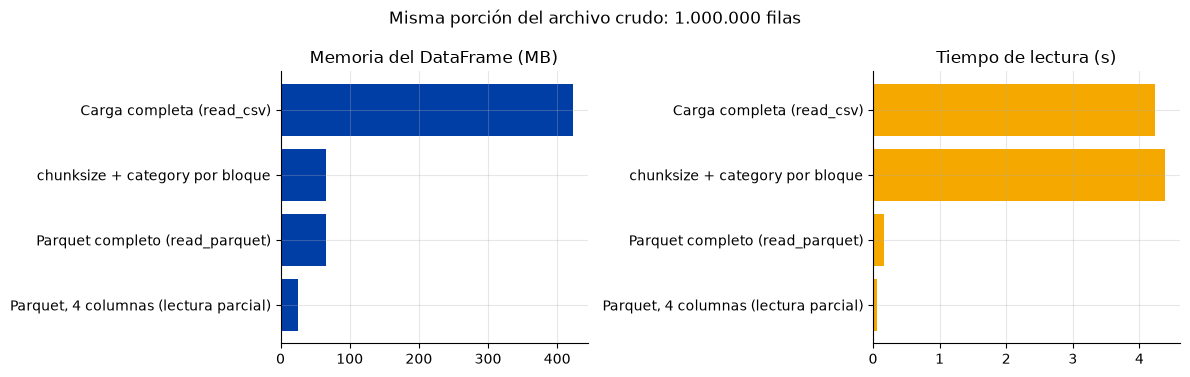

In [50]:
# ============================================================
# BLOQUE 15 · NIVEL 3 · CARGA COMPLETA vs CHUNKSIZE vs PARQUET   (PC2)
# ============================================================
import gc

EJECUTAR_BENCHMARK = True        # ✏️ False para omitirla (tarda 2–4 min)
FILAS_BENCHMARK = 1_000_000      # mismas filas para las tres estrategias


def medir_carga(nombre, funcion, archivo_mb):
    gc.collect()
    t0 = time.perf_counter()
    df = funcion()
    segundos = time.perf_counter() - t0
    fila = {"estrategia": nombre, "filas": len(df), "columnas": df.shape[1], "tiempo_s": round(segundos, 2),
            "memoria_mb": round(medir_memoria_mb(df), 1), "archivo_mb": round(archivo_mb, 1)}
    return fila, df


if EJECUTAR_BENCHMARK and NIVEL == 3 and FORMATO == "csv" and not MODO_DEMO:
    lectura = dict(sep=SEPARADOR, encoding=CODIFICACION, dtype=DTYPE_LECTURA)
    filas_archivo = LECTURA_INFO.get("filas_leidas") or len(df_crudo)
    csv_mb = RUTA_CRUDO.stat().st_size / 1024 ** 2 * min(FILAS_BENCHMARK, filas_archivo) / filas_archivo   # porción del CSV leída

    def carga_completa():
        return pd.read_csv(RUTA_CRUDO, nrows=FILAS_BENCHMARK, low_memory=False, **lectura)

    def carga_por_bloques():
        partes = []
        with pd.read_csv(RUTA_CRUDO, nrows=FILAS_BENCHMARK, chunksize=250_000, **lectura) as lector:
            for bloque in lector:
                partes.append(comprimir_bloque(bloque))
        return unir_bloques(partes)

    resultados_carga = []
    fila, df_tmp = medir_carga("1. Carga completa (read_csv)", carga_completa, csv_mb)
    resultados_carga.append(fila); del df_tmp
    fila, df_bloques = medir_carga("2. chunksize + category por bloque", carga_por_bloques, csv_mb)
    resultados_carga.append(fila)

    ruta_pq_bench = DIR_SALIDAS / "benchmark_crudo.parquet"
    df_bloques.to_parquet(ruta_pq_bench, index=False)
    pq_mb = ruta_pq_bench.stat().st_size / 1024 ** 2
    columnas_pq = list(df_bloques.columns[[4, 8, 12, 14]])        # fecha, tipo de crédito, tasa, monto
    del df_bloques
    fila, df_tmp = medir_carga("3. Parquet completo (read_parquet)", lambda: pd.read_parquet(ruta_pq_bench), pq_mb)
    resultados_carga.append(fila); del df_tmp
    fila, df_tmp = medir_carga("4. Parquet, 4 columnas (lectura parcial)",
                               lambda: pd.read_parquet(ruta_pq_bench, columns=columnas_pq), pq_mb)
    resultados_carga.append(fila); del df_tmp
    gc.collect()

    tabla_benchmark = pd.DataFrame(resultados_carga)
    base = tabla_benchmark.iloc[0]
    tabla_benchmark["memoria_vs_completa"] = (tabla_benchmark["memoria_mb"] / base["memoria_mb"]).map("{:.0%}".format)
    tabla_benchmark["tiempo_vs_completa"] = (tabla_benchmark["tiempo_s"] / base["tiempo_s"]).map("{:.0%}".format)
    display(tabla_benchmark)
    tabla_benchmark.to_csv(DIR_SALIDAS / "benchmark_carga.csv", index=False, encoding="utf-8-sig")

    fig, ejes = plt.subplots(1, 2, figsize=(12, 3.8))
    etiquetas = tabla_benchmark["estrategia"].str.replace(r"^\d\. ", "", regex=True)
    ejes[0].barh(etiquetas[::-1], tabla_benchmark["memoria_mb"][::-1], color="#003DA5"); ejes[0].set_title("Memoria del DataFrame (MB)")
    ejes[1].barh(etiquetas[::-1], tabla_benchmark["tiempo_s"][::-1], color="#F5A800"); ejes[1].set_title("Tiempo de lectura (s)")
    fig.suptitle(f"Misma porción del archivo crudo: {fmt(FILAS_BENCHMARK)} filas")
    plt.tight_layout(); plt.show()
else:
    print("Comparación de cargas omitida (solo aplica a nivel 3 con CSV y MODO_DEMO = False).")

### Diagrama del pipeline (Evidencia E5)

Se dibuja con las cifras de **esta** ejecución (filas por etapa, reglas, decisiones y archivos) y se guarda como `salidas/diagrama_pipeline.png`.

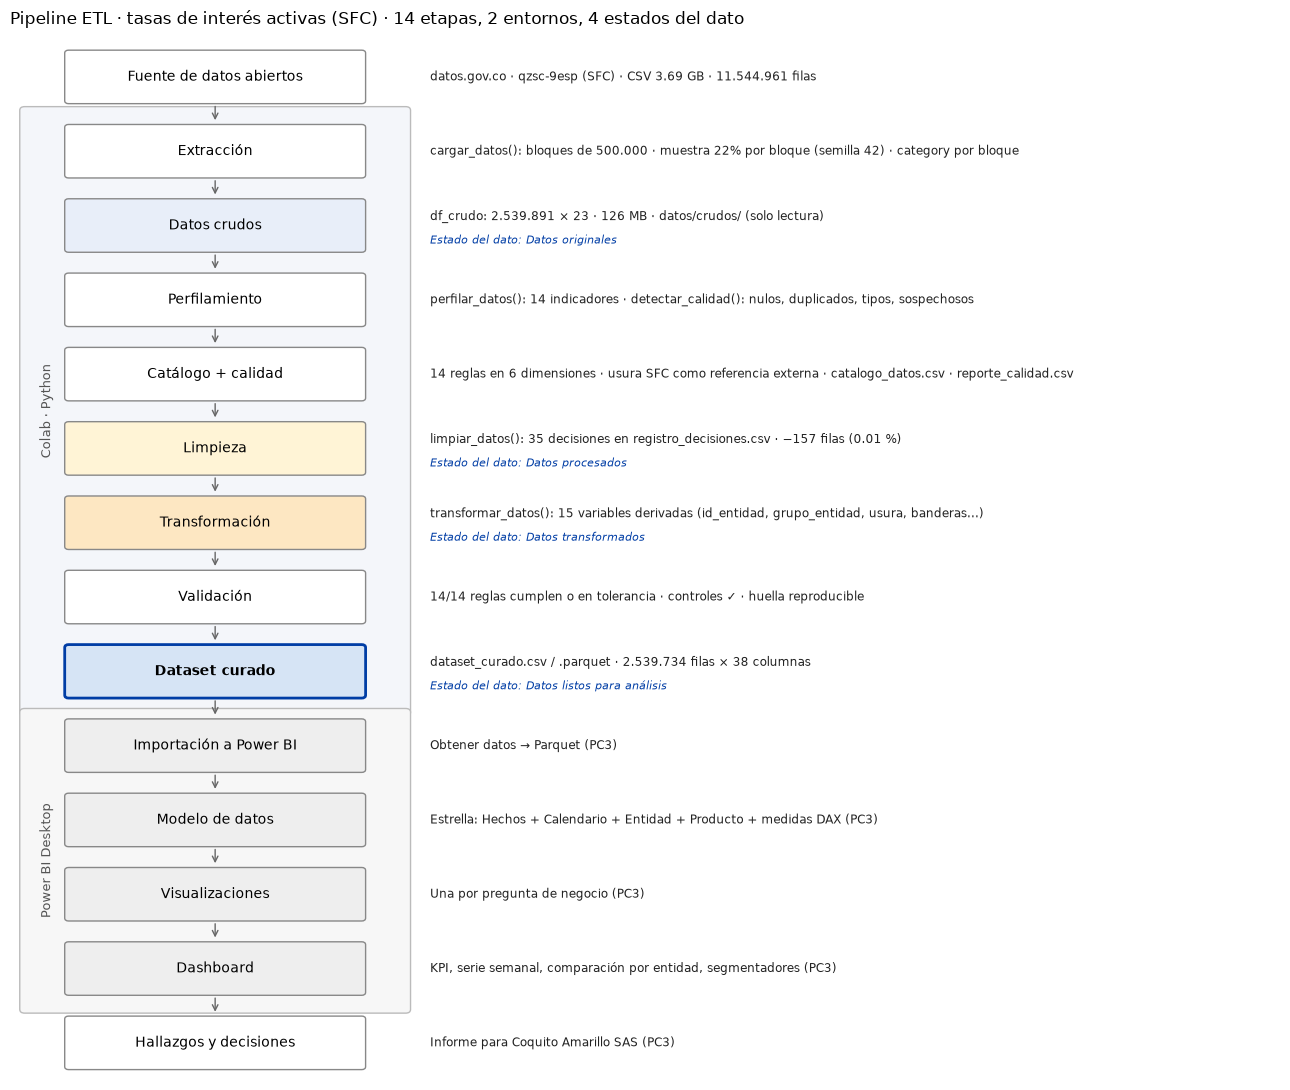

Diagrama guardado en: c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\salidas\diagrama_pipeline.png


In [51]:
# ============================================================
# BLOQUE 15 · DIAGRAMA DEL PIPELINE CON LAS CIFRAS REALES   (PC2 · Evidencia E5)
# Se dibuja con los resultados de esta ejecución y se guarda en salidas/diagrama_pipeline.png
# ============================================================
import matplotlib.patches as mpatches


def dibujar_pipeline(res, ruta_png):
    crudo, curado, reg = res["df_crudo"], res["df_curado"], res["registro"]
    rep = res["reporte_calidad"]
    leidas = LECTURA_INFO.get("filas_leidas", len(crudo))
    n_ok = int(rep["estado_final"].isin(["Cumple", "Dentro de tolerancia"]).sum())
    n_dec = int((~reg["paso"].isin(["Calendario", "Tipos finales"])).sum())
    derivadas = [c for c in curado.columns if c not in set(estandarizar_nombre(x) for x in crudo.columns)]
    perdidas = len(crudo) - len(curado)
    estados = {"orig": "#E8EEF9", "proc": "#FFF4D6", "trans": "#FDE7C2", "listo": "#D6E4F5", "pbi": "#EEEEEE", "": "#FFFFFF"}
    etapas = [
        ("Fuente de datos abiertos", f"datos.gov.co · qzsc-9esp (SFC) · CSV {RUTA_CRUDO.stat().st_size / 1024**3:,.2f} GB · {fmt(leidas)} filas", ""),
        ("Extracción", f"cargar_datos(): bloques de {fmt(TAMANO_CHUNK)} · muestra {FRACCION_MUESTRA:.0%} por bloque (semilla {SEMILLA_MUESTRA}) · category por bloque", ""),
        ("Datos crudos", f"df_crudo: {fmt(len(crudo))} × {crudo.shape[1]} · {medir_memoria_mb(crudo):,.0f} MB · datos/crudos/ (solo lectura)", "orig"),
        ("Perfilamiento", "perfilar_datos(): 14 indicadores · detectar_calidad(): nulos, duplicados, tipos, sospechosos", ""),
        ("Catálogo + calidad", f"{len(REGLAS_CALIDAD)} reglas en {rep['dimension'].nunique()} dimensiones · usura SFC como referencia externa · catalogo_datos.csv · reporte_calidad.csv", ""),
        ("Limpieza", f"limpiar_datos(): {n_dec} decisiones en registro_decisiones.csv · −{fmt(perdidas)} filas ({100 * perdidas / max(len(crudo), 1):.2f} %)", "proc"),
        ("Transformación", f"transformar_datos(): {len(derivadas)} variables derivadas (id_entidad, grupo_entidad, usura, banderas…)", "trans"),
        ("Validación", f"{n_ok}/{len(rep)} reglas cumplen o en tolerancia · controles {'✓' if res['valido'] else '✗'} · huella reproducible", ""),
        ("Dataset curado", f"dataset_curado.csv / .parquet · {fmt(len(curado))} filas × {curado.shape[1]} columnas", "listo"),
        ("Importación a Power BI", "Obtener datos → Parquet (PC3)", "pbi"),
        ("Modelo de datos", "Estrella: Hechos + Calendario + Entidad + Producto + medidas DAX (PC3)", "pbi"),
        ("Visualizaciones", "Una por pregunta de negocio (PC3)", "pbi"),
        ("Dashboard", "KPI, serie semanal, comparación por entidad, segmentadores (PC3)", "pbi"),
        ("Hallazgos y decisiones", "Informe para Coquito Amarillo SAS (PC3)", ""),
    ]
    nombres_estado = {"orig": "Datos originales", "proc": "Datos procesados", "trans": "Datos transformados", "listo": "Datos listos para análisis"}
    fig, ax = plt.subplots(figsize=(13, 11))
    ax.set_xlim(0, 13); ax.set_ylim(-0.5, len(etapas) - 0.4); ax.axis("off")
    ax.add_patch(mpatches.FancyBboxPatch((0.15, len(etapas) - 9.55), 3.9, 8.1, boxstyle="round,pad=0.05", fc="#F4F6FA", ec="#BBBBBB"))
    ax.add_patch(mpatches.FancyBboxPatch((0.15, len(etapas) - 13.55), 3.9, 4.0, boxstyle="round,pad=0.05", fc="#F7F7F7", ec="#BBBBBB"))
    ax.text(0.37, len(etapas) - 5.5, "Colab · Python", fontsize=9, color="#555555", rotation=90, ha="center", va="center")
    ax.text(0.37, len(etapas) - 11.55, "Power BI Desktop", fontsize=9, color="#555555", rotation=90, ha="center", va="center")
    for i, (titulo, detalle, estado) in enumerate(etapas):
        y = len(etapas) - 1 - i
        borde = "#003DA5" if estado == "listo" else "#888888"
        ax.add_patch(mpatches.FancyBboxPatch((0.6, y - 0.32), 3.0, 0.64, boxstyle="round,pad=0.04",
                                             fc=estados[estado], ec=borde, lw=2 if estado == "listo" else 1))
        ax.text(2.1, y, titulo, ha="center", va="center", fontsize=10, fontweight="bold" if estado == "listo" else "normal")
        ax.text(4.3, y + (0.12 if estado in nombres_estado else 0), detalle, va="center", fontsize=8.5, color="#222222")
        if estado in nombres_estado:
            ax.text(4.3, y - 0.2, f"Estado del dato: {nombres_estado[estado]}", va="center", fontsize=8, color="#003DA5", style="italic")
        if i < len(etapas) - 1:
            ax.annotate("", xy=(2.1, y - 0.62), xytext=(2.1, y - 0.36), arrowprops=dict(arrowstyle="->", color="#666666"))
    ax.set_title("Pipeline ETL · tasas de interés activas (SFC) · 14 etapas, 2 entornos, 4 estados del dato", fontsize=12, loc="left")
    plt.tight_layout()
    fig.savefig(ruta_png, dpi=150, bbox_inches="tight")
    plt.show()
    return ruta_png


ruta_diagrama = dibujar_pipeline(resultados, DIR_SALIDAS / "diagrama_pipeline.png")
print(f"Diagrama guardado en: {ruta_diagrama}")

**✅ Evidencia.** Tabla de archivos exportados y, en niveles 2 y 3, la comparación CSV / Parquet.

**💭 Pregunta de reflexión.** Si un compañero recibe solo `dataset_curado.csv`, sin catálogo ni reporte, ¿qué errores de interpretación podría cometer?

✍️ *Respuesta:*

Sin el catálogo ni el reporte, un compañero podría:
1. **Sumar los montos como si fueran el total nacional.** Son una muestra aleatoria del 22 %, así que el total real es ≈ 4,5 veces mayor (registro de decisiones, paso "Alcance").
2. **Promediar la tasa con los ceros incluidos y sin ponderar por monto.** Subestimaría el costo del crédito en ~6 a 9 puntos (`es_tasa_cero`).
3. **Leer 'No aplica' como dato faltante** y concluir que "falta el sexo en el 8 % de las filas", cuando son personas jurídicas.
4. **Abrir el CSV en Excel o Power BI con los códigos como número:** perdería los ceros a la izquierda (05001 → 5001; 0010 → 10) y los municipios de Antioquia ya no cruzarían con el DANE. Parquet conserva el tipo texto; el CSV no.
5. **Usar `codigo_entidad` como clave,** mezclando Banco de Bogotá con Bancoldex y con la Cooperativa Financiera de Antioquia (todas tienen código 1).
6. **Interpretar `margen_adicional` negativo o `supera_usura` como errores,** o ignorar que la tasa es efectiva anual y que los montos están en pesos corrientes.

## Bloque 16 · Visualización exploratoria

**🧭 Contexto.** Antes de diseñar el dashboard conviene mirar el dataset curado con gráficos rápidos. Estos gráficos **no reemplazan** a Power BI: sirven para descubrir patrones y detectar errores residuales.

| | Exploración de datos con Python | Comunicación analítica con Power BI |
|---|---|---|
| Audiencia | Usted y su equipo | Usuarios de negocio que deciden |
| Objetivo | Descubrir, verificar, generar hipótesis | Responder preguntas definidas y sostener decisiones |
| Forma | Muchos gráficos rápidos, desechables | Pocos visuales cuidados, con contexto e interactividad |
| Pregunta guía | *¿Qué hay en los datos?* | *¿Qué debe saber y hacer el usuario?* |

**🎯 Reto.** Defina las columnas principales y, para cada gráfico, escriba qué patrón o anomalía observa y qué pregunta de negocio sugiere.

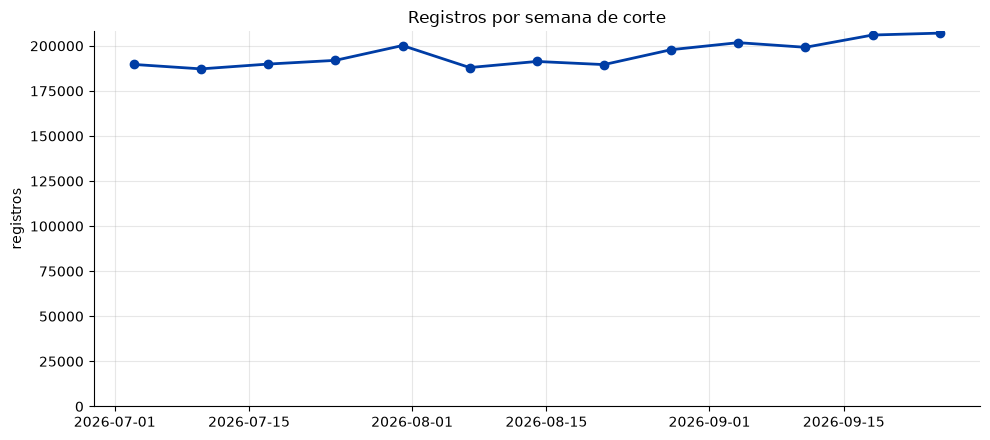

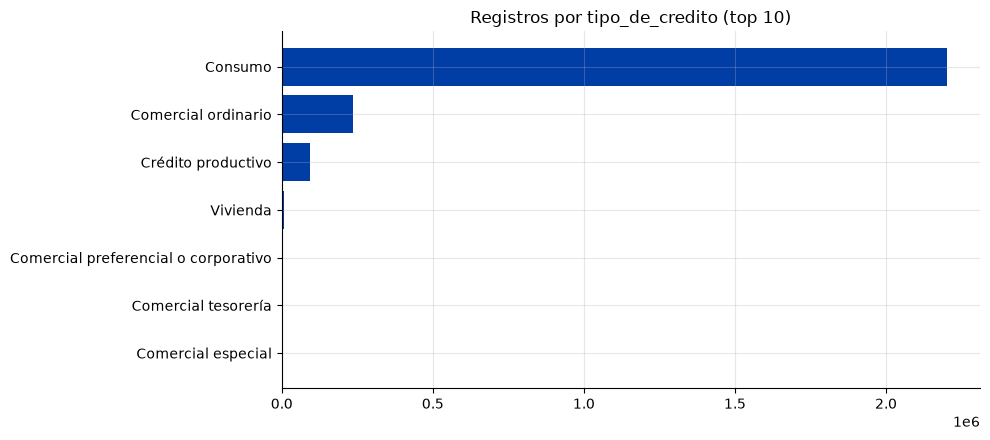

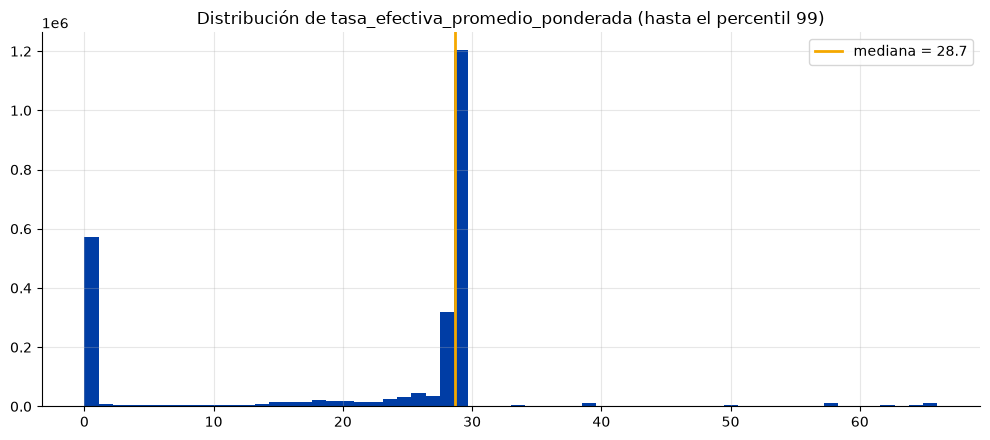

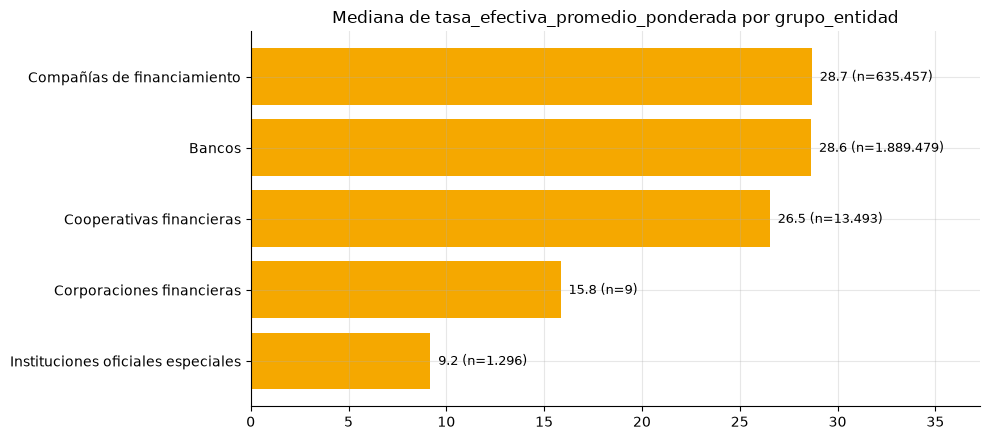

In [52]:
# ============================================================
# BLOQUE 16 · VISUALIZACIÓN EXPLORATORIA            ✏️ EDITAR
# ============================================================
COLUMNA_CATEGORIA_PRINCIPAL = "tipo_de_credito"                   # ✏️ modalidad de crédito (preguntas 3 y 4)
COLUMNA_NUMERICA_PRINCIPAL = "tasa_efectiva_promedio_ponderada"   # ✏️ costo del crédito (% E.A.)
COLUMNA_TERRITORIO = "grupo_entidad"   # ✏️ el archivo solo trae el código DIVIPOLA (≈ 1.100 municipios, sin nombre):
                                       #    se compara por grupo de entidad, que es lo que pide la pregunta 2
FRECUENCIA_SERIE = "W-FRI"             # los cortes son semanales (viernes)
if MODO_DEMO:
    COLUMNA_CATEGORIA_PRINCIPAL, COLUMNA_NUMERICA_PRINCIPAL, COLUMNA_TERRITORIO = "tipo_solicitud", "duracion_horas", "municipio"
    FRECUENCIA_SERIE = "MS"

AZUL, ORO = "#003DA5", "#F5A800"
d = df_curado

if COLUMNA_FECHA_PRINCIPAL in d.columns:
    serie = d.set_index(COLUMNA_FECHA_PRINCIPAL).resample(FRECUENCIA_SERIE).size()
    fig, ax = plt.subplots()
    ax.plot(serie.index, serie.values, color=AZUL, lw=2, marker="o")
    ax.set_title("Registros por semana de corte" if FRECUENCIA_SERIE.startswith("W") else "Registros por mes")
    ax.set_ylabel("registros"); ax.set_ylim(bottom=0)
    plt.tight_layout(); plt.show()

if COLUMNA_CATEGORIA_PRINCIPAL in d.columns:
    top = d[COLUMNA_CATEGORIA_PRINCIPAL].value_counts().head(10).sort_values()
    fig, ax = plt.subplots()
    ax.barh(top.index.astype(str), top.values, color=AZUL)
    ax.set_title(f"Registros por {COLUMNA_CATEGORIA_PRINCIPAL} (top 10)")
    plt.tight_layout(); plt.show()

if COLUMNA_NUMERICA_PRINCIPAL in d.columns:
    x = d[COLUMNA_NUMERICA_PRINCIPAL].dropna()
    p99 = x.quantile(0.99)
    fig, ax = plt.subplots()
    ax.hist(x[x <= p99], bins=60, color=AZUL)
    ax.axvline(x.median(), color=ORO, lw=2, label=f"mediana = {x.median():,.1f}")
    ax.set_title(f"Distribución de {COLUMNA_NUMERICA_PRINCIPAL} (hasta el percentil 99)")
    ax.legend(); plt.tight_layout(); plt.show()

if COLUMNA_TERRITORIO in d.columns and COLUMNA_NUMERICA_PRINCIPAL in d.columns:
    resumen = (d.groupby(COLUMNA_TERRITORIO, observed=True)[COLUMNA_NUMERICA_PRINCIPAL]
                 .agg(["median", "count"]).sort_values("median"))
    fig, ax = plt.subplots()
    ax.barh(resumen.index.astype(str), resumen["median"], color=ORO)
    for i, (m, n) in enumerate(zip(resumen["median"], resumen["count"])):
        ax.text(m, i, f"  {m:,.1f} (n={fmt(n)})", va="center", fontsize=9)
    ax.set_xlim(0, resumen["median"].max() * 1.3)
    ax.set_title(f"Mediana de {COLUMNA_NUMERICA_PRINCIPAL} por {COLUMNA_TERRITORIO}")
    plt.tight_layout(); plt.show()

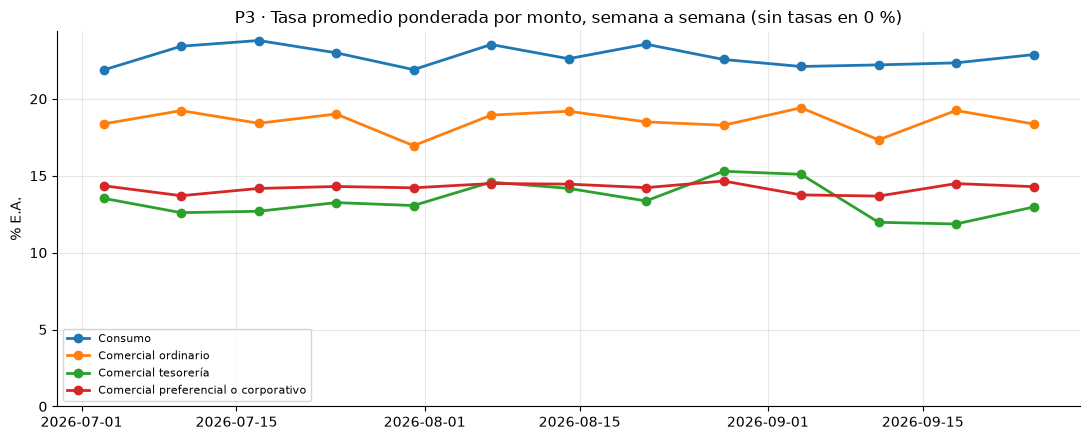

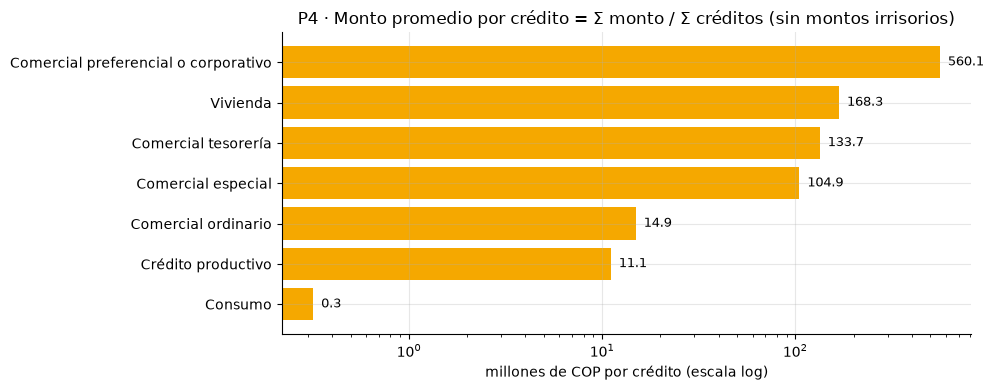

**P5 · Registros que deben aislarse o explicarse antes de llegar a la gerencia**

,filas,% del dataset
Filas con tasa 0 % (compras a una cuota),563103,22.172
Filas sobre la usura vigente,0,0.000
Filas con monto promedio < $1.000,2158,0.085
Filas con monto atípico extremo,699,0.028


In [53]:
# ============================================================
# BLOQUE 16 · VISUALIZACIÓN EXPLORATORIA PROPIA (preguntas 3 y 4)   (PC2)
# Tasa promedio PONDERADA POR MONTO = Σ(tasa × monto) / Σ(monto); se excluyen las tasas en 0 %
# ============================================================
if not MODO_DEMO:
    base = d[~d["es_tasa_cero"]].assign(tasa_x_monto=lambda x: x["tasa_efectiva_promedio_ponderada"] * x["montos_desembolsados"])
    semanal = (base.groupby([COLUMNA_FECHA_PRINCIPAL, "tipo_de_credito"], observed=True)[["tasa_x_monto", "montos_desembolsados"]].sum()
                   .assign(tasa_ponderada=lambda x: x["tasa_x_monto"] / x["montos_desembolsados"])["tasa_ponderada"].unstack())
    fig, ax = plt.subplots(figsize=(11, 4.5))
    for tipo in [c for c in ["Consumo", "Comercial ordinario", "Comercial tesorería", "Comercial preferencial o corporativo"] if c in semanal.columns]:
        ax.plot(semanal.index, semanal[tipo], marker="o", lw=2, label=tipo)
    ax.set_title("P3 · Tasa promedio ponderada por monto, semana a semana (sin tasas en 0 %)")
    ax.set_ylabel("% E.A."); ax.set_ylim(bottom=0); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    por_tipo = (d[~d["es_monto_irrisorio"]].groupby("tipo_de_credito", observed=True)
                  .agg(monto=("montos_desembolsados", "sum"), creditos=("numero_de_creditos_desembolsados", "sum")))
    por_tipo["monto_promedio_millones"] = por_tipo["monto"] / por_tipo["creditos"].astype(float) / 1e6
    por_tipo = por_tipo.sort_values("monto_promedio_millones")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(por_tipo.index.astype(str), por_tipo["monto_promedio_millones"], color=ORO)
    for i, v in enumerate(por_tipo["monto_promedio_millones"]):
        ax.text(v, i, f"  {v:,.1f}", va="center", fontsize=9)
    ax.set_xscale("log"); ax.set_xlabel("millones de COP por crédito (escala log)")
    ax.set_title("P4 · Monto promedio por crédito = Σ monto / Σ créditos (sin montos irrisorios)")
    plt.tight_layout(); plt.show()

    resumen_p5 = pd.Series({
        "Filas con tasa 0 % (compras a una cuota)": int(d["es_tasa_cero"].sum()),
        "Filas sobre la usura vigente": int(d["supera_usura"].sum()),
        "Filas con monto promedio < $1.000": int(d["es_monto_irrisorio"].sum()),
        "Filas con monto atípico extremo": int(d["es_atipico_montos_desembolsados"].sum()),
    }, name="filas").to_frame()
    resumen_p5["% del dataset"] = (100 * resumen_p5["filas"] / len(d)).round(3)
    display(Markdown("**P5 · Registros que deben aislarse o explicarse antes de llegar a la gerencia**"))
    display(resumen_p5)

**✅ Evidencia.** Cuatro gráficos exploratorios con una observación escrita para cada uno.

✍️ *Observaciones:* (verifique cada cifra con su gráfico; las del portal son de referencia)
1. **Serie semanal:** el número de registros por semana es estable, sin semanas vacías: en el portal está entre 850.942 y 949.331 por corte (unos 190.000 a 210.000 en la muestra del 22 %). El monto desembolsado sí tiene picos en las semanas de cierre de mes (31-jul: 19,9 billones; 28-ago: 18,3; 2-oct: 19,7, frente a 12,5–14,5 en semanas intermedias). Esto sugiere estacionalidad de fin de mes para la pregunta 3.
2. **Categorías:** *Consumo* concentra cerca del 87 % de las filas, pero no del dinero. En el portal, comercial ordinario aporta 105,9 billones (47 % del monto) con el 9 % de las filas. Contar filas no sirve para medir el mercado: en Power BI se usará el monto.
3. **Distribución de la tasa:** es bimodal. Hay un pico en 0 % (≈ 22 % de las filas, compras a una cuota), una masa principal entre 15 % y 30 % E.A. y una cola hasta ≈ 89 % que corresponde al crédito popular productivo (microcrédito, con su propia usura de ≈ 88–90 %). Una sola "tasa promedio" no describe este mercado.
4. **Grupo de entidad:** la mediana incluye las tasas en 0 %, que se concentran en las tarjetas de bancos y compañías de financiamiento, y por eso puede bajar. Sin los ceros, el promedio simple del portal es: compañías de financiamiento 29,1 %, bancos 28,7 %, cooperativas 25,0 % e instituciones oficiales especiales (Findeter, Bancoldex, FNA) 10,0 %. Los bancos desembolsan el 92,8 % del monto del portal, lo que responde a la pregunta 2.

Los gráficos adicionales muestran la **tasa ponderada por monto semana a semana** por tipo de crédito (P3), el **monto promedio por crédito** como Σ monto / Σ créditos (P4; en el portal: consumo ≈ $0,33 millones, comercial ordinario ≈ $14 millones, comercial preferencial ≈ $552 millones) y la **tabla de registros a aislar** (P5).

**💭 Pregunta de reflexión.** ¿Cuál de estos gráficos llevaría a Power BI tal como está, cuál cambiaría y cuál descartaría? ¿Por qué?

✍️ *Respuesta:*

- **Se lleva casi igual:** la serie semanal, pero como **tasa ponderada por monto** en vez de número de registros, con un segmentador por tipo de crédito. Responde directamente la pregunta 3.
- **Se cambia:** el gráfico de categorías. Contar filas engaña (consumo tiene 87 % de las filas y menos de un tercio del dinero), así que en Power BI será **monto desembolsado por tipo de crédito**, con barras horizontales ordenadas y eje desde cero. El de grupo de entidad pasa a ser **participación % del monto** (P2), con barras y no con un gráfico circular.
- **Se descarta:** el histograma de la tasa. Es útil para explorar (mostró el pico en 0 % y la cola del microcrédito), pero un usuario de negocio no decide con una distribución. En el dashboard queda resumido en un KPI ("22 % de las filas son compras a una cuota sin interés") y en la nota que explica por qué se excluyen.

## Bloque 16 (b) · Respuestas a las preguntas de negocio con el dataset curado

Antes de llevar los datos a Power BI se responden aquí las 5 preguntas de la ficha E1 con **las mismas fórmulas que tendrán las medidas DAX**:

- **Tasa ponderada por monto** = Σ(tasa × monto) / Σ(monto), sin las tasas en 0 %.
- **Monto promedio por crédito** = Σ monto / Σ créditos.
- **Participación** = monto del grupo / monto total.

Si Power BI da un número distinto, el error está en el modelo, no en los datos. Los resultados quedan en `RESPUESTAS_NEGOCIO` y alimentan el informe de hallazgos (E9) del bloque 17 y la reflexión del bloque 18.

**P1 · Entidades con menor tasa ponderada en crédito comercial preferencial o corporativo** (mínimo 30 créditos en la muestra; tasa promedio del mercado: 14,20 %)

,tasa_ponderada,monto,creditos,participacion_monto_%
nombre_entidad,,,,
Banco Caja Social S.A.,12.04,7.434198e+10,87.0,1.37
Banco Davivienda,13.92,9.738621e+11,315.0,17.89
Banco de Bogotá,13.99,6.336975e+11,338.0,11.64
Bancolombia,14.02,1.979104e+12,1478.0,36.35
BBVA Colombia,14.16,7.293803e+11,129.0,13.40
AV Villas,14.32,1.331201e+11,68.0,2.44
Banco de Occidente,14.40,1.969955e+11,45.0,3.62
Citibank,14.53,3.286295e+11,4080.0,6.04
Banco Santander,15.83,3.954997e+11,3625.0,7.26


**P2 · Participación del monto desembolsado por grupo de entidad**

,monto,creditos,filas,participacion_monto_%,participacion_creditos_%,tasa_ponderada
grupo_entidad,,,,,,
Bancos,4.328631e+13,38933012,1889479,93.08,80.25,19.33
Compañías de financiamiento,2.073618e+12,9533639,635457,4.46,19.65,25.82
Instituciones oficiales especiales,9.781925e+11,25776,1296,2.10,0.05,10.33
Cooperativas financieras,1.601070e+11,24240,13493,0.34,0.05,21.11
Corporaciones financieras,4.265203e+09,130,9,0.01,0.00,15.94


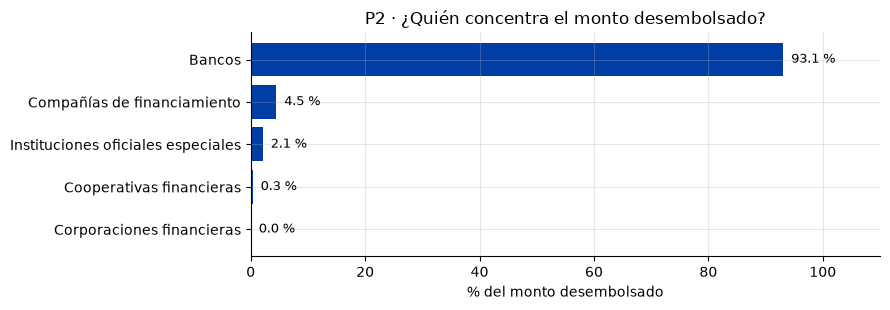

**P3 · Tasa ponderada por monto (sin 0 %), semana a semana**

tipo_de_credito,Comercial tesorería,Consumo
fecha_corte,,
2026-07-03,13.53,21.88
2026-07-10,12.60,23.42
2026-07-17,12.69,23.79
2026-07-24,13.25,22.99
2026-07-31,13.06,21.90
2026-08-07,14.58,23.53
2026-08-14,14.18,22.61
2026-08-21,13.36,23.55
2026-08-28,15.29,22.56


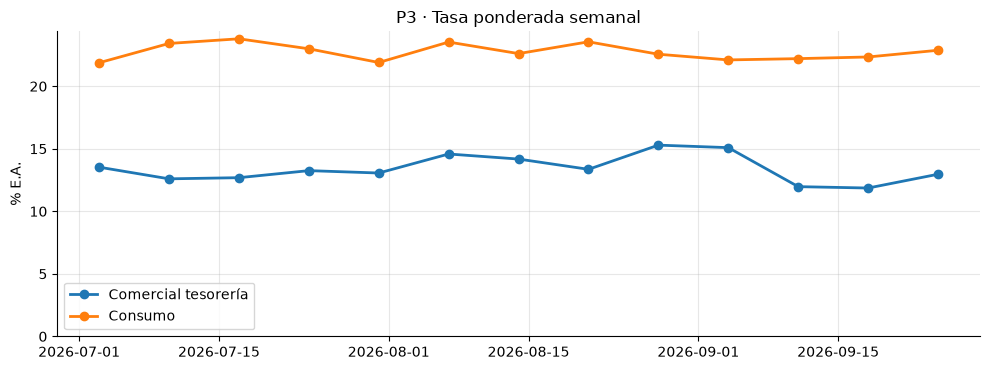

**P4 · Monto promedio por crédito y tasa ponderada por tipo de crédito** (correlación log10(monto promedio) vs tasa: -0.57)

,monto,creditos,monto_promedio_credito,tasa_ponderada
tipo_de_credito,,,,
Consumo,1.492560e+13,46877404,3.183964e+05,22.70
Crédito productivo,1.113084e+12,100450,1.108098e+07,36.75
Comercial ordinario,2.253560e+13,1511288,1.491152e+07,18.53
Comercial especial,9.847981e+10,939,1.048773e+08,13.84
Comercial tesorería,6.184730e+11,4625,1.337239e+08,13.24
Vivienda,1.477084e+12,8778,1.682712e+08,13.44
Comercial preferencial o corporativo,5.734168e+12,10237,5.601415e+08,14.20


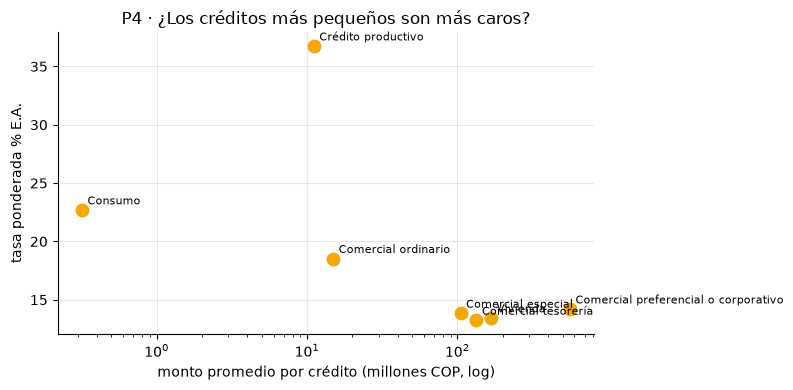

**P5 · Registros a aislar por semana** (además, 157 filas con monto < $1 se eliminaron en la limpieza)

,filas,supera_usura,monto_irrisorio,tasa_cero,monto_atipico,%_a_aislar
fecha_corte,,,,,,
2026-07-03,189684,0,188,44170,63,0.099
2026-07-10,187224,0,178,47714,52,0.095
2026-07-17,189894,0,172,42808,70,0.091
2026-07-24,191951,0,154,41906,47,0.080
2026-07-31,200180,0,165,42054,59,0.082
2026-08-07,187959,0,177,40498,46,0.094
2026-08-14,191343,0,136,42013,41,0.071
2026-08-21,189601,0,179,40835,59,0.094
2026-08-28,197868,0,160,46362,45,0.081


,valor
filas_archivo,11544961
filas_muestra,2539891
filas_curado,2539734
semanas,13
fecha_min,03-07-2026
fecha_max,25-09-2026
entidades,54
monto_muestra,46502491379063.765625
monto_estimado,211374960813926.21875
creditos_muestra,48516797


In [54]:
# ============================================================
# BLOQUE 16 (b) · RESPUESTAS A LAS PREGUNTAS DE NEGOCIO (P1–P5)
# ============================================================
RESPUESTAS_NEGOCIO = {}
d = df_curado


def tasa_ponderada(grupo):
    g = grupo[~grupo["es_tasa_cero"]]
    monto = g["montos_desembolsados"].sum()
    return (g["tasa_efectiva_promedio_ponderada"] * g["montos_desembolsados"]).sum() / monto if monto else np.nan


def millones(x):
    return f"${x / 1e6:,.1f} M".replace(",", "#").replace(".", ",").replace("#", ".")


def billones(x):
    return f"${x / 1e12:,.2f} billones".replace(",", "#").replace(".", ",").replace("#", ".")


def pct(x, dec=1):
    return f"{x:.{dec}f} %".replace(".", ",")


def fecha_es(ts, anio=False):
    """26-jun (o 26-jun-2026): meses en español sin depender del idioma del sistema."""
    return f"{ts.day:02d}-{MESES[ts.month - 1]}" + (f"-{ts.year}" if anio else "")


if not MODO_DEMO:
    # ---------- P1 · tres entidades con la menor tasa ponderada en comercial preferencial o corporativo
    MIN_CREDITOS_P1 = 30      # ✏️ umbral de representatividad: entidades con muy pocos créditos no se rankean
    pref = d[d["tipo_de_credito"].astype("object") == "Comercial preferencial o corporativo"]
    p1 = (pref.groupby("nombre_entidad", observed=True)
              .apply(lambda g: pd.Series({"tasa_ponderada": tasa_ponderada(g),
                                          "monto": g["montos_desembolsados"].sum(),
                                          "creditos": int(g["numero_de_creditos_desembolsados"].sum())}),
                     include_groups=False)
              .query("creditos >= @MIN_CREDITOS_P1").sort_values("tasa_ponderada"))
    p1["participacion_monto_%"] = (100 * p1["monto"] / p1["monto"].sum()).round(2)
    display(Markdown(f"**P1 · Entidades con menor tasa ponderada en crédito comercial preferencial o corporativo** "
                     f"(mínimo {MIN_CREDITOS_P1} créditos en la muestra; tasa promedio del mercado: "
                     f"{pct(tasa_ponderada(pref), 2)})"))
    display(p1.head(10).round(2))
    RESPUESTAS_NEGOCIO["P1"] = {"top3": p1.head(3).round(2).reset_index().to_dict("records"),
                                "tasa_mercado": tasa_ponderada(pref), "entidades": len(p1)}

    # ---------- P2 · concentración del monto por grupo de entidad
    p2 = (d.groupby("grupo_entidad", observed=True)
            .agg(monto=("montos_desembolsados", "sum"), creditos=("numero_de_creditos_desembolsados", "sum"),
                 filas=("montos_desembolsados", "size")).sort_values("monto", ascending=False))
    p2["participacion_monto_%"] = (100 * p2["monto"] / p2["monto"].sum()).round(2)
    p2["participacion_creditos_%"] = (100 * p2["creditos"].astype(float) / p2["creditos"].sum()).round(2)
    p2["tasa_ponderada"] = [tasa_ponderada(d[d["grupo_entidad"] == g]) for g in p2.index]
    display(Markdown("**P2 · Participación del monto desembolsado por grupo de entidad**"))
    display(p2.round(2))
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.barh(p2.index.astype(str)[::-1], p2["participacion_monto_%"][::-1], color=AZUL)
    for i, v in enumerate(p2["participacion_monto_%"][::-1]):
        ax.text(v, i, f"  {v:.1f} %", va="center", fontsize=9)
    ax.set_xlim(0, 110); ax.set_xlabel("% del monto desembolsado"); ax.set_title("P2 · ¿Quién concentra el monto desembolsado?")
    plt.tight_layout(); plt.savefig(DIR_SALIDAS / "fig_p2_participacion.png", dpi=150); plt.show()
    RESPUESTAS_NEGOCIO["P2"] = {"tabla": p2.round(2).reset_index().to_dict("records")}

    # ---------- P3 · tasa ponderada semana a semana: consumo y comercial tesorería
    tipos_p3 = ["Consumo", "Comercial tesorería"]
    p3 = (d[d["tipo_de_credito"].astype("object").isin(tipos_p3)]
            .groupby([COLUMNA_FECHA_PRINCIPAL, "tipo_de_credito"], observed=True)
            .apply(tasa_ponderada, include_groups=False).unstack())
    display(Markdown("**P3 · Tasa ponderada por monto (sin 0 %), semana a semana**"))
    display(p3.round(2))
    fig, ax = plt.subplots(figsize=(10, 3.8))
    for t in p3.columns:
        ax.plot(p3.index, p3[t], marker="o", lw=2, label=str(t))
    ax.set_ylim(bottom=0); ax.set_ylabel("% E.A."); ax.legend(); ax.set_title("P3 · Tasa ponderada semanal")
    plt.tight_layout(); plt.savefig(DIR_SALIDAS / "fig_p3_tasa_semanal.png", dpi=150); plt.show()
    RESPUESTAS_NEGOCIO["P3"] = {t: {"inicio": p3[t].dropna().iloc[0], "fin": p3[t].dropna().iloc[-1],
                                    "min": p3[t].min(), "max": p3[t].max(),
                                    "semana_min": fecha_es(p3[t].idxmin()), "semana_max": fecha_es(p3[t].idxmax()),
                                    "semana_ini": fecha_es(p3[t].dropna().index[0]),
                                    "semana_fin": fecha_es(p3[t].dropna().index[-1])}
                                for t in p3.columns}

    # ---------- P4 · monto promedio por crédito y tasa por tipo de crédito
    base4 = d[~d["es_monto_irrisorio"]]
    p4 = (base4.groupby("tipo_de_credito", observed=True)
                .agg(monto=("montos_desembolsados", "sum"), creditos=("numero_de_creditos_desembolsados", "sum")))
    p4["monto_promedio_credito"] = p4["monto"] / p4["creditos"].astype(float)
    p4["tasa_ponderada"] = [tasa_ponderada(base4[base4["tipo_de_credito"] == t]) for t in p4.index]
    p4 = p4.sort_values("monto_promedio_credito")
    correlacion = np.corrcoef(np.log10(p4["monto_promedio_credito"]), p4["tasa_ponderada"])[0, 1]
    display(Markdown(f"**P4 · Monto promedio por crédito y tasa ponderada por tipo de crédito** "
                     f"(correlación log10(monto promedio) vs tasa: {correlacion:.2f})"))
    display(p4.round(2))
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.scatter(p4["monto_promedio_credito"] / 1e6, p4["tasa_ponderada"], s=80, color=ORO)
    for t, r in p4.iterrows():
        ax.annotate(str(t), (r["monto_promedio_credito"] / 1e6, r["tasa_ponderada"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xscale("log"); ax.set_xlabel("monto promedio por crédito (millones COP, log)"); ax.set_ylabel("tasa ponderada % E.A.")
    ax.set_title("P4 · ¿Los créditos más pequeños son más caros?")
    plt.tight_layout(); plt.savefig(DIR_SALIDAS / "fig_p4_monto_vs_tasa.png", dpi=150); plt.show()
    RESPUESTAS_NEGOCIO["P4"] = {"tabla": p4.round(2).reset_index().to_dict("records"), "correlacion": correlacion}

    # ---------- P5 · registros que deben aislarse, por semana
    reg_final = resultados["registro"]
    eliminados_monto = int(reg_final.loc[(reg_final["columna"] == "montos_desembolsados") &
                                         reg_final["accion"].str.startswith("Fuera de"), "afectados"].sum())
    p5 = (d.groupby(COLUMNA_FECHA_PRINCIPAL)
            .agg(filas=("supera_usura", "size"), supera_usura=("supera_usura", "sum"),
                 monto_irrisorio=("es_monto_irrisorio", "sum"), tasa_cero=("es_tasa_cero", "sum"),
                 monto_atipico=("es_atipico_montos_desembolsados", "sum")))
    p5["%_a_aislar"] = (100 * (p5["supera_usura"] + p5["monto_irrisorio"]) / p5["filas"]).round(3)
    display(Markdown(f"**P5 · Registros a aislar por semana** (además, {fmt(eliminados_monto)} filas con monto < $1 "
                     "se eliminaron en la limpieza)"))
    display(p5)
    RESPUESTAS_NEGOCIO["P5"] = {"supera_usura": int(d["supera_usura"].sum()), "monto_irrisorio": int(d["es_monto_irrisorio"].sum()),
                                "tasa_cero": int(d["es_tasa_cero"].sum()), "monto_atipico": int(d["es_atipico_montos_desembolsados"].sum()),
                                "monto_menor_1_eliminados": eliminados_monto, "filas": len(d),
                                "semana_max_irrisorio": fecha_es(p5["monto_irrisorio"].idxmax(), anio=True)}

    # ---------- Cifras generales (para KPI, informe y reflexión)
    RESPUESTAS_NEGOCIO["general"] = {
        "filas_archivo": LECTURA_INFO.get("filas_leidas", len(resultados["df_crudo"])),
        "filas_muestra": len(resultados["df_crudo"]), "filas_curado": len(d),
        "semanas": d[COLUMNA_FECHA_PRINCIPAL].nunique(),
        "fecha_min": d[COLUMNA_FECHA_PRINCIPAL].min().strftime("%d-%m-%Y"), "fecha_max": d[COLUMNA_FECHA_PRINCIPAL].max().strftime("%d-%m-%Y"),
        "entidades": d["id_entidad"].nunique(), "monto_muestra": d["montos_desembolsados"].sum(),
        "monto_estimado": d["montos_desembolsados"].sum() / FRACCION_MUESTRA,
        "creditos_muestra": int(d["numero_de_creditos_desembolsados"].sum()),
        "tasa_ponderada_total": tasa_ponderada(d),
        "tasa_simple_con_ceros": d["tasa_efectiva_promedio_ponderada"].mean(),
        "pct_tasa_cero": 100 * d["es_tasa_cero"].mean(),
        "pct_filas_un_credito": 100 * (d["numero_de_creditos_desembolsados"] == 1).mean(),
    }
    display(pd.Series(RESPUESTAS_NEGOCIO["general"], name="valor").to_frame())

## Bloque 17 · Preparación para Power BI y lista de entrega

**🧭 Contexto.** Antes de abrir Power BI, confirme qué va a importar: ruta, tamaño, tipos y estado de calidad. La lista de entrega verifica automáticamente que el trabajo esté completo.

**🎯 Reto.** Todos los ítems de la lista deben quedar en ✅ antes de la entrega final. Los que estén en ❌ indican qué falta.

In [55]:
# ============================================================
# BLOQUE 17 · PREPARACIÓN PARA POWER BI
# ============================================================
def tipo_power_bi(serie):
    if pd.api.types.is_bool_dtype(serie):
        return "Verdadero/falso"
    if pd.api.types.is_datetime64_any_dtype(serie):
        return "Fecha/hora (o Fecha)"
    if pd.api.types.is_integer_dtype(serie):
        return "Número entero"
    if pd.api.types.is_float_dtype(serie):
        return "Número decimal"
    return "Texto"

ruta_final = DIR_SALIDAS / ("dataset_curado.parquet" if (DIR_SALIDAS / "dataset_curado.parquet").exists() else "dataset_curado.csv")
display(Markdown(f"**Archivo para Power BI:** `{ruta_final}`  \n"
                 f"**Registros:** {fmt(len(df_curado))} · **Columnas:** {df_curado.shape[1]} · "
                 f"**Memoria:** {medir_memoria_mb(df_curado):,.1f} MB"))
tipos = pd.DataFrame({"columna": df_curado.columns,
                      "tipo_pandas": [str(t) for t in df_curado.dtypes],
                      "tipo_power_bi_sugerido": [tipo_power_bi(df_curado[c]) for c in df_curado.columns],
                      "pct_nulos": (100 * df_curado.isna().mean()).round(2).values})
display(tipos)
rep = resultados["reporte_calidad"]
display(Markdown(f"**Estado de calidad:** {int(rep['estado_final'].isin(['Cumple', 'Dentro de tolerancia']).sum())}"
                 f" de {len(rep)} reglas cumplen o están dentro de tolerancia."))

# ------------------------------------------------------------
# Lista de entrega (se evalúa automáticamente)
# ------------------------------------------------------------
def sin_pendientes(valores):
    return all(MARCA_PENDIENTE not in str(v) and str(v).strip() != "" for v in valores)

cat = resultados["catalogo"]
cat_final = cat[~cat["tipo_dato"].str.contains("eliminada")]
reg = resultados["registro"]
chequeo = [
    ("Trabaja con su fuente real (MODO_DEMO = False)", not MODO_DEMO),
    ("Ficha de la fuente: 17 campos diligenciados", sin_pendientes(FICHA_FUENTE.values())),
    ("Lista de chequeo: 10 criterios evaluados con evidencia",
     all(v["cumple"] is not None and str(v["evidencia"]).strip() for v in CRITERIOS_FUENTE.values())),
    ("Entre 5 y 8 preguntas de negocio", 5 <= len(PREGUNTAS_NEGOCIO) <= 8),
    ("Al menos 5 reglas de calidad en 4 dimensiones",
     len(REGLAS_CALIDAD) >= 5 and len({r["dimension"] for r in REGLAS_CALIDAD}) >= 4),
    ("Cada regla con su problema documentado", len(REGLAS_CALIDAD) > 0 and
     all(r["id"] in PROBLEMAS_CALIDAD and sin_pendientes(PROBLEMAS_CALIDAD[r["id"]].values()) for r in REGLAS_CALIDAD)),
    ("Catálogo: descripción y sensibilidad completas", len(cat_final) > 0 and sin_pendientes(cat_final["descripcion"]) and sin_pendientes(cat_final["sensibilidad"])),
    ("≥ 5 decisiones propias de limpieza, todas justificadas",
     int((~reg["columna"].str.startswith("(") & ~reg["paso"].isin(["Calendario", "Tipos finales"])).sum()) >= 5
     and sin_pendientes(reg["justificacion"])),
    ("Al menos una variable propia creada", (reg["paso"] == "Variables propias").any()),
    ("Controles de salida en ✅", resultados["valido"]),
    ("Pipeline reproducible", reproducible),
    ("Archivos exportados", all((DIR_SALIDAS / f).exists() for f in ["dataset_curado.csv", "catalogo_datos.csv", "reporte_calidad.csv"])),
]
lista = pd.DataFrame(chequeo, columns=["item", "ok"])
lista["estado"] = lista["ok"].map({True: "✅", False: "❌"})
display(lista[["estado", "item"]])
if MODO_DEMO:
    print("ℹ Modo demostración: este resultado NO es entregable. Cambie MODO_DEMO a False y use su fuente.")
elif lista["ok"].all():
    print("🎉 Todo listo para Power BI y para la entrega.")
else:
    print(f"Pendientes: {int((~lista['ok']).sum())}")

**Archivo para Power BI:** `c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\salidas\dataset_curado.parquet`  
**Registros:** 2.539.734 · **Columnas:** 38 · **Memoria:** 312.5 MB

,columna,tipo_pandas,tipo_power_bi_sugerido,pct_nulos
0,tipo_entidad,int8,Número entero,0.0
1,nombre_tipo_entidad,category,Texto,0.0
2,codigo_entidad,int16,Número entero,0.0
3,nombre_entidad,category,Texto,0.0
4,fecha_corte,datetime64[ns],Fecha/hora (o Fecha),0.0
5,tipo_de_persona,category,Texto,0.0
6,sexo,category,Texto,0.0
7,tamano_de_empresa,category,Texto,0.0
8,tipo_de_credito,category,Texto,0.0
9,tipo_de_garantia,category,Texto,0.0


**Estado de calidad:** 14 de 14 reglas cumplen o están dentro de tolerancia.

,estado,item
0,✅,Trabaja con su fuente real (MODO_DEMO = False)
1,✅,Ficha de la fuente: 17 campos diligenciados
2,✅,Lista de chequeo: 10 criterios evaluados con evidencia
3,✅,Entre 5 y 8 preguntas de negocio
4,✅,Al menos 5 reglas de calidad en 4 dimensiones
5,✅,Cada regla con su problema documentado
6,✅,Catálogo: descripción y sensibilidad completas
7,✅,"≥ 5 decisiones propias de limpieza, todas justificadas"
8,✅,Al menos una variable propia creada
9,✅,Controles de salida en ✅


🎉 Todo listo para Power BI y para la entrega.


## Bloque 17 (b) · Informe de hallazgos (Evidencia E9) generado con las cifras del notebook

La guía exige que **toda cifra del informe se pueda rastrear a una celda del notebook o a una medida DAX**. Por eso el informe se escribe con código a partir de `RESPUESTAS_NEGOCIO`: si los datos cambian, el informe cambia solo.

El resultado es `salidas/informe_hallazgos.docx` (2–3 páginas): pregunta, respuesta con cifra, gráfico, limitaciones, riesgos y reflexión. Ábranlo en Word o en Google Docs, revisen la redacción y expórtenlo a PDF para la entrega.

In [56]:
# ============================================================
# BLOQUE 17 (b) · INFORME DE HALLAZGOS E9 → salidas/informe_hallazgos.docx
# ============================================================
import subprocess
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-docx"], check=True)
    import docx
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH


def generar_informe(R, ruta):
    g = R["general"]
    doc = docx.Document()
    for s in doc.sections:
        s.top_margin = s.bottom_margin = Cm(1.8); s.left_margin = s.right_margin = Cm(2.0)
    estilo = doc.styles["Normal"]; estilo.font.name = "Calibri"; estilo.font.size = Pt(10)

    def parrafo(texto, negrita_inicio=None, tam=None):
        p = doc.add_paragraph()
        if negrita_inicio:
            r = p.add_run(negrita_inicio); r.bold = True
        r = p.add_run(texto)
        if tam: r.font.size = Pt(tam)
        p.paragraph_format.space_after = Pt(4)
        return p

    def tabla(filas, encabezados):
        t = doc.add_table(rows=1, cols=len(encabezados)); t.style = "Light Grid Accent 1"
        for c, h in zip(t.rows[0].cells, encabezados):
            c.text = h
        for f in filas:
            celdas = t.add_row().cells
            for c, v in zip(celdas, f):
                c.text = str(v)
        for row in t.rows:
            for c in row.cells:
                for p in c.paragraphs:
                    for r in p.runs: r.font.size = Pt(8.5)
        doc.add_paragraph().paragraph_format.space_after = Pt(2)

    t = doc.add_heading("Tasas de interés activas en Colombia: costo y concentración del crédito", level=1)
    parrafo("Informe de hallazgos (E9) — Observatorio Datum para Coquito Amarillo SAS · Visualización de Datos, USB Medellín", tam=9)
    parrafo(f"Fuente: Superintendencia Financiera de Colombia, «Tasas de interés activas por tipo de crédito – Últimos dos meses» "
            f"(datos.gov.co, qzsc-9esp, CC BY-SA 4.0), descargado el {FICHA_FUENTE['fecha_consulta']}. "
            f"Cortes semanales del {g['fecha_min']} al {g['fecha_max']} ({g['semanas']} semanas). "
            f"Archivo de {fmt(g['filas_archivo'])} filas; se procesó una muestra aleatoria del {FRACCION_MUESTRA:.0%} por bloque "
            f"({fmt(g['filas_muestra'])} filas) y el dataset curado tiene {fmt(g['filas_curado'])} filas de {g['entidades']} entidades. "
            "Las tasas son efectivas anuales; los promedios se ponderan por monto y excluyen las compras a una cuota con tasa 0 %.", tam=9)

    doc.add_heading("1. Respuestas a las preguntas de negocio", level=2)
    p1 = R["P1"]
    top = "; ".join(f"{i + 1}) {r['nombre_entidad']} ({pct(r['tasa_ponderada'], 2)})" for i, r in enumerate(p1["top3"]))
    parrafo(f"Las tres entidades con menor tasa ponderada en crédito comercial preferencial o corporativo son: {top}. "
            f"El promedio ponderado del mercado en esta modalidad es {pct(p1['tasa_mercado'], 2)} "
            f"(ranking entre {p1['entidades']} entidades con al menos 30 créditos en la muestra).", "P1 · ¿Dónde financiar grandes operaciones más barato? ")
    tabla([[r["nombre_entidad"], pct(r["tasa_ponderada"], 2), fmt(r["creditos"]), pct(r["participacion_monto_%"])] for r in p1["top3"]],
          ["Entidad", "Tasa ponderada E.A.", "Créditos (muestra)", "% del monto preferencial"])

    p2 = R["P2"]["tabla"]
    lider = p2[0]
    otros = "; ".join(f"{r['grupo_entidad']} {pct(r['participacion_monto_%'])}" for r in p2[1:])
    parrafo(f"{lider['grupo_entidad']} concentran el {pct(lider['participacion_monto_%'])} del monto desembolsado y el "
            f"{pct(lider['participacion_creditos_%'])} de los créditos. Resto: {otros}.", "P2 · ¿Quién concentra el crédito? ")
    doc.add_picture(str(DIR_SALIDAS / "fig_p2_participacion.png"), width=Cm(13))

    textos_p3 = []
    for tipo, v in R["P3"].items():
        cambio = v["fin"] - v["inicio"]
        textos_p3.append(f"{tipo}: pasó de {pct(v['inicio'], 2)} ({v['semana_ini']}) a {pct(v['fin'], 2)} ({v['semana_fin']}), "
                         f"{'+' if cambio >= 0 else '−'}{abs(cambio):.2f} p.p.".replace(".", ",", 1) +
                         f"; mínimo {pct(v['min'], 2)} ({v['semana_min']}) y máximo {pct(v['max'], 2)} ({v['semana_max']})")
    parrafo(". ".join(textos_p3) + ".", "P3 · ¿Cómo fluctuó la tasa semana a semana? ")
    doc.add_picture(str(DIR_SALIDAS / "fig_p3_tasa_semanal.png"), width=Cm(15))

    p4 = R["P4"]["tabla"]
    menor, mayor = p4[0], p4[-1]
    parrafo(f"El monto promedio por crédito va de {millones(menor['monto_promedio_credito'])} en {menor['tipo_de_credito']} "
            f"(tasa {pct(menor['tasa_ponderada'], 2)}) a {millones(mayor['monto_promedio_credito'])} en {mayor['tipo_de_credito']} "
            f"(tasa {pct(mayor['tasa_ponderada'], 2)}). La correlación entre el logaritmo del monto promedio y la tasa es "
            f"{R['P4']['correlacion']:.2f}".replace(".", ",") + ": "
            + ("los créditos más pequeños son, en general, más caros." if R["P4"]["correlacion"] < -0.3
               else "no hay una relación clara entre tamaño y costo del crédito."), "P4 · ¿Los créditos pequeños son más caros? ")
    tabla([[r["tipo_de_credito"], millones(r["monto_promedio_credito"]), pct(r["tasa_ponderada"], 2)] for r in p4],
          ["Tipo de crédito", "Monto promedio por crédito", "Tasa ponderada E.A."])

    p5 = R["P5"]
    parrafo(f"{fmt(p5['supera_usura'])} filas superan la usura certificada por la SFC para su modalidad y semana; "
            f"{fmt(p5['monto_irrisorio'])} filas ({pct(100 * p5['monto_irrisorio'] / p5['filas'], 2)}) tienen un monto promedio "
            f"menor a $1.000 (máximo en la semana del {p5['semana_max_irrisorio']}) y {fmt(p5['monto_menor_1_eliminados'])} filas con monto "
            f"menor a $1 se eliminaron en la limpieza. Además, {pct(g['pct_tasa_cero'])} de las filas son compras a una cuota con tasa 0 %: "
            "no son errores, pero deben excluirse del costo promedio.", "P5 · ¿Qué debe aislarse antes de llegar a la gerencia? ")

    doc.add_heading("2. Hallazgo principal", level=2)
    parrafo(f"Un promedio simple de la tasa con los ceros incluidos da {pct(g['tasa_simple_con_ceros'], 2)}; el costo real ponderado "
            f"por monto y sin compras a una cuota es {pct(g['tasa_ponderada_total'], 2)}. Usar el primer número subestimaría el costo "
            "del crédito y llevaría a Coquito Amarillo SAS a presupuestar mal su financiación.")

    doc.add_heading("3. Limitaciones y riesgos que permanecen", level=2)
    for texto in [
        f"Muestra del {FRACCION_MUESTRA:.0%}: los totales absolutos son estimaciones (monto total estimado ≈ {billones(g['monto_estimado'])} "
        f"= monto de la muestra / {FRACCION_MUESTRA}); las tasas y participaciones sí son representativas.",
        "Datos agregados por la SFC: cada fila agrupa créditos; no hay microdatos ni identificador de deudor, por eso no se pueden "
        "eliminar duplicados por ID y solo se quitaron copias idénticas.",
        "Ventana de solo dos meses: no permite ver tendencias de largo plazo ni estacionalidad anual.",
        f"Riesgo de reidentificación: el {pct(g['pct_filas_un_credito'])} de las filas corresponde a un solo crédito; grupo étnico y sexo "
        "solo se muestran agregados (Ley 1581 de 2012).",
        "La usura se compara con certificaciones mensuales de la SFC y la semana de corte puede cruzar dos meses: se usó el tope mayor (criterio conservador).",
        "Los rangos de monto en SMLMV usan esquemas distintos según la entidad (1–3 vs. 1–2 y 2–3 SMLMV); se unificó la escritura, no los cortes.",
    ]:
        doc.add_paragraph(texto, style="List Bullet")
    parrafo("Todas las cifras provienen del notebook (bloque 16 b, RESPUESTAS_NEGOCIO) y coinciden con las medidas DAX del tablero.", tam=8)
    doc.save(ruta)
    return ruta


if not MODO_DEMO:
    ruta_informe = generar_informe(RESPUESTAS_NEGOCIO, DIR_SALIDAS / "informe_hallazgos.docx")
    print(f"Informe E9 guardado en: {ruta_informe}")

Informe E9 guardado en: c:\Users\Michell\Desktop\U_2026_2\visualizacion_datos\salidas\informe_hallazgos.docx


### Siguiente paso: Power BI Desktop (Evidencias E7 y E8)

La guía paso a paso del modelo y del tablero está en el documento **«Guía Power BI»** que acompaña este notebook. Resumen:

1. **Importar** `salidas/dataset_curado.parquet` (*Obtener datos → Parquet*). Conserva los tipos; con CSV hay que fijar los códigos como Texto. En Power Query no se limpia nada: la limpieza está aquí.
2. **Grano de la tabla de hechos `Hechos`:** *una fila = un grupo de créditos desembolsados por una entidad en una semana de corte, con la misma combinación de producto, plazo, tasa, segmento del deudor, CIIU y municipio*.
3. **Modelo en estrella:**
   - `Hechos`.
   - `Calendario` (DAX, marcada como tabla de fechas).
   - `Entidad` (`id_entidad`, nombre, tipo, grupo).
   - `Producto` (tipo de crédito, producto y modalidad de usura).

   Las relaciones son 1:* con filtro unidireccional.
4. **Medidas DAX explícitas** (las mismas fórmulas del bloque 16 b):

```DAX
Monto desembolsado = SUM ( Hechos[montos_desembolsados] )
Créditos desembolsados = SUM ( Hechos[numero_de_creditos_desembolsados] )
Monto promedio por crédito = DIVIDE ( [Monto desembolsado], [Créditos desembolsados] )
Tasa ponderada % =
VAR base = FILTER ( Hechos, Hechos[es_tasa_cero] = FALSE () )
RETURN DIVIDE ( SUMX ( base, Hechos[tasa_efectiva_promedio_ponderada] * Hechos[montos_desembolsados] ),
                SUMX ( base, Hechos[montos_desembolsados] ) )
Participación monto % = DIVIDE ( [Monto desembolsado], CALCULATE ( [Monto desembolsado], ALL ( Entidad[grupo_entidad] ) ) )
Filas sobre usura = CALCULATE ( COUNTROWS ( Hechos ), Hechos[supera_usura] = TRUE () )
Monto estimado nacional = DIVIDE ( [Monto desembolsado], 0.22 )
```

5. **Dashboard:**
   - Título con el hallazgo.
   - 4 KPI: tasa ponderada, monto estimado, % bancos y filas a aislar.
   - Serie semanal (P3), barras por entidad (P1), participación por grupo (P2), dispersión de monto contra tasa (P4) y tabla de alertas (P5).
   - Segmentadores de semana y tipo de crédito.
   - Fuente y fecha de corte, y 3 a 5 hallazgos con cifra (salen de `informe_hallazgos.docx`).
6. **Documentar cada visual:** pregunta · visual · por qué · alternativa descartada (tabla incluida en la guía).

## Bloque 18 · Reflexión técnica (criterio 10 de la rúbrica)

Responda con evidencia de **su** proyecto: cifras, nombres de columnas, reglas y decisiones concretas. *Las cifras de las respuestas 1, 2, 3 y 5 se calculan en la celda siguiente; verifíquenlas antes de entregar.*

**1. ¿Qué problema de calidad fue más importante y por qué?**

✍️ En lo técnico, los montos y el número de créditos guardados como texto con coma de miles (reglas R03 y R04): sin corregirlos no existe ninguna suma de dinero, y las preguntas 2 y 4 son imposibles. En interpretación, el más importante fue la **tasa 0 %**. No es un error (son compras con tarjeta a una cuota), pero si entra a un promedio simple, el costo del crédito baja varios puntos porcentuales y Coquito Amarillo SAS presupuestaría mal su financiación (ver cifras abajo).

**2. ¿Qué transformación tuvo mayor impacto en los resultados?**

✍️ Separar las tasas en 0 % (`es_tasa_cero`) y **ponderar la tasa por monto**. Cambia la tasa de referencia del mercado en varios puntos y es la base de las respuestas P1 y P3. En segundo lugar, convertir los montos de texto a número, que habilita P2, P4 y todas las medidas de dinero en Power BI.

**3. ¿Qué información se perdió durante la limpieza?** (registros, columnas y valores, con cifras)

✍️ Por alcance se perdió el 78 % del archivo, por la muestra del 22 % (decisión del bloque 5). Por limpieza se perdieron muy pocas filas: las copias idénticas y los montos menores a $1. No se eliminó ninguna columna. Se transformaron valores: la etiqueta "Sin información (1)" pasó a "Sin información" y "No aplica(1)" a "No aplica". Las etiquetas originales siguen en el CSV crudo. Las cifras exactas están en la celda siguiente.

**4. ¿Qué decisiones fueron subjetivas? ¿Qué alternativa descartó en cada una?**

✍️
- **Muestra del 22 %** en lugar de procesar las 11,5 M de filas. Se descartó la carga completa por la RAM disponible, y también se descartó leer solo las primeras filas, porque sesgaba hacia las últimas semanas.
- **Tratar "No aplica" como categoría.** Se descartó convertirlo en nulo.
- **Tolerancia de 0,5 % en R14** (montos promedio < $1.000): se marcan en lugar de eliminarse o imputarse.
- **Umbral de 30 créditos para el ranking de P1.** Se descartó rankear entidades con muy pocos créditos, porque una sola operación definía su tasa.
- **Atípicos de monto con IQR × 3 en escala log10.** En escala lineal se habría marcado más de la mitad del mercado.
- **Usura con el tope mayor de los dos meses** cuando la semana cruza el cambio de mes. Se descartó usar solo el mes del corte, porque podía acusar sin certeza.

**5. ¿Qué riesgos permanecen en los datos?**

✍️
- **Montos promedio irrisorios** (`es_monto_irrisorio`): no se puede saber su valor real.
- **Reidentificación:** muchas filas corresponden a un solo crédito, y cruzar etnia, municipio y CIIU podría identificar personas.
- **Rangos de monto con esquemas de corte distintos** según la entidad.
- **Posible subreporte o suavizado** de la entidad que reporta a su supervisor.
- **Los totales absolutos son estimados**, por la muestra.

**6. ¿Qué pregunta de negocio puede responder Power BI con este dataset y cuál no?**

✍️ **Sí puede responder:** las cinco preguntas en términos de tasas ponderadas, participaciones y monto promedio. Por ejemplo, qué entidades prestan más barato en crédito comercial preferencial (P1), cuánto concentran los bancos (P2), cómo cambia la tasa semana a semana (P3), si los créditos pequeños son más caros (P4) y qué registros aislar (P5).

**No puede responder:**
- La tasa que le darían a Coquito Amarillo SAS en particular: son promedios ponderados, no ofertas individuales.
- Tendencias de más de dos meses.
- El monto total nacional exacto, por la muestra.
- Mora, riesgo o rentabilidad: el dataset solo tiene desembolsos.

**7. ¿Qué limitaciones tiene el análisis?**

✍️
- **Ventana corta**, de unas 14 semanas, sin estacionalidad anual.
- **Datos agregados por la SFC**, sin microdatos ni identificador.
- **La usura depende** de una tabla de certificaciones que hay que actualizar cada mes.
- **La pregunta 2 hablaba de "microfinancieras"**: el dataset no tiene esa categoría, así que se aproximó con los grupos de entidad de la SFC.
- **La muestra no garantiza representar bien a las entidades pequeñas**, que tienen pocas filas.

---

**Declaración de uso de asistentes de IA.** ¿Usó alguna herramienta de IA? ¿Para qué partes? ¿Cómo verificó lo que produjo?

✍️ Sí. Usamos Claude (Anthropic) para:
1. Revisar y reescribir las interpretaciones del PC1.
2. Programar las reglas de calidad, la limpieza, la transformación, la comparación de cargas del nivel 3, el diagrama del pipeline, las respuestas a las preguntas de negocio y el generador del informe E9.
3. Consultar en datos.gov.co el diccionario y las distribuciones del dataset.
4. Buscar las tasas de usura certificadas por la SFC (junio–octubre de 2026).
5. Redactar borradores de las respuestas de reflexión y la guía de Power BI.

Verificación del equipo: ✏️ *(describan qué revisaron: p. ej., "Reiniciar y ejecutar todo" sin errores y reproducibilidad ✅; contrastamos las tasas de usura con las resoluciones de la SFC; comparamos las cifras del informe con las medidas DAX de Power BI; revisamos el registro de decisiones fila por fila).*

---

**Cierre.** Al terminar, usted debe poder explicar **de dónde vienen sus datos, qué problemas tenían, qué decisiones tomó para limpiarlos, cómo construyó su ETL, cómo validó el resultado y cómo convirtió los datos procesados en información útil mediante Power BI.**

*Referencias clave:* DAMA International (2017), *DAMA-DMBOK* (2.ª ed.) · ISO/IEC 25012:2008 · [pandas: Scaling to large datasets](https://pandas.pydata.org/docs/user_guide/scale.html) · [Microsoft: Star schema and the importance for Power BI](https://learn.microsoft.com/en-us/power-bi/guidance/star-schema) · [Socrata: Paging through data](https://dev.socrata.com/docs/paging.html).

In [57]:
# ============================================================
# BLOQUE 18 · CIFRAS PARA LA REFLEXIÓN (se calculan; revisen la redacción en la celda anterior)
# ============================================================
if not MODO_DEMO:
    g = RESPUESTAS_NEGOCIO["general"]
    reg_f = resultados["registro"]
    rep_f = resultados["reporte_calidad"].set_index("id")

    def afectados(columna, contiene):
        f = reg_f[(reg_f["columna"] == columna) & reg_f["accion"].str.contains(contiene, regex=False)]
        return int(f["afectados"].sum())

    perdidas = g["filas_muestra"] - g["filas_curado"]
    display(Markdown(f"""
**1. Problema más importante.** Montos y número de créditos como texto con coma de miles: R03 incumplía en
**{rep_f.loc['R03', 'evidencia']}** y R04 en **{rep_f.loc['R04', 'evidencia']}**. Sin corregirlo no existe ninguna suma de monto
(P2, P4). En interpretación, el más grave fue la tasa 0 %: **{pct(g['pct_tasa_cero'])}** de las filas; el promedio simple con ceros da
**{pct(g['tasa_simple_con_ceros'], 2)}** frente a **{pct(g['tasa_ponderada_total'], 2)}** ponderado y sin ceros.

**2. Transformación de mayor impacto.** `es_tasa_cero` + ponderar por monto (cambia la tasa del mercado en
{abs(g['tasa_ponderada_total'] - g['tasa_simple_con_ceros']):.2f} p.p.) y la conversión de los montos (de texto a número).

**3. Información perdida.** Alcance: {fmt(g['filas_archivo'] - g['filas_muestra'])} filas no entran a la muestra del {FRACCION_MUESTRA:.0%}.
Limpieza: {fmt(perdidas)} filas ({pct(100 * perdidas / g['filas_muestra'], 3)}): {fmt(afectados('(filas)', 'duplicadas'))} copias idénticas y
{fmt(afectados('montos_desembolsados', 'eliminadas'))} filas sin monto válido. Columnas: ninguna eliminada (23 → {df_curado.shape[1]}).
Valores: 'Sin información (1)' → 'Sin información' en {fmt(afectados('grupo_etnico', 'Nulos'))} filas; la etiqueta original queda en el CSV crudo.

**5. Riesgos que permanecen.** {fmt(RESPUESTAS_NEGOCIO['P5']['monto_irrisorio'])} montos promedio < $1.000 (marcados, no corregidos);
{pct(g['pct_filas_un_credito'])} de filas con un solo crédito (reidentificación); {fmt(RESPUESTAS_NEGOCIO['P5']['monto_atipico'])} montos atípicos extremos marcados.
"""))


**1. Problema más importante.** Montos y número de créditos como texto con coma de miles: R03 incumplía en
**2.537.867 registros (99.92 %) incumplen** y R04 en **4.436 registros (0.17 %) incumplen**. Sin corregirlo no existe ninguna suma de monto
(P2, P4). En interpretación, el más grave fue la tasa 0 %: **22,2 %** de las filas; el promedio simple con ceros da
**22,40 %** frente a **19,44 %** ponderado y sin ceros.

**2. Transformación de mayor impacto.** `es_tasa_cero` + ponderar por monto (cambia la tasa del mercado en
2.97 p.p.) y la conversión de los montos (de texto a número).

**3. Información perdida.** Alcance: 9.005.070 filas no entran a la muestra del 22%.
Limpieza: 157 filas (0,006 %): 0 copias idénticas y
157 filas sin monto válido. Columnas: ninguna eliminada (23 → 38).
Valores: 'Sin información (1)' → 'Sin información' en 1.580.645 filas; la etiqueta original queda en el CSV crudo.

**5. Riesgos que permanecen.** 2.158 montos promedio < $1.000 (marcados, no corregidos);
49,5 % de filas con un solo crédito (reidentificación); 699 montos atípicos extremos marcados.
